# Classifying Network Traffic Flow — DDoS Intrusion Detection

**Dataset:** `DDos.pcap_ISCX.csv` (CIC-IDS2017, Friday-afternoon capture, flow features produced by CICFlowMeter)
**Task:** classify each network flow as `BENIGN` or `DDoS`
**Models:** Decision Tree · Random Forest · Extra Trees · XGBoost (+ Logistic Regression, Soft Voting, Stacking)

---

## 1. Project overview, business problem and objective

**Business problem.** A cybersecurity company wants to detect network intrusions automatically and accurately so that analysts spend their time on real attacks instead of noisy alerts.

**Objective.** Build a machine-learning classifier that labels every network flow as normal traffic or an attack, using only the flow-level features available in the CSV. The model has to:

* detect attacks reliably (**few false negatives** — a missed attack is the costly error),
* avoid flooding analysts with false alarms (**few false positives**),
* show **which flow characteristics** distinguish attacks from normal traffic,
* be evaluated honestly — on a test set that is never used for any modelling decision.

**What this CSV actually contains.** The target column `Label` has exactly **two** classes (`BENIGN`, `DDoS`), so this is a **binary** classification problem. The project brief speaks of "different attack types"; this file contains one attack type, so multiclass analysis is not applicable here and every "per-class" metric below is reported for the two classes that exist.

**How this notebook is organised** (Observe → Identify problem → Understand cause → Decide → Apply → Verify):

| Part | Content |
|---|---|
| 2–3 | Setup, loading |
| 4 | Data understanding |
| 5–6 | Data-quality audit and data cleaning |
| 7 | Exploratory data analysis, feature relationships, attack patterns, outlier analysis |
| 8 | Feature engineering |
| 9–10 | Train/test split, development split, leakage and shortcut audit |
| 11 | Feature selection (and outlier-treatment verification) |
| 12 | Class-imbalance analysis |
| 13–15 | Baseline and individual models, hyper-parameter tuning, ensembles |
| 16–17 | Model comparison and final model selection (decided **without** the test set) |
| 18–20 | One-time test evaluation, error analysis, explainability |
| 21–24 | Scoring function, business interpretation, conclusion / limitations, requirements checklist |

**Evaluation protocol (decided up front).**
`train (80%) / test (20%)` → the test set stays untouched until the final model has been chosen.
Inside the training part, a stratified `fit (80%) / validation (20%)` split is used for every modelling decision (feature selection, tuning, model comparison, model selection). The chosen model is then re-fitted on the whole training part and evaluated **once** on the test set.

## 2. Setup — libraries, configuration, reproducibility
All randomness is controlled by a single `RANDOM_STATE = 42`. Missing optional packages (XGBoost, imbalanced-learn, SHAP) are installed automatically so the XGBoost requirement is never silently skipped.

In [1]:
# ============================================================
# Setup: imports, configuration, reproducibility
# ============================================================
import sys, subprocess, importlib, warnings, os, glob, time

def ensure_package(import_name, pip_name=None):
    """Import a package; install it with pip first if it is missing."""
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name or import_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])

for _import, _pip in [("xgboost", "xgboost"), ("imblearn", "imbalanced-learn"), ("shap", "shap")]:
    ensure_package(_import, _pip)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.stats import fisher_exact, spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.sparse.csgraph import connected_components

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, make_scorer)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Hide only noisy, non-actionable warnings (constant columns give NaN correlations, etc.)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="invalid value encountered", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="divide by zero encountered", category=RuntimeWarning)

RANDOM_STATE = 42
POSITIVE_CLASS = "DDoS"          # the attack class is treated as the "positive" class

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
np.random.seed(RANDOM_STATE)

import sklearn, xgboost
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1 | xgboost 3.4.1


## 3. Load the dataset
The path is resolved automatically (current folder, Colab `/content`, Drive, uploads) and accepts both spellings of the file name. The original loading cell is retained; only the hard-coded path was made robust.

In [2]:
# ============================================================
# Load and Verify the Dataset
# ============================================================

import numpy as np
import pandas as pd


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Locate the original CSV (works locally, in Colab and in the sandbox)
_candidate_names = ["DDos.pcap_ISCX.csv", "DDos_pcap_ISCX.csv"]
_candidate_dirs = [".", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]
DATA_PATH = next(
    os.path.join(d, n) for d in _candidate_dirs for n in _candidate_names
    if os.path.exists(os.path.join(d, n))
)
print("Using file:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("-" * 50)
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

print("\nFirst 10 column names:")
print(df.columns[:10].tolist())

print("\nLast 5 column names:")
print(df.columns[-5:].tolist())

print("\nTarget distribution:")
print(df[" Label"].value_counts())

Using file: ./DDos.pcap_ISCX.csv
Dataset loaded successfully
--------------------------------------------------
Rows    : 225,745
Columns : 79

First 10 column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std']

Last 5 column names:
['Idle Mean', ' Idle Std', ' Idle Max', ' Idle Min', ' Label']

Target distribution:
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [3]:
# ============================================================
# Verify the loaded dataset
# ============================================================

import os

print("Current working folder:")
print(os.getcwd())

print("\nCSV files available in this folder:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(f" - {file}")

print("\nCurrently loaded DataFrame:")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

print("\nColumn names:")
print(df.columns.tolist())

Current working folder:
/content

CSV files available in this folder:
 - DDos.pcap_ISCX.csv

Currently loaded DataFrame:
Rows    : 225,745
Columns : 79

Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet L

## 4. Data understanding

**What one row is.** One row is one **bidirectional network flow**: a sequence of packets sharing the same 5-tuple (source/destination address, source/destination port, protocol) within a time window. The 78 numeric columns are statistics that CICFlowMeter computed over the packets of that flow (durations, packet counts and sizes, inter-arrival times, TCP flag counts, window sizes, ...). "Forward" means client → server, "backward" means server → client.

**Target.** `Label` = `BENIGN` (ordinary traffic) or `DDoS` (flows generated during a distributed denial-of-service attack). According to the public CIC-IDS2017 documentation this capture is the Friday-afternoon session in which an HTTP flood was launched against a web server; the CSV itself carries no metadata, so that background is context and **not** something derived from the file.

**Feature families** (the next cell groups all columns programmatically):

| Family | What it measures | Why it can matter for DDoS |
|---|---|---|
| Destination port | service being contacted | attack tools target one service |
| Flow duration & rates | length of the flow, bytes/s, packets/s | floods have unusual durations and rates |
| Packet counts & sizes | number and size of fwd/bwd packets | floods send many small, uniform requests |
| Inter-arrival time (IAT) | gaps between packets | machine-generated traffic is more regular |
| TCP flag counts | SYN/ACK/PSH/URG/... | flood tools produce characteristic flag patterns |
| Window / segment info | initial TCP window sizes, minimum segment size | reflects the sender's TCP stack |
| Header lengths, bulk, sub-flow, active/idle | protocol overhead and burst behaviour | secondary behavioural descriptors |

**Identifiers.** The file contains **no** IP addresses, flow IDs or timestamps. There is therefore no row identifier that could be used to memorise individual flows; the leakage audit in Part 10 looks at behavioural shortcuts instead.

In [4]:
# ============================================================
# Basic dataset structure
# ============================================================

print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print("No missing values found.")
else:
    display(missing.to_frame("Missing Values"))

First 5 rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             225745 non-null  int64  
 1    Flow Duration                225745 non-null  int64  
 2    Total Fwd Packets            225745 non-null  int64  
 3    Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets   225745 non-null  int64  
 5    Total Length of Bwd Packets  225745 non-null  int64  
 6    Fwd Packet Length Max        225745 non-null  int64  
 7    Fwd Packet Length Min        225745 non-null  int64  
 8    Fwd Packet Length Mean       225745 non-null  float64
 9    Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max         225745 non-null  int64  
 11   Bwd Packet Length Min        225745 non-null  int64  
 12   Bwd Packet Length Mea

,Missing Values
Flow Bytes/s,4


In [5]:
# ============================================================
# Identify column types and target
# ============================================================

# Find the target column safely
target_column = [col for col in df.columns if col.strip().lower() == "label"][0]

# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

# Remove target from feature lists
if target_column in numerical_columns:
    numerical_columns.remove(target_column)

if target_column in categorical_columns:
    categorical_columns.remove(target_column)

print("Target column:")
print(target_column)

print("\nNumber of numerical features:", len(numerical_columns))
print("Number of categorical features:", len(categorical_columns))

print("\nNumerical features:")
print(numerical_columns)

print("\nCategorical features:")
print(categorical_columns)

Target column:
 Label

Number of numerical features: 78
Number of categorical features: 0

Numerical features:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Varia

In [6]:
# ============================================================
# Target variable — raw class frequencies
# ============================================================

target_counts = df[target_column].value_counts()
target_percent = df[target_column].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

print("Target Variable:", target_column)
print("Number of Classes:", df[target_column].nunique())

print("\nClass Distribution:")
display(target_summary)

print("\nUnique Target Classes:")
print(df[target_column].unique())

Target Variable:  Label
Number of Classes: 2

Class Distribution:


,Count,Percentage
Label,,
DDoS,128027,56.71
BENIGN,97718,43.29



Unique Target Classes:
['BENIGN' 'DDoS']


In [7]:
# ============================================================
# Group the CICFlowMeter columns into families
# ============================================================
def feature_family(name):
    """Assign a feature to a family using keywords in its (stripped, lower-cased) name."""
    n = name.strip().lower()
    rules = [
        ("Destination port",            ["destination port"]),
        ("Flow duration & flow rates",  ["flow duration", "flow bytes/s", "flow packets/s"]),
        ("Inter-arrival time (IAT)",    ["iat"]),
        ("TCP flag counts",             ["flag"]),
        ("Header lengths",              ["header length"]),
        ("Bulk-transfer statistics",    ["bulk"]),
        ("Sub-flow statistics",         ["subflow"]),
        ("Active / idle periods",       ["active", "idle"]),
        ("Per-direction packet rates",  ["packets/s"]),
        ("TCP window / segment info",   ["init_win", "min_seg_size", "act_data_pkt", "segment size"]),
        ("Packet counts & sizes",       ["packet", "length"]),
    ]
    for family, keywords in rules:
        if any(k in n for k in keywords):
            return family
    return "Other (ratios)"

family_table = (
    pd.DataFrame({"Feature": [c.strip() for c in numerical_columns]})
      .assign(Family=lambda t: t["Feature"].map(feature_family))
      .groupby("Family")["Feature"]
      .agg(Count="count", Examples=lambda s: ", ".join(s.head(3)))
      .sort_values("Count", ascending=False)
)
display(family_table)
print(f"Total numeric features: {family_table['Count'].sum()}")
print(f"Categorical features  : {len(categorical_columns)}  (only the target 'Label' is non-numeric)")

,Count,Examples
Family,,
Packet counts & sizes,18,"Total Fwd Packets, Total Backward Packets, Tot..."
Inter-arrival time (IAT),14,"Flow IAT Mean, Flow IAT Std, Flow IAT Max"
TCP flag counts,12,"Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags"
Active / idle periods,8,"Active Mean, Active Std, Active Max"
Bulk-transfer statistics,6,"Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd ..."
TCP window / segment info,6,"Avg Fwd Segment Size, Avg Bwd Segment Size, In..."
Sub-flow statistics,4,"Subflow Fwd Packets, Subflow Fwd Bytes, Subflo..."
Flow duration & flow rates,3,"Flow Duration, Flow Bytes/s, Flow Packets/s"
Header lengths,3,"Fwd Header Length, Bwd Header Length, Fwd Head..."


Total numeric features: 78
Categorical features  : 0  (only the target 'Label' is non-numeric)


**Interpretation.** All 78 predictors are numeric; there are no categorical predictors and no identifier columns. Almost a quarter of the columns (18) describe packet counts and sizes and another 14 describe inter-arrival times, so the problem is essentially "what does the *shape* of a flow look like?". Several families are built on the same raw counts (e.g. sub-flow and header-length columns), which already hints at redundancy that the audit below confirms.

In [8]:
# ============================================================
# Data types and unique values per column
# ============================================================

column_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Unique Values": df.nunique(dropna=False),
    "Missing Values": df.isnull().sum()
})

column_summary = column_summary.sort_values(
    by="Unique Values",
    ascending=True
)

display(column_summary)

,Data Type,Unique Values,Missing Values
Bwd PSH Flags,int64,1,0
Fwd Avg Bulk Rate,int64,1,0
Bwd Avg Bulk Rate,int64,1,0
Bwd Avg Packets/Bulk,int64,1,0
Bwd Avg Bytes/Bulk,int64,1,0
Fwd Avg Bytes/Bulk,int64,1,0
Bwd URG Flags,int64,1,0
Fwd Avg Packets/Bulk,int64,1,0
CWE Flag Count,int64,1,0
Fwd URG Flags,int64,1,0


In [9]:
# ============================================================
# Numerical feature summary (raw data, before cleaning)
# ============================================================

numerical_summary = df[numerical_columns].describe().T

numerical_summary = numerical_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
Destination Port,225745.0,8.879619e+03,1.975465e+04,0.0,80.000000,8.000000e+01,8.000000e+01,6.553200e+04
Flow Duration,225745.0,1.624165e+07,3.152437e+07,-1.0,71180.000000,1.452333e+06,8.805237e+06,1.199999e+08
Total Fwd Packets,225745.0,4.874916e+00,1.542287e+01,1.0,2.000000,3.000000e+00,5.000000e+00,1.932000e+03
Total Backward Packets,225745.0,4.572775e+00,2.175536e+01,0.0,1.000000,4.000000e+00,5.000000e+00,2.942000e+03
Total Length of Fwd Packets,225745.0,9.394633e+02,3.249403e+03,0.0,26.000000,3.000000e+01,6.300000e+01,1.830120e+05
Total Length of Bwd Packets,225745.0,5.960477e+03,3.921834e+04,0.0,0.000000,1.640000e+02,1.160100e+04,5.172346e+06
Fwd Packet Length Max,225745.0,5.385357e+02,1.864129e+03,0.0,6.000000,2.000000e+01,3.400000e+01,1.168000e+04
Fwd Packet Length Min,225745.0,2.788222e+01,1.633242e+02,0.0,0.000000,0.000000e+00,6.000000e+00,1.472000e+03
Fwd Packet Length Mean,225745.0,1.648267e+02,5.048930e+02,0.0,6.000000,8.666667e+00,3.200000e+01,3.867000e+03
Fwd Packet Length Std,225745.0,2.149072e+02,7.974111e+02,0.0,0.000000,5.301991e+00,1.026320e+01,6.692645e+03


## 5. Data-quality assessment (audit only — nothing is changed in this part)

Every check below follows the same logic: **what is the problem → why is it a problem → how big is it → is it linked to the target?** Decisions and fixes are made in Part 6, after the evidence is collected.

Checks: missing values (count, %, pattern, relation to class) · infinite values · negative and zero values · text placeholders (`?`, `N/A`, ...) · duplicate rows · duplicate/contradictory records · constant and near-constant features · identical (duplicate) columns · column-name formatting · data types.

In [10]:
# ============================================================
# Missing values — count and percentage
# ============================================================

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Count",
    ascending=False
)

if missing_summary.empty:
    print("No missing values found in the dataset.")
else:
    display(missing_summary)

    print(
        f"\nTotal missing values in dataset: "
        f"{df.isnull().sum().sum():,}"
    )

,Missing Count,Missing Percentage
Flow Bytes/s,4,0.0



Total missing values in dataset: 4


In [11]:
# ============================================================
# Infinite values
# ============================================================

# Check infinite values only in numerical columns
infinite_counts = np.isinf(df[numerical_columns]).sum()

infinite_counts = infinite_counts[infinite_counts > 0]
infinite_counts = infinite_counts.sort_values(ascending=False)

print("Columns containing infinite values:")

if len(infinite_counts) == 0:
    print("No infinite values found.")
else:
    display(infinite_counts.to_frame("Infinite Values"))

    print(f"\nTotal infinite values: {infinite_counts.sum():,}")

Columns containing infinite values:


,Infinite Values
Flow Packets/s,34
Flow Bytes/s,30



Total infinite values: 64


In [12]:
# ============================================================
# Negative values
# ============================================================

negative_counts = (df[numerical_columns] < 0).sum()

negative_counts = negative_counts[
    negative_counts > 0
].sort_values(ascending=False)

print("Features containing negative values:")

if negative_counts.empty:
    print("No negative values found.")
else:
    negative_summary = pd.DataFrame({
        "Negative Values": negative_counts,
        "Negative Percentage": (
            negative_counts / len(df) * 100
        ).round(2)
    })

    display(negative_summary)

Features containing negative values:


,Negative Values,Negative Percentage
Init_Win_bytes_backward,88299,39.11
Init_Win_bytes_forward,32925,14.59
Flow IAT Min,108,0.05
Fwd IAT Min,6,0.00
Flow Duration,2,0.00
Flow IAT Max,2,0.00
Flow IAT Mean,2,0.00
Flow Packets/s,2,0.00
Flow Bytes/s,2,0.00


In [13]:
# ============================================================
# Zero values
# ============================================================

zero_counts = (df[numerical_columns] == 0).sum()

zero_summary = pd.DataFrame({
    "Zero Values": zero_counts,
    "Zero Percentage": (
        zero_counts / len(df) * 100
    ).round(2)
})

zero_summary = zero_summary[
    zero_summary["Zero Values"] > 0
].sort_values(
    "Zero Percentage",
    ascending=False
)

print("Features containing zero values:")

if zero_summary.empty:
    print("No zero values found.")
else:
    display(zero_summary)

Features containing zero values:


,Zero Values,Zero Percentage
Fwd URG Flags,225745,100.00
Bwd Avg Bulk Rate,225745,100.00
Fwd Avg Bytes/Bulk,225745,100.00
CWE Flag Count,225745,100.00
Fwd Avg Bulk Rate,225745,100.00
Bwd Avg Bytes/Bulk,225745,100.00
Bwd Avg Packets/Bulk,225745,100.00
Fwd Avg Packets/Bulk,225745,100.00
Bwd PSH Flags,225745,100.00
Bwd URG Flags,225745,100.00


In [14]:
# ============================================================
# Text placeholders / mixed types
# ============================================================

# Look only at columns stored as text
text_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Text/object columns:")
print(text_columns)

print("\nUnique values in text columns:")

for col in text_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(20))

Text/object columns:
[' Label']

Unique values in text columns:

 Label
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [15]:
# ============================================================
# Column-name formatting
# ============================================================

columns_with_spaces = [
    col for col in df.columns
    if col != col.strip()
]

print(
    f"Columns with leading/trailing spaces: "
    f"{len(columns_with_spaces)}"
)

if columns_with_spaces:
    print("\nAffected columns:")

    for col in columns_with_spaces:
        print(f"'{col}'")
else:
    print("No leading/trailing spaces found in column names.")

Columns with leading/trailing spaces: 65

Affected columns:
' Destination Port'
' Flow Duration'
' Total Fwd Packets'
' Total Backward Packets'
' Total Length of Bwd Packets'
' Fwd Packet Length Max'
' Fwd Packet Length Min'
' Fwd Packet Length Mean'
' Fwd Packet Length Std'
' Bwd Packet Length Min'
' Bwd Packet Length Mean'
' Bwd Packet Length Std'
' Flow Packets/s'
' Flow IAT Mean'
' Flow IAT Std'
' Flow IAT Max'
' Flow IAT Min'
' Fwd IAT Mean'
' Fwd IAT Std'
' Fwd IAT Max'
' Fwd IAT Min'
' Bwd IAT Mean'
' Bwd IAT Std'
' Bwd IAT Max'
' Bwd IAT Min'
' Bwd PSH Flags'
' Fwd URG Flags'
' Bwd URG Flags'
' Fwd Header Length'
' Bwd Header Length'
' Bwd Packets/s'
' Min Packet Length'
' Max Packet Length'
' Packet Length Mean'
' Packet Length Std'
' Packet Length Variance'
' SYN Flag Count'
' RST Flag Count'
' PSH Flag Count'
' ACK Flag Count'
' URG Flag Count'
' CWE Flag Count'
' ECE Flag Count'
' Down/Up Ratio'
' Average Packet Size'
' Avg Fwd Segment Size'
' Avg Bwd Segment Size'
' Fwd He

In [16]:
# ============================================================
# Exact duplicate rows
# ============================================================

duplicate_count = df.duplicated().sum()

print(f"Total duplicate rows: {duplicate_count:,}")

if duplicate_count > 0:
    print("\nDuplicate percentage:")
    print(f"{(duplicate_count / len(df)) * 100:.2f}%")
else:
    print("\nNo duplicate rows found.")

Total duplicate rows: 2,633

Duplicate percentage:
1.17%


In [17]:
# ============================================================
# Duplicates — which class do they belong to, and are any contradictory?
# ============================================================
feature_cols_raw = [c for c in df.columns if c != target_column]

extra_copies = df.loc[df.duplicated(keep="first"), target_column].value_counts()
class_sizes = df[target_column].value_counts()

dup_by_class = pd.DataFrame({
    "Rows": class_sizes,
    "Redundant copies": extra_copies.reindex(class_sizes.index).fillna(0).astype(int),
})
dup_by_class["Redundant copies (%)"] = (dup_by_class["Redundant copies"] / dup_by_class["Rows"] * 100).round(2)

print("Exact duplicate rows by class (second and later copies):")
display(dup_by_class)

# Contradictory records: the SAME feature vector appearing with DIFFERENT labels
feature_hash = pd.util.hash_pandas_object(df[feature_cols_raw], index=False)
labels_per_vector = df.groupby(feature_hash)[target_column].nunique()
print(f"\nFeature vectors that occur with more than one label: {(labels_per_vector > 1).sum():,}")

Exact duplicate rows by class (second and later copies):


,Rows,Redundant copies,Redundant copies (%)
Label,,,
DDoS,128027,11,0.01
BENIGN,97718,2622,2.68



Feature vectors that occur with more than one label: 0


**Interpretation (duplicates).** 2,633 rows (1.17%) are exact duplicates, and they are concentrated in the benign class (2,622 redundant benign copies = 2.68% of benign flows versus 11 = 0.01% of DDoS flows) — repetitive benign traffic such as DNS lookups produces identical flows. If kept, a copy could fall into both train and test and inflate the score, so duplicates are removed **before** splitting (Part 6). No feature vector appears with two different labels, so there are no contradictory records.

In [18]:
# ============================================================
# Constant features
# ============================================================

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print(f"Number of constant columns: {len(constant_columns)}")

if constant_columns:
    print("\nConstant columns:")
    for col in constant_columns:
        print(f"- {col}")
else:
    print("No constant columns found.")

Number of constant columns: 10

Constant columns:
-  Bwd PSH Flags
-  Fwd URG Flags
-  Bwd URG Flags
-  CWE Flag Count
- Fwd Avg Bytes/Bulk
-  Fwd Avg Packets/Bulk
-  Fwd Avg Bulk Rate
-  Bwd Avg Bytes/Bulk
-  Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate


In [19]:
# ============================================================
# Near-constant features (>= 99% one value)
# ============================================================

near_constant_columns = []

for col in numerical_columns:
    value_counts = df[col].value_counts(dropna=False)

    if len(value_counts) > 0:
        highest_percentage = value_counts.iloc[0] / len(df)

        if highest_percentage >= 0.99:
            near_constant_columns.append(
                (col, highest_percentage * 100)
            )

print(
    f"Number of near-constant numerical features: "
    f"{len(near_constant_columns)}"
)

if near_constant_columns:
    near_constant_summary = pd.DataFrame(
        near_constant_columns,
        columns=["Feature", "Most Common Value (%)"]
    )

    near_constant_summary = near_constant_summary.sort_values(
        "Most Common Value (%)",
        ascending=False
    )

    display(near_constant_summary)
else:
    print("No near-constant numerical features found.")

Number of near-constant numerical features: 13


,Feature,Most Common Value (%)
0,Bwd PSH Flags,100.000000
1,Fwd URG Flags,100.000000
2,Bwd URG Flags,100.000000
7,Fwd Avg Bytes/Bulk,100.000000
5,CWE Flag Count,100.000000
11,Bwd Avg Packets/Bulk,100.000000
10,Bwd Avg Bytes/Bulk,100.000000
8,Fwd Avg Packets/Bulk,100.000000
9,Fwd Avg Bulk Rate,100.000000
12,Bwd Avg Bulk Rate,100.000000


In [20]:
# ============================================================
# Identical (duplicate) feature columns
# ============================================================
def find_identical_columns(frame, columns):
    """Return groups of columns whose values are identical on every row.
    Columns are first bucketed by a fast row-hash and each bucket is then verified
    with an exact (NaN-safe) comparison, so hash collisions cannot cause false positives."""
    buckets = {}
    for col in columns:
        key = pd.util.hash_pandas_object(frame[col], index=False).sum()
        buckets.setdefault(key, []).append(col)
    groups = []
    for members in buckets.values():
        if len(members) > 1:
            verified = [members[0]] + [c for c in members[1:] if frame[members[0]].equals(frame[c])]
            if len(verified) > 1:
                groups.append(verified)
    return groups

identical_column_groups = find_identical_columns(df, numerical_columns)

print(f"Groups of identical columns: {len(identical_column_groups)}")
for group in identical_column_groups:
    kind = "constant" if df[group[0]].nunique(dropna=False) == 1 else "non-constant"
    print(f"\n[{kind}] {len(group)} identical columns:")
    for col in group:
        print(f"   - {col.strip()}")

n_redundant_nonconstant = sum(len(g) - 1 for g in identical_column_groups
                              if df[g[0]].nunique(dropna=False) > 1)
print(f"\nRedundant non-constant columns (copies that add no information): {n_redundant_nonconstant}")

Groups of identical columns: 9

[non-constant] 2 identical columns:
   - Total Fwd Packets
   - Subflow Fwd Packets

[non-constant] 2 identical columns:
   - Total Backward Packets
   - Subflow Bwd Packets

[non-constant] 2 identical columns:
   - Total Length of Fwd Packets
   - Subflow Fwd Bytes

[non-constant] 2 identical columns:
   - Total Length of Bwd Packets
   - Subflow Bwd Bytes

[non-constant] 2 identical columns:
   - Fwd Packet Length Mean
   - Avg Fwd Segment Size

[non-constant] 2 identical columns:
   - Fwd PSH Flags
   - SYN Flag Count

[constant] 10 identical columns:
   - Bwd PSH Flags
   - Fwd URG Flags
   - Bwd URG Flags
   - CWE Flag Count
   - Fwd Avg Bytes/Bulk
   - Fwd Avg Packets/Bulk
   - Fwd Avg Bulk Rate
   - Bwd Avg Bytes/Bulk
   - Bwd Avg Packets/Bulk
   - Bwd Avg Bulk Rate

[non-constant] 2 identical columns:
   - Fwd Header Length
   - Fwd Header Length.1

[non-constant] 2 identical columns:
   - RST Flag Count
   - ECE Flag Count

Redundant non-constan

**Interpretation (identical columns).** Nine groups of identical columns exist. One is the group of 10 constant columns; the other eight are pairs of **non-constant columns that are identical on every row** (e.g. `Total Fwd Packets` = `Subflow Fwd Packets`, `Fwd Header Length` = `Fwd Header Length.1`, `Fwd PSH Flags` = `SYN Flag Count`). They add no information and would split importance scores between twins, so one copy of each pair is dropped in Part 6. The uploaded notebook detected these but never removed them.

In [21]:
# ============================================================
# Infinite values by traffic class
# ============================================================

infinite_class_results = []

for feature in numerical_columns:

    infinite_mask = np.isinf(df[feature])

    if infinite_mask.sum() > 0:

        class_counts = (
            df.loc[infinite_mask, target_column]
            .value_counts()
        )

        for traffic_class, count in class_counts.items():
            infinite_class_results.append({
                "Feature": feature,
                "Traffic Class": traffic_class,
                "Infinite Values": count,
                "Percentage of Infinite Values": (
                    count / infinite_mask.sum() * 100
                )
            })

infinite_class_summary = pd.DataFrame(
    infinite_class_results
)

if infinite_class_summary.empty:
    print("No infinite values found.")
else:
    display(
        infinite_class_summary.sort_values(
            "Infinite Values",
            ascending=False
        ).round(2)
    )

,Feature,Traffic Class,Infinite Values,Percentage of Infinite Values
2,Flow Packets/s,BENIGN,32,94.12
0,Flow Bytes/s,BENIGN,28,93.33
1,Flow Bytes/s,DDoS,2,6.67
3,Flow Packets/s,DDoS,2,5.88


In [22]:
# ============================================================
# Is the missing/infinite-value pattern related to the class?
# ============================================================
duration_col = [c for c in df.columns if c.strip() == "Flow Duration"][0]

affected = (df[numerical_columns].isin([np.inf, -np.inf]).any(axis=1)
            | df[numerical_columns].isna().any(axis=1))

pattern = pd.DataFrame({
    "Class size": df[target_column].value_counts(),
    "Rows with NaN/inf": df.loc[affected, target_column].value_counts(),
}).fillna(0).astype(int)
pattern["Affected (%)"] = (pattern["Rows with NaN/inf"] / pattern["Class size"] * 100).round(4)
display(pattern)

contingency = pd.crosstab(df[target_column], affected)
odds_ratio, p_value = fisher_exact(contingency.values)
print(f"Fisher exact test (class vs. affected): odds ratio = {odds_ratio:.2f}, p-value = {p_value:.2e}")

print(f"\nAffected rows with Flow Duration == 0 : {(df.loc[affected, duration_col] == 0).mean():.1%}")
print(f"All rows with Flow Duration == 0      : {(df[duration_col] == 0).sum()} "
      f"(of which affected: {(affected & (df[duration_col] == 0)).sum()})")

,Class size,Rows with NaN/inf,Affected (%)
Label,,,
BENIGN,97718,32,0.0327
DDoS,128027,2,0.0016


Fisher exact test (class vs. affected): odds ratio = 0.05, p-value = 4.35e-10

Affected rows with Flow Duration == 0 : 100.0%
All rows with Flow Duration == 0      : 34 (of which affected: 34)


**Interpretation (missing / infinite values).** Only 34 rows (0.015%) contain `NaN` or `inf`, and **all 34 have `Flow Duration = 0`** — `Flow Bytes/s` and `Flow Packets/s` divide by the duration, so a zero duration makes them mathematically undefined. The cause is therefore a division by zero, not random corruption. The pattern is *not* random with respect to the class: 32 of the 34 rows are benign (0.033% of benign flows vs. 0.0016% of DDoS flows; Fisher exact test p ≈ 4e-10). Because the affected group is so small (34 rows) the effect on a model is negligible, and the rows are kept and imputed rather than deleted.

In [23]:
# ============================================================
# Overlap between missing and infinite values
# ============================================================

missing_mask = df[numerical_columns].isnull().any(axis=1)
infinite_mask = np.isinf(df[numerical_columns]).any(axis=1)

overlap_count = (missing_mask & infinite_mask).sum()

print("Rows with missing values       :", missing_mask.sum())
print("Rows with infinite values      :", infinite_mask.sum())
print("Rows with both missing/infinite :", overlap_count)

print("\nRows with either issue:")
print((missing_mask | infinite_mask).sum())

Rows with missing values       : 4
Rows with infinite values      : 34
Rows with both missing/infinite : 4

Rows with either issue:
34


In [24]:
# ============================================================
# Negative values by traffic class
# ============================================================

negative_class_results = []

for feature in numerical_columns:

    negative_mask = df[feature] < 0

    if negative_mask.sum() > 0:

        class_counts = (
            df.loc[negative_mask, target_column]
            .value_counts()
        )

        for traffic_class, count in class_counts.items():
            negative_class_results.append({
                "Feature": feature,
                "Traffic Class": traffic_class,
                "Negative Values": count,
                "Percentage": (
                    count / negative_mask.sum() * 100
                )
            })

negative_class_summary = pd.DataFrame(
    negative_class_results
)

if negative_class_summary.empty:
    print("No negative values found.")
else:
    display(
        negative_class_summary.sort_values(
            "Negative Values",
            ascending=False
        ).round(2)
    )

,Feature,Traffic Class,Negative Values,Percentage
9,Init_Win_bytes_backward,DDoS,46528,52.69
10,Init_Win_bytes_backward,BENIGN,41771,47.31
8,Init_Win_bytes_forward,BENIGN,32925,100.00
5,Flow IAT Min,BENIGN,89,82.41
6,Flow IAT Min,DDoS,19,17.59
7,Fwd IAT Min,DDoS,6,100.00
0,Flow Duration,BENIGN,2,100.00
2,Flow Packets/s,BENIGN,2,100.00
1,Flow Bytes/s,BENIGN,2,100.00
3,Flow IAT Mean,BENIGN,2,100.00


In [25]:
# ============================================================
# Which negative values are physically impossible?
# ============================================================

keywords = [
    "length",
    "duration",
    "packets",
    "bytes",
    "rate",
    "size",
    "count",
    "iat",
    "header",
    "window",
    "segment",
    "active",
    "idle",
    "bulk",
    "subflow"
]

potentially_invalid_negative = []

for feature in negative_counts.index:

    feature_name = feature.strip().lower()

    if any(word in feature_name for word in keywords):
        potentially_invalid_negative.append(feature)

print("Features requiring negative-value review:")
print("-" * 50)

for feature in potentially_invalid_negative:
    print(f"- {feature}")

print(
    f"\nNumber of features requiring review: "
    f"{len(potentially_invalid_negative)}"
)

Features requiring negative-value review:
--------------------------------------------------
-  Init_Win_bytes_backward
- Init_Win_bytes_forward
-  Flow IAT Min
-  Fwd IAT Min
-  Flow Duration
-  Flow IAT Max
-  Flow IAT Mean
-  Flow Packets/s
- Flow Bytes/s

Number of features requiring review: 9


In [26]:
# ============================================================
# Inspect negative values
# ============================================================

negative_value_details = []

for feature in negative_counts.index:

    negative_values = df.loc[
        df[feature] < 0,
        feature
    ]

    negative_value_details.append({
        "Feature": feature,
        "Negative Count": len(negative_values),
        "Minimum Value": negative_values.min(),
        "Example Values": negative_values.unique()[:5]
    })

negative_value_details = pd.DataFrame(
    negative_value_details
)

display(negative_value_details)

,Feature,Negative Count,Minimum Value,Example Values
0,Init_Win_bytes_backward,88299,-1.0,[-1]
1,Init_Win_bytes_forward,32925,-1.0,[-1]
2,Flow IAT Min,108,-12.0,"[-1, -12, -3, -2]"
3,Fwd IAT Min,6,-12.0,"[-12, -1]"
4,Flow Duration,2,-1.0,[-1]
5,Flow IAT Max,2,-1.0,[-1]
6,Flow IAT Mean,2,-1.0,[-1.0]
7,Flow Packets/s,2,-2000000.0,[-2000000.0]
8,Flow Bytes/s,2,-12000000.0,[-12000000.0]


In [27]:
# ============================================================
# Inspect infinite-value features
# ============================================================

infinite_details = []

for feature in infinite_counts.index:

    infinite_values = df.loc[
        np.isinf(df[feature]),
        feature
    ]

    positive_infinity = np.isposinf(
        df[feature]
    ).sum()

    negative_infinity = np.isneginf(
        df[feature]
    ).sum()

    infinite_details.append({
        "Feature": feature,
        "Total Infinite": len(infinite_values),
        "Positive Infinity": positive_infinity,
        "Negative Infinity": negative_infinity,
        "Minimum Finite Value": df.loc[
            np.isfinite(df[feature]),
            feature
        ].min(),
        "Maximum Finite Value": df.loc[
            np.isfinite(df[feature]),
            feature
        ].max()
    })

infinite_details = pd.DataFrame(infinite_details)

display(infinite_details)

,Feature,Total Infinite,Positive Infinity,Negative Infinity,Minimum Finite Value,Maximum Finite Value
0,Flow Packets/s,34,34,0,-2000000.0,3.000000e+06
1,Flow Bytes/s,30,30,0,-12000000.0,2.070000e+09


In [28]:
# ============================================================
# Numerical data-quality summary
# ============================================================

quality_summary = pd.DataFrame({
    "Missing Values": df[numerical_columns].isnull().sum(),
    "Infinite Values": np.isinf(df[numerical_columns]).sum(),
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max()
})

# Show columns that need attention
quality_issues = quality_summary[
    (quality_summary["Missing Values"] > 0) |
    (quality_summary["Infinite Values"] > 0)
]

print("Numerical features requiring data-quality attention:")

if quality_issues.empty:
    print("No missing or infinite values found.")
else:
    display(quality_issues)

Numerical features requiring data-quality attention:


,Missing Values,Infinite Values,Minimum,Maximum
Flow Bytes/s,4,30,-12000000.0,inf
Flow Packets/s,0,34,-2000000.0,inf


In [29]:
# ============================================================
# Data-quality action summary
# ============================================================

print("DATA QUALITY SUMMARY")
print("=" * 50)

print(f"Total rows              : {len(df):,}")
print(f"Total columns           : {df.shape[1]:,}")
print(f"Duplicate rows          : {df.duplicated().sum():,}")
print(f"Missing values          : {df.isnull().sum().sum():,}")
print(f"Constant columns        : {len(constant_columns)}")
print(f"Near-constant columns   : {len(near_constant_columns)}")
print(f"Columns with infinities : {len(infinite_counts)}")
print(f"Columns with negatives  : {len(negative_counts)}")
print(f"Redundant (identical) columns: {n_redundant_nonconstant}")

print("\nTarget:")
print(f"Target column           : {target_column}")
print(f"Number of classes       : {df[target_column].nunique()}")

DATA QUALITY SUMMARY
Total rows              : 225,745
Total columns           : 79
Duplicate rows          : 2,633
Missing values          : 4
Constant columns        : 10
Near-constant columns   : 13
Columns with infinities : 2
Columns with negatives  : 9
Redundant (identical) columns: 8

Target:
Target column           :  Label
Number of classes       : 2


### Data-quality issue register

| Issue | Evidence | Cause | Risk | Decision (Part 6) |
|---|---|---|---|---|
| Leading spaces in 65 of 79 column names | name audit | CICFlowMeter export | silent lookup errors | strip |
| 2,633 duplicate rows (1.17%), mostly benign | duplicate audit | repetitive benign flows | duplicates in both train and test inflate scores | drop before the split |
| `inf` in `Flow Bytes/s`, `Flow Packets/s` (34 rows) | all have `Flow Duration = 0` | division by zero | breaks scalers / models | → `NaN`, impute with training median |
| 108 rows with negative durations / IATs / rates | negative-value audit | tool timestamp-ordering glitch | impossible values distort splits and scales | → `NaN`, impute; rows kept |
| `Init_Win_bytes_* = -1` (14% / 38% of rows) | negative-value audit | sentinel for "no window seen" | none — it is meaningful | keep |
| 10 constant columns | constant audit | feature never populated | no information | drop |
| 8 non-constant columns identical to another column | identical-column audit | tool outputs the same quantity twice | redundant information | drop one copy of each |
| Zero values | zero audit | genuine: no URG flags, no idle time, empty direction ... | none | keep |
| Text placeholders (`?`, `N/A`, ...) | text audit | none found | — | nothing to do |
| Contradictory duplicates | hash audit | none found | — | nothing to do |

## 6. Data cleaning — decisions and fixes

Each fix lists **problem → why it matters → options → decision → verification**. Only rule-based, label-free fixes are applied to the full table here. Anything that *learns* a value from data (the median used for imputation) is deferred until after the train/test split so that no information from the test set can leak.

| # | Problem found in Part 5 | Why it matters | Decision |
|---|---|---|---|
| 1 | Column names carry leading spaces (65 of 79) | `df["Label"]` fails silently / unpredictably | strip names |
| 2 | Exact duplicate rows | inflate accuracy when a copy lands in both train and test | drop duplicates **before** the split, keep first copy |
| 3 | `+inf` in `Flow Bytes/s` and `Flow Packets/s` | most models cannot ingest `inf`; scalers break | → `NaN` (cause: division by a zero duration, so the value is genuinely undefined) |
| 4 | Negative durations / inter-arrival times / rates | physically impossible (time cannot run backwards); CICFlowMeter timestamp-ordering glitch | → `NaN`, keep the row |
| 4b | `Init_Win_bytes_* = -1` | **not an error** — CICFlowMeter's sentinel for "no TCP window observed" | keep unchanged |
| 5 | `NaN` created by 3 and 4 (≈0.06% of rows) | models need complete input | **train-only median imputation after the split** (rows are *not* deleted, so no information is lost) |
| 6 | 10 constant columns | zero information | drop |
| 7 | Further columns identical to another column | duplicate information, dilutes importance scores | keep the first copy, drop the rest |

In [30]:
# ============================================================
# Standardise column names
# ============================================================

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Update the target column name after cleaning
target_column = "Label"

# Recreate feature lists
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

# Remove target from feature lists
if target_column in numerical_columns:
    numerical_columns.remove(target_column)

if target_column in categorical_columns:
    categorical_columns.remove(target_column)

print("Column names standardized successfully.")

print("\nTarget column:", target_column)
print("Numerical features:", len(numerical_columns))
print("Categorical features:", len(categorical_columns))

Column names standardized successfully.

Target column: Label
Numerical features: 78
Categorical features: 0


In [31]:
# ============================================================
# Remove exact duplicate rows
# ============================================================

rows_before = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df)
duplicates_removed = rows_before - rows_after

print(f"Rows before removing duplicates : {rows_before:,}")
print(f"Duplicate rows removed          : {duplicates_removed:,}")
print(f"Rows after removing duplicates  : {rows_after:,}")

print(
    f"\nRemaining duplicate rows: "
    f"{df.duplicated().sum():,}"
)

Rows before removing duplicates : 225,745
Duplicate rows removed          : 2,633
Rows after removing duplicates  : 223,112

Remaining duplicate rows: 0


In [32]:
# ============================================================
# Convert infinite values to missing values
# ============================================================

# Count infinite values before conversion
infinite_before = np.isinf(df[numerical_columns]).sum().sum()

# Convert positive and negative infinity to NaN
df[numerical_columns] = df[numerical_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

# Verify
infinite_after = np.isinf(df[numerical_columns]).sum().sum()
missing_after = df[numerical_columns].isnull().sum().sum()

print(f"Infinite values before conversion : {infinite_before:,}")
print(f"Infinite values after conversion  : {infinite_after:,}")
print(f"Total missing numerical values   : {missing_after:,}")

Infinite values before conversion : 56
Infinite values after conversion  : 0
Total missing numerical values   : 60


In [33]:
# ============================================================
# Missing values after the infinity conversion
# ============================================================

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    "Missing Count",
    ascending=False
)

print("Features containing missing values:")

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary)

Features containing missing values:


,Missing Count,Missing Percentage
Flow Bytes/s,30,0.01
Flow Packets/s,30,0.01


In [34]:
# ============================================================
# Treat physically impossible negative values
# ============================================================
# Init_Win_bytes_* == -1 is the tool's "no window observed" marker, so it is a legitimate value.
sentinel_features = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]

# Every other negative value is a duration / inter-arrival time / rate -> impossible.
negative_timing_features = [c for c in numerical_columns
                            if c not in sentinel_features and (df[c] < 0).any()]

neg_mask = df[negative_timing_features] < 0
print("Features with impossible negative values:", negative_timing_features)
print(f"Rows affected: {neg_mask.any(axis=1).sum()}  "
      f"({neg_mask.any(axis=1).mean():.3%} of all rows)")
print("Affected rows by class:")
display(df.loc[neg_mask.any(axis=1), target_column].value_counts().to_frame("Rows"))

# Set the impossible values to NaN (the row itself is kept); imputation happens after the split.
df[negative_timing_features] = df[negative_timing_features].mask(neg_mask)

remaining_neg = (df[numerical_columns] < 0).sum()
remaining_neg = remaining_neg[remaining_neg > 0]
print("\nVerification - negative values that remain (should be the -1 sentinel only):")
display(remaining_neg.to_frame("Negative values"))

Features with impossible negative values: ['Flow Duration', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Min']
Rows affected: 108  (0.048% of all rows)
Affected rows by class:


,Rows
Label,
BENIGN,89
DDoS,19



Verification - negative values that remain (should be the -1 sentinel only):


,Negative values
Init_Win_bytes_forward,31128
Init_Win_bytes_backward,85737


**Verification.** 108 rows (0.048%) contained impossible negative timing/rate values (89 benign, 19 DDoS). They are now `NaN` and the rows are kept. The only remaining negative values are the `-1` sentinel in the two `Init_Win_bytes_*` columns, as intended. `Flow IAT Min` accounts for most of the cases (76 of the imputed values in the fit subset).

In [35]:
# ============================================================
# Constant-feature screening
# ============================================================

constant_features_final = [
    feature
    for feature in numerical_columns
    if df[feature].nunique(dropna=False) <= 1
]

print(
    f"Constant features identified: "
    f"{len(constant_features_final)}"
)

if constant_features_final:
    print("\nFeatures:")
    for feature in constant_features_final:
        print(f"- {feature}")
else:
    print("No constant features found.")

Constant features identified: 10

Features:
- Bwd PSH Flags
- Fwd URG Flags
- Bwd URG Flags
- CWE Flag Count
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate


In [36]:
# ============================================================
# Remove constant features
# ============================================================

if constant_features_final:

    df = df.drop(
        columns=constant_features_final
    )

    numerical_columns = [
        feature
        for feature in numerical_columns
        if feature not in constant_features_final
    ]

print(
    f"Constant features removed: "
    f"{len(constant_features_final)}"
)

print(f"Current dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

print(
    f"Remaining numerical features: "
    f"{len(numerical_columns)}"
)

Constant features removed: 10
Current dataset shape: 223,112 rows × 69 columns
Remaining numerical features: 68


In [37]:
# ============================================================
# Remove identical (duplicate) feature columns - keep the first copy
# ============================================================
identical_groups_now = find_identical_columns(df, numerical_columns)

columns_to_drop = [col for group in identical_groups_now for col in group[1:]]

print("Identical-column groups (first column is kept):")
for group in identical_groups_now:
    print(f"   keep: {group[0]:<30} drop: {', '.join(group[1:])}")

df = df.drop(columns=columns_to_drop)
numerical_columns = [c for c in numerical_columns if c not in columns_to_drop]

print(f"\nColumns dropped      : {len(columns_to_drop)}")
print(f"Remaining numeric features: {len(numerical_columns)}")
print(f"Verification - identical groups left: {len(find_identical_columns(df, numerical_columns))}")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Identical-column groups (first column is kept):
   keep: Total Fwd Packets              drop: Subflow Fwd Packets
   keep: Total Backward Packets         drop: Subflow Bwd Packets
   keep: Total Length of Fwd Packets    drop: Subflow Fwd Bytes
   keep: Total Length of Bwd Packets    drop: Subflow Bwd Bytes
   keep: Fwd Packet Length Mean         drop: Avg Fwd Segment Size
   keep: Fwd PSH Flags                  drop: SYN Flag Count
   keep: Fwd Header Length              drop: Fwd Header Length.1
   keep: RST Flag Count                 drop: ECE Flag Count

Columns dropped      : 8
Remaining numeric features: 60
Verification - identical groups left: 0
Dataset shape: 223,112 rows x 61 columns


**Verification.** Eight redundant columns were dropped, no identical group remains, and the table now has 223,112 rows and 60 numeric predictors (plus the label). Note that `Fwd PSH Flags` and `SYN Flag Count` carry identical values in this file, so the *name* of the kept column should not be over-interpreted.

In [38]:
# ============================================================
# Missing-value imputation decision
# ============================================================

# IMPORTANT:
# Do not use the full dataset median for model training.
# The final modeling workflow will perform learned preprocessing
# using training data only.

print("Missing-value imputation decision:")
print("- Missing values will be handled during the modeling stage.")
print("- Imputation values must be learned from training data only.")
print("- The final test data will not be used to calculate imputation values.")

missing_before = df.isnull().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)

if len(missing_before) == 0:
    print("\nNo missing values are currently present in the dataset.")
else:
    print("\nMissing values currently present:")
    display(missing_before.to_frame(name="Missing Values"))

Missing-value imputation decision:
- Missing values will be handled during the modeling stage.
- Imputation values must be learned from training data only.
- The final test data will not be used to calculate imputation values.

Missing values currently present:


,Missing Values
Flow IAT Min,108
Flow Packets/s,32
Flow Bytes/s,32
Fwd IAT Min,6
Flow Duration,2
Flow IAT Max,2
Flow IAT Mean,2


In [39]:
# ============================================================
# Verify data quality after cleaning
# ============================================================

remaining_missing = df.isnull().sum().sum()
remaining_infinite = np.isinf(
    df[numerical_columns]
).sum().sum()

remaining_duplicates = df.duplicated().sum()

print("DATA QUALITY VERIFICATION")
print("=" * 45)

print(f"Rows                  : {len(df):,}")
print(f"Columns               : {df.shape[1]:,}")
print(f"Missing values        : {remaining_missing:,}")
print(f"Infinite values       : {remaining_infinite:,}")
print(f"Duplicate rows        : {remaining_duplicates:,}")

print("\nVerification complete.")

if remaining_missing == 0:
    print("✓ No missing values remain.")
else:
    print(f"ℹ {remaining_missing} NaN cells remain on purpose; they are imputed after the split using TRAINING medians only.")

if remaining_infinite == 0:
    print("✓ No infinite values remain.")

if remaining_duplicates == 0:
    print("✓ No exact duplicate rows remain.")

DATA QUALITY VERIFICATION
Rows                  : 223,112
Columns               : 61
Missing values        : 184
Infinite values       : 0
Duplicate rows        : 0

Verification complete.
ℹ 184 NaN cells remain on purpose; they are imputed after the split using TRAINING medians only.
✓ No infinite values remain.
✓ No exact duplicate rows remain.


In [40]:
# ============================================================
# Final negative-value check
# ============================================================

negative_counts_final = (df[numerical_columns] < 0).sum()

negative_counts_final = negative_counts_final[
    negative_counts_final > 0
].sort_values(ascending=False)

print("Remaining negative values:")

if negative_counts_final.empty:
    print("No negative values remain.")
else:
    negative_final_summary = pd.DataFrame({
        "Negative Count": negative_counts_final,
        "Percentage": (
            negative_counts_final / len(df) * 100
        ).round(2)
    })

    display(negative_final_summary)

Remaining negative values:


,Negative Count,Percentage
Init_Win_bytes_backward,85737,38.43
Init_Win_bytes_forward,31128,13.95


## 7. Exploratory data analysis

EDA is performed on the **cleaned** table. Every plot answers one question and is followed by a short interpretation. Descriptive statistics here never feed back into modelling thresholds (no cut-offs are learned from this full table), so EDA cannot leak test information.

### 7.1 Target variable
*Questions: how many flows per class, how imbalanced is it, and what does that imply for evaluation?*

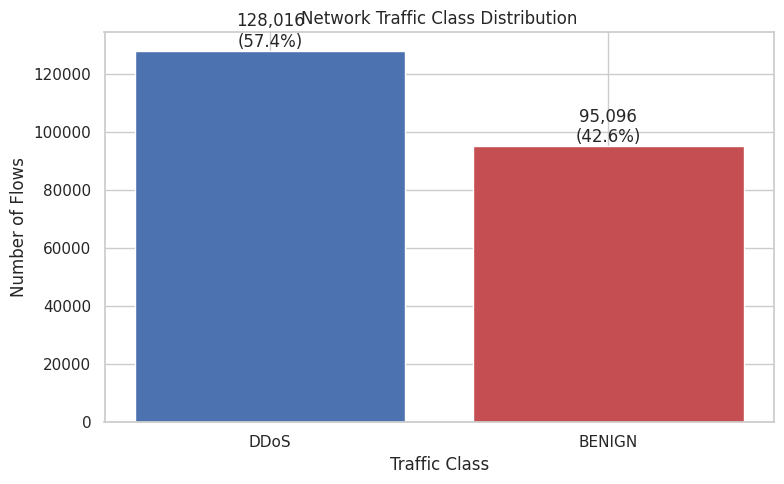

In [41]:
# ============================================================
# Target class distribution (cleaned data)
# ============================================================

import matplotlib.pyplot as plt

target_counts = df[target_column].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    target_counts.index.astype(str),
    target_counts.values,
    color=["#4C72B0", "#C44E52"]
)
for bar, value in zip(bars, target_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}\n({value / target_counts.sum():.1%})",
             ha="center", va="bottom")

plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Flows")

plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# Class-imbalance quantification
# ============================================================
counts = df[target_column].value_counts()
majority, minority = counts.idxmax(), counts.idxmin()

print(f"Majority class : {majority}  ({counts.max():,} flows, {counts.max() / counts.sum():.2%})")
print(f"Minority class : {minority}  ({counts.min():,} flows, {counts.min() / counts.sum():.2%})")
print(f"Imbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")
print(f"Accuracy of a model that ALWAYS predicts '{majority}': {counts.max() / counts.sum():.4f}")
print(f"Rare classes (< 5% of rows): {[c for c, n in counts.items() if n / counts.sum() < 0.05] or 'none'}")

Majority class : DDoS  (128,016 flows, 57.38%)
Minority class : BENIGN  (95,096 flows, 42.62%)
Imbalance ratio (majority : minority) = 1.35 : 1
Accuracy of a model that ALWAYS predicts 'DDoS': 0.5738
Rare classes (< 5% of rows): none


**Interpretation (target).** After cleaning the data contain 128,016 DDoS (57.38%) and 95,096 benign (42.62%) flows: an imbalance ratio of only **1.35 : 1** and no rare class. This is *mild* imbalance, but two consequences remain. (1) Accuracy is not informative on its own — always predicting "DDoS" already scores 0.574 — so the evaluation uses macro-F1 and per-class recall/precision. (2) Real networks are overwhelmingly benign, so this balanced capture is **not** representative of production prevalence (see Limitations).

### 7.2 Numerical features
*Questions: how skewed are the features, and which ones separate the two classes?*

In [43]:
# ============================================================
# Skewness analysis
# ============================================================

skewness = df[numerical_columns].skew()

skewed_features = skewness[
    skewness.abs() > 2
].sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

skewness_summary = pd.DataFrame({
    "Skewness": skewed_features.round(2),
    "Absolute Skewness": skewed_features.abs().round(2)
})

print(
    f"Number of strongly skewed features: "
    f"{len(skewed_features)}"
)

display(skewness_summary)

Number of strongly skewed features: 46


,Skewness,Absolute Skewness
RST Flag Count,90.89,90.89
act_data_pkt_fwd,78.86,78.86
Active Std,77.09,77.09
Flow Bytes/s,73.89,73.89
Total Length of Bwd Packets,69.21,69.21
Total Backward Packets,65.85,65.85
Total Fwd Packets,59.33,59.33
Bwd Packets/s,56.17,56.17
Bwd Header Length,55.96,55.96
Flow IAT Min,55.58,55.58


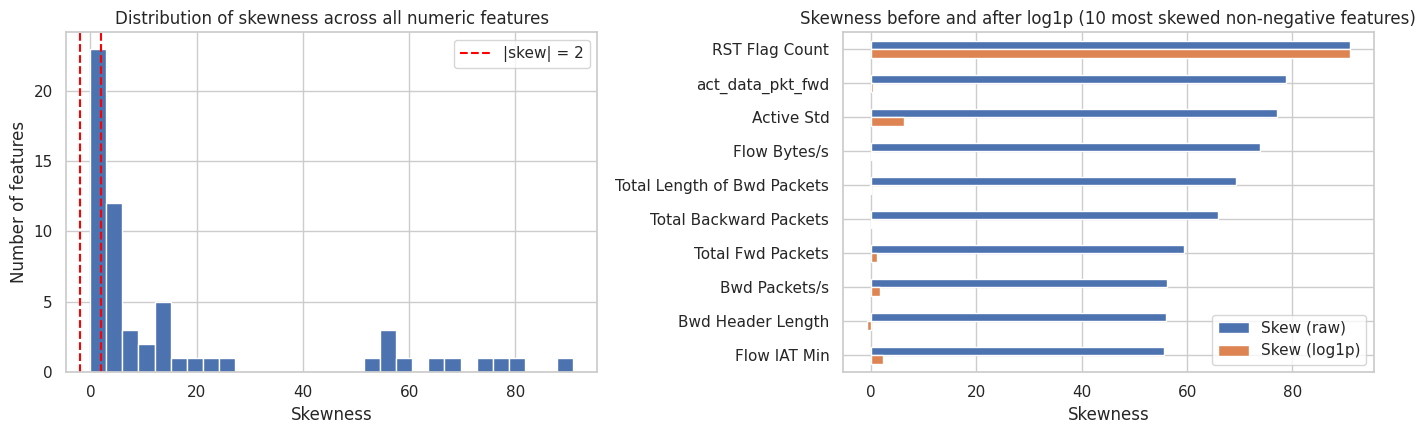

,Skew (raw),Skew (log1p)
RST Flag Count,90.89,90.89
act_data_pkt_fwd,78.86,0.28
Active Std,77.09,6.25
Flow Bytes/s,73.89,0.17
Total Length of Bwd Packets,69.21,-0.17
Total Backward Packets,65.85,0.07
Total Fwd Packets,59.33,1.20
Bwd Packets/s,56.17,1.64
Bwd Header Length,55.96,-0.85
Flow IAT Min,55.58,2.18


In [44]:
# ============================================================
# Skewness visualisation and the effect of a log transform
# ============================================================
skew_values = df[numerical_columns].skew()

# Non-negative features can be log1p-transformed safely
non_negative = [c for c in skew_values.abs().sort_values(ascending=False).index if df[c].min() >= 0]
top_skewed = non_negative[:10]
skew_effect = pd.DataFrame({
    "Skew (raw)": skew_values[top_skewed],
    "Skew (log1p)": np.log1p(df[top_skewed]).skew(),
}).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(skew_values.dropna(), bins=30, color="#4C72B0")
axes[0].axvline(2, color="red", ls="--", label="|skew| = 2")
axes[0].axvline(-2, color="red", ls="--")
axes[0].set_title("Distribution of skewness across all numeric features")
axes[0].set_xlabel("Skewness"); axes[0].set_ylabel("Number of features"); axes[0].legend()

skew_effect.plot(kind="barh", ax=axes[1])
axes[1].set_title("Skewness before and after log1p (10 most skewed non-negative features)")
axes[1].set_xlabel("Skewness"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

display(skew_effect)

**Interpretation (skewness).** 46 features have |skew| > 2, and the most extreme are counts and rates (`Flow Bytes/s`, `Total Backward Packets`, ...) with skewness above 50. A `log1p` transform brings most of them close to symmetric (e.g. `Flow Bytes/s` from 73.9 to 0.17). `RST Flag Count` is unaffected by the transform (it is almost constant) and `Active Std` stays skewed (6.25). This motivates log-scaled plots in EDA and the log transform in the Logistic Regression pipeline; tree models do not need it.

In [45]:
# ============================================================
# Create a stratified EDA sample
# ============================================================

SAMPLE_SIZE = min(10000, len(df))

eda_sample = (
    df.groupby(target_column, group_keys=False)
      .sample(frac=SAMPLE_SIZE / len(df), random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("EDA sample created successfully.")
print(f"Sample size: {len(eda_sample):,} rows")

print("\nClass distribution in sample:")
display(
    eda_sample[target_column]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

EDA sample created successfully.
Sample size: 10,000 rows

Class distribution in sample:


,Percentage
Label,
DDoS,57.38
BENIGN,42.62


In [46]:
# ============================================================
# Rank features by how well they separate the classes (scale-free)
# ============================================================
# The uploaded notebook ranked features by the absolute difference of class medians.
# That favours features measured in huge units (microseconds, bytes) regardless of how
# informative they are. A scale-free measure is used instead: the ROC-AUC of the raw
# feature value as a score for "attack". Separation = 2 * |AUC - 0.5|  (0 = none, 1 = perfect).
is_attack_sample = (eda_sample[target_column] == POSITIVE_CLASS).astype(int)

rows = []
for feature in numerical_columns:
    values = eda_sample[feature]
    values = values.fillna(values.median())
    auc = roc_auc_score(is_attack_sample, values)
    rows.append({"Feature": feature, "AUC (higher value = attack)": auc, "Separation": 2 * abs(auc - 0.5)})

separation = pd.DataFrame(rows).sort_values("Separation", ascending=False).reset_index(drop=True)
top_eda_features = separation.head(10)["Feature"].tolist()

print("Top 10 features by class separation:")
display(separation.head(10).round(3))

Top 10 features by class separation:


,Feature,AUC (higher value = attack),Separation
0,Bwd Packet Length Min,0.209,0.583
1,Fwd Packet Length Max,0.248,0.505
2,Bwd Packet Length Std,0.752,0.504
3,Fwd Packet Length Mean,0.250,0.501
4,Init_Win_bytes_forward,0.741,0.481
5,Fwd IAT Std,0.738,0.475
6,act_data_pkt_fwd,0.725,0.450
7,Fwd IAT Max,0.723,0.445
8,Fwd IAT Mean,0.720,0.440
9,Fwd IAT Total,0.714,0.427


**Interpretation (class separation).** Ranked by a scale-free measure (2·|AUC−0.5|), the most class-separating features are packet-length statistics (`Bwd Packet Length Min`, `Fwd Packet Length Max/Mean`), the initial forward TCP window and forward inter-arrival times. The uploaded notebook ranked features by raw median differences, which would have favoured microsecond-scale columns regardless of their usefulness; this ranking is comparable across features.

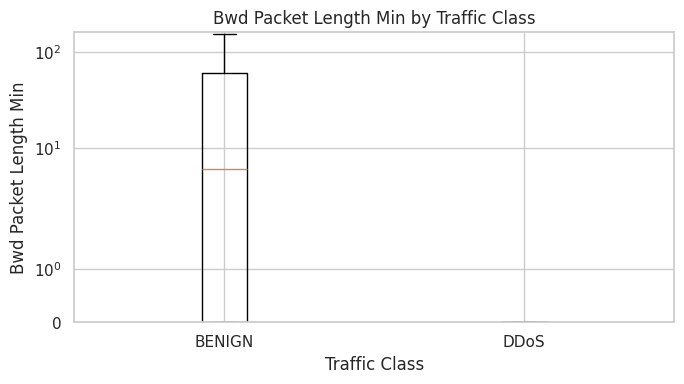

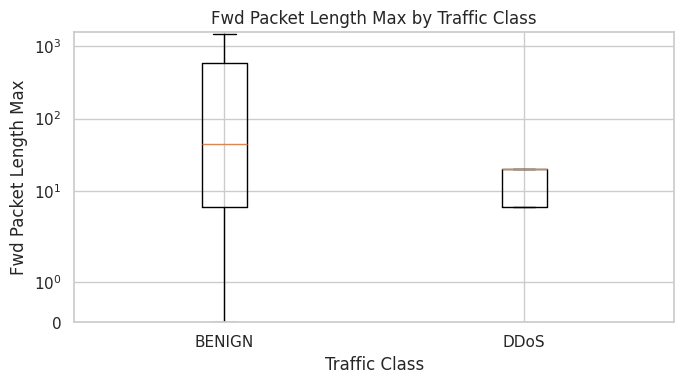

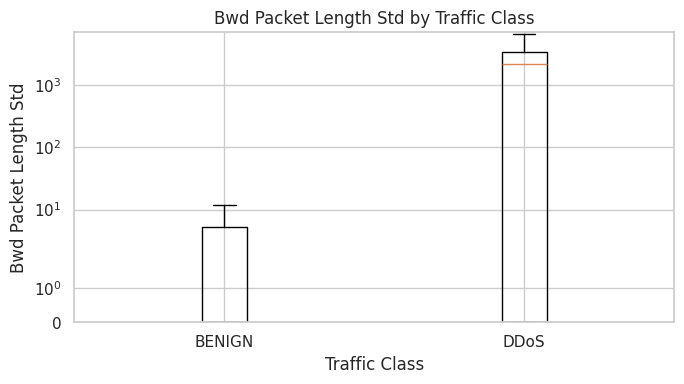

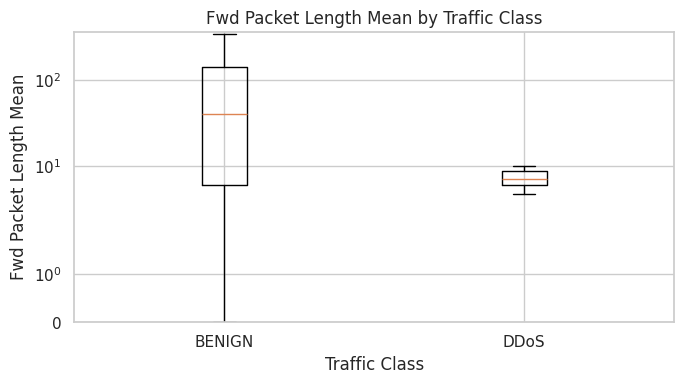

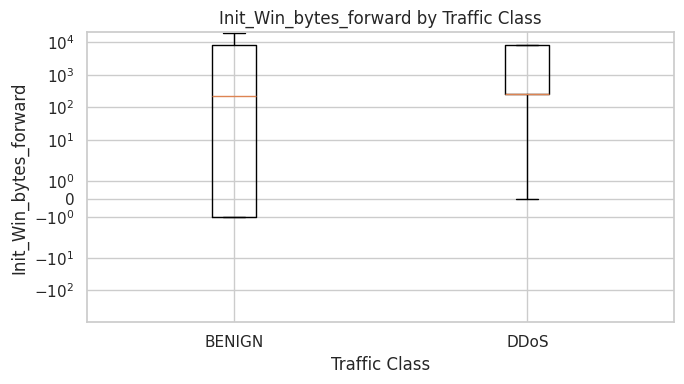

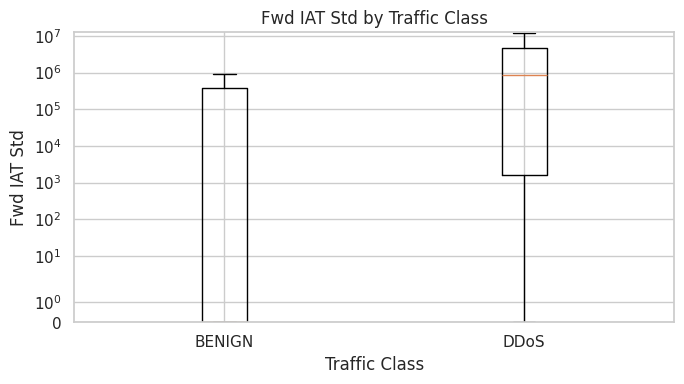

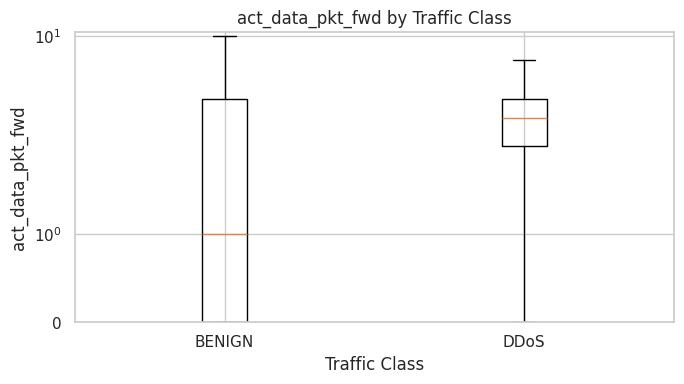

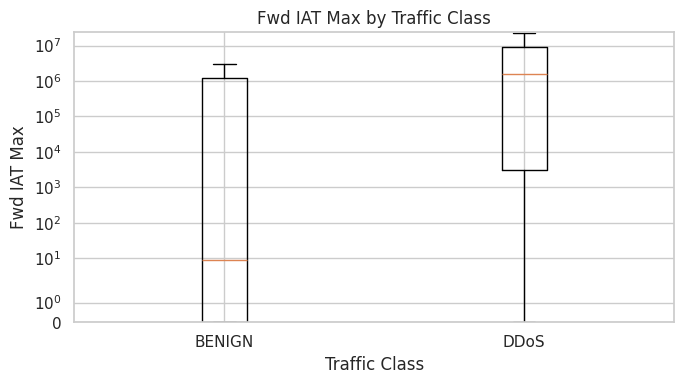

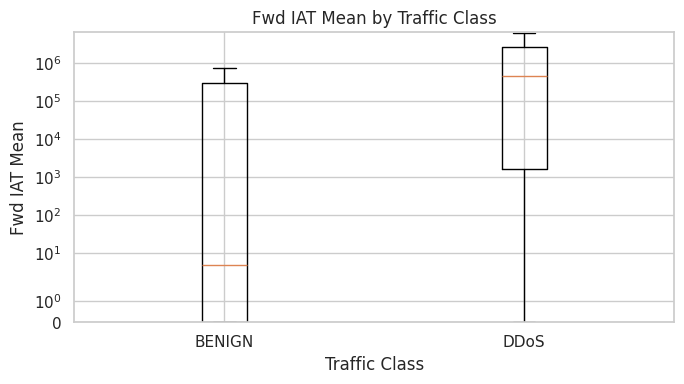

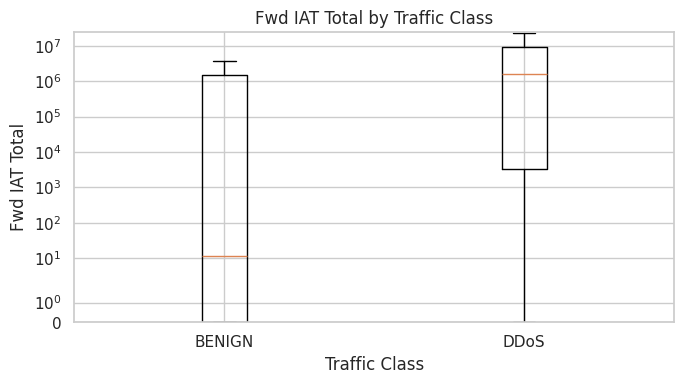

In [47]:
# ============================================================
# Feature distribution by traffic class (box plots)
# ============================================================

import matplotlib.pyplot as plt

for feature in top_eda_features:

    plt.figure(figsize=(7, 4))

    df_plot = eda_sample[[target_column, feature]].copy()
    df_plot[feature] = df_plot[feature].replace(
        [np.inf, -np.inf],
        np.nan
    )
    df_plot = df_plot.dropna()

    classes = df_plot[target_column].unique()

    data = [
        df_plot.loc[
            df_plot[target_column] == cls,
            feature
        ]
        for cls in classes
    ]

    plt.boxplot(data, showfliers=False)
    plt.xticks(range(1, len(classes) + 1), [str(cls) for cls in classes])
    plt.yscale("symlog")
    if min(np.min(d) for d in data) >= 0:
        plt.ylim(bottom=0)

    plt.title(f"{feature} by Traffic Class")
    plt.xlabel("Traffic Class")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

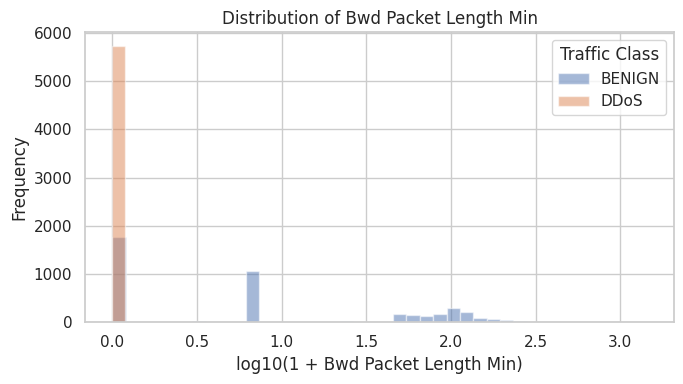

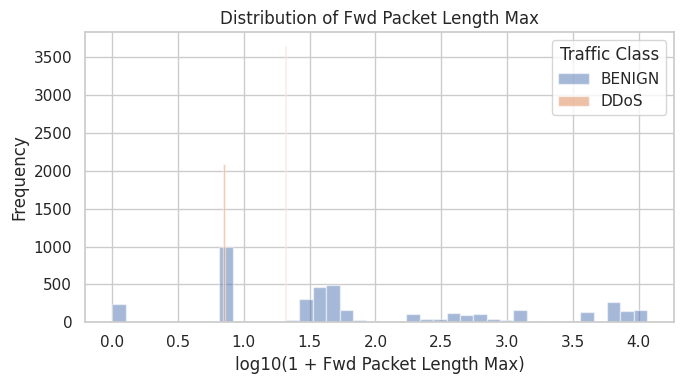

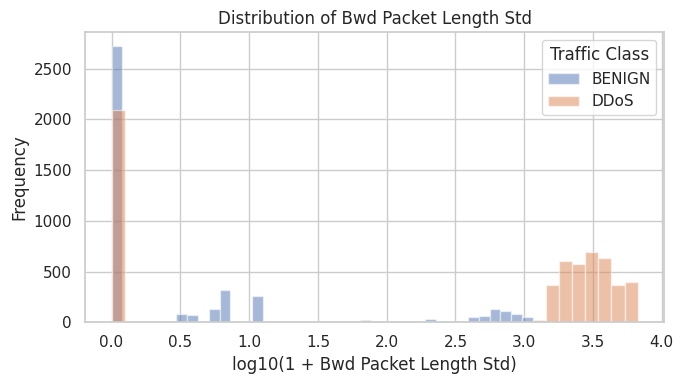

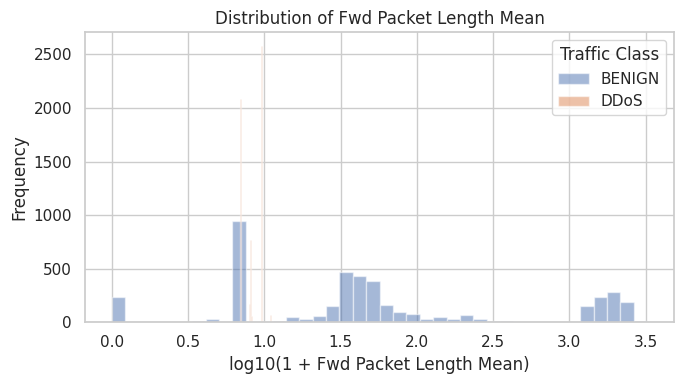

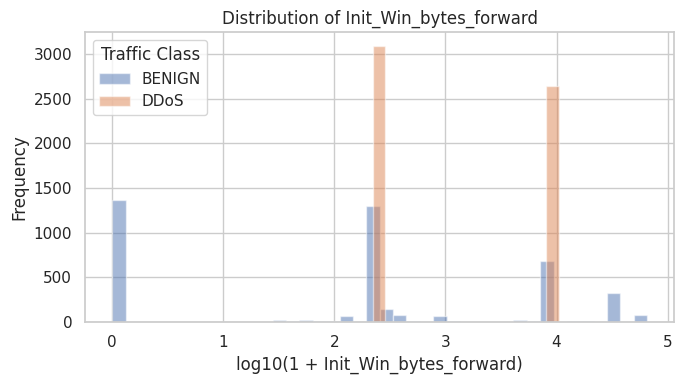

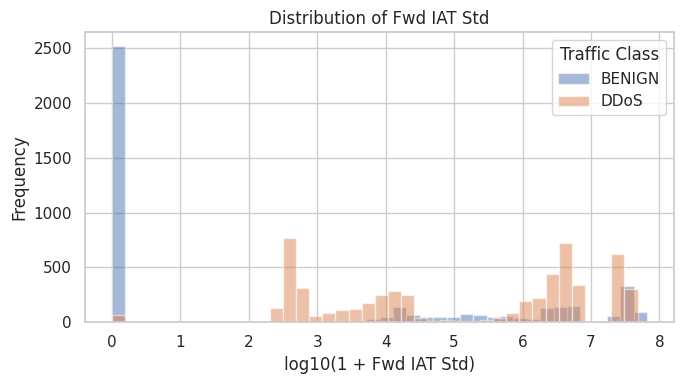

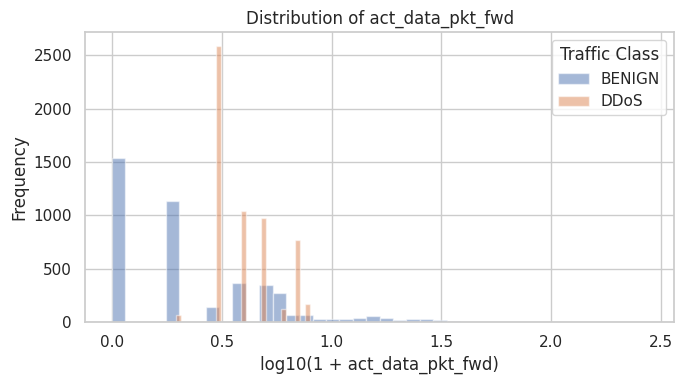

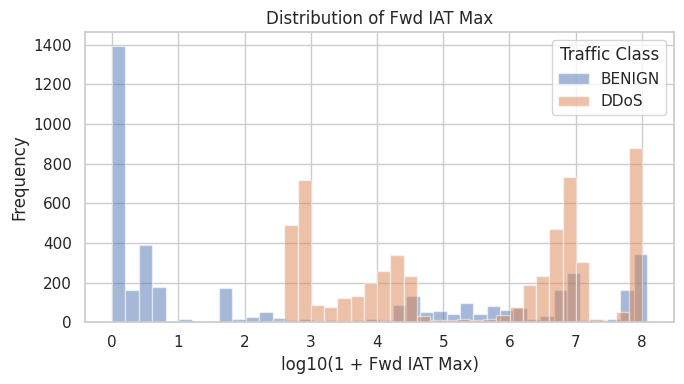

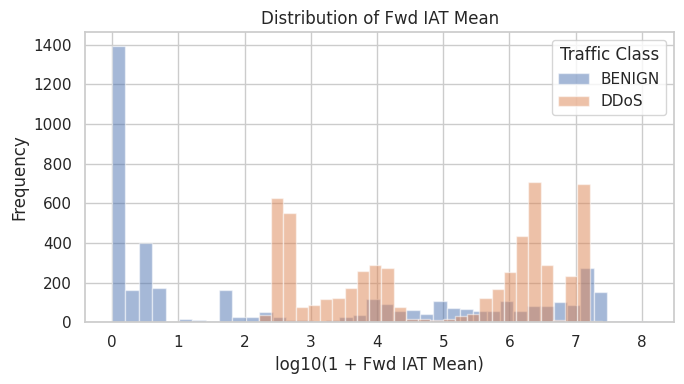

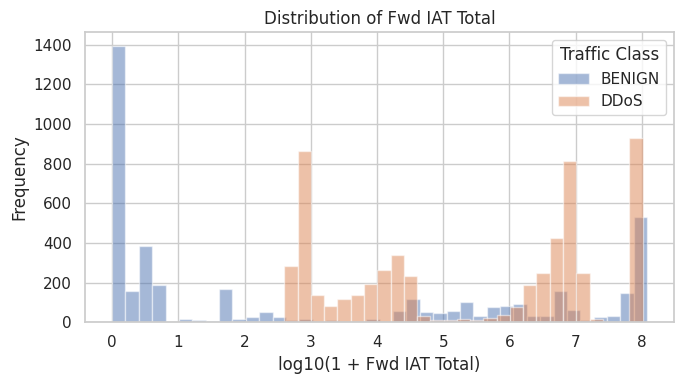

In [48]:
# ============================================================
# Feature distribution by traffic class (log-scaled histograms)
# ============================================================

for feature in top_eda_features:

    plt.figure(figsize=(7, 4))

    for traffic_class in eda_sample[target_column].unique():

        values = eda_sample.loc[
            eda_sample[target_column] == traffic_class,
            feature
        ]

        values = values.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        plt.hist(
            np.log10(values.clip(lower=0) + 1),
            bins=40,
            alpha=0.5,
            label=str(traffic_class)
        )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(f"log10(1 + {feature})")
    plt.ylabel("Frequency")
    plt.legend(title="Traffic Class")

    plt.tight_layout()
    plt.show()

**Interpretation (box plots and histograms).** On a log scale the two classes occupy visibly different regions for the top-ranked features: DDoS flows concentrate in narrow bands (small, uniform forward packets, similar window sizes) while benign flows are spread over several orders of magnitude. The class medians that confirm this are in the next two tables.

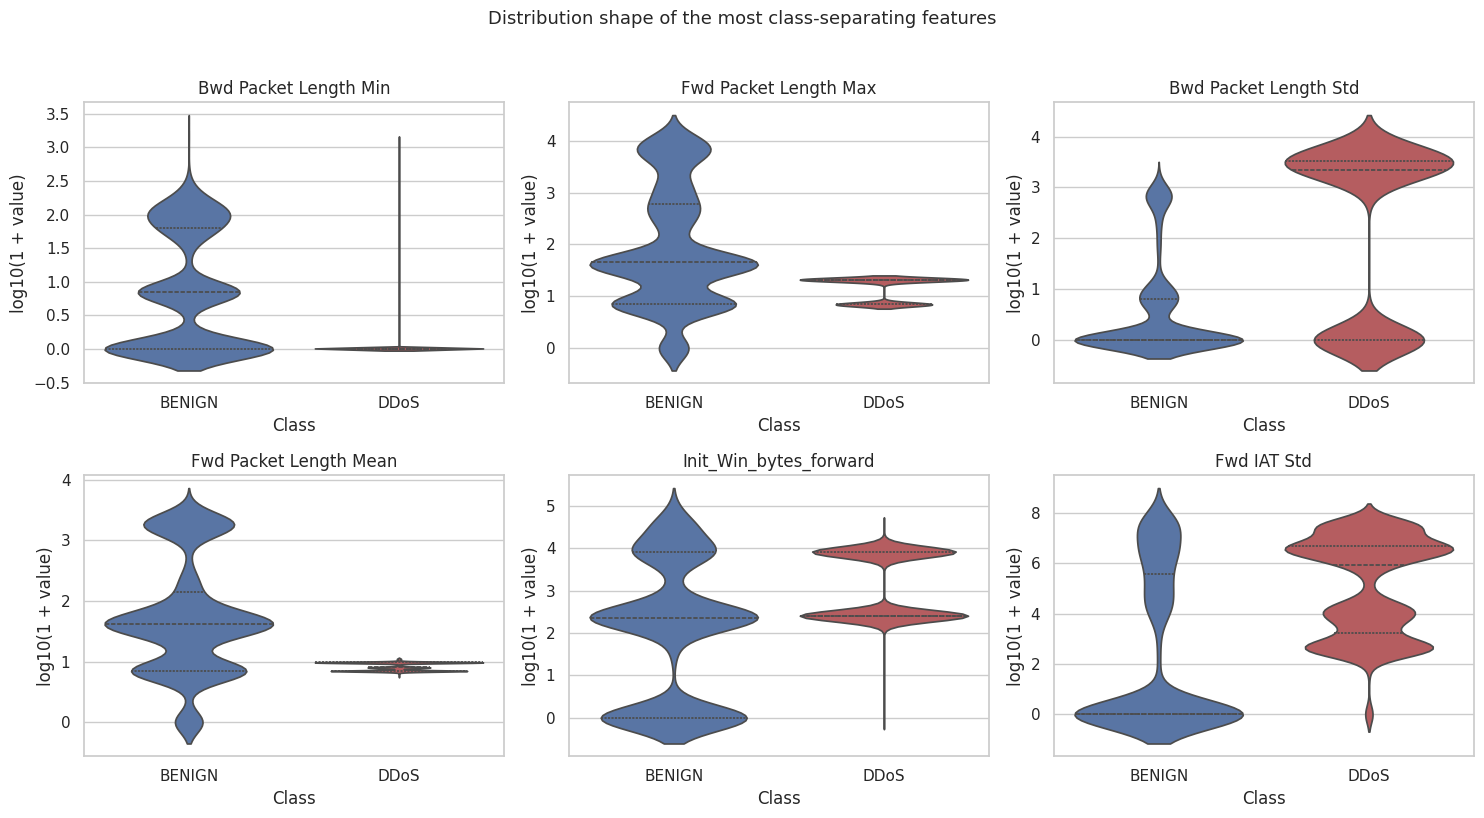

In [49]:
# ============================================================
# Violin plots of the six most separating features (log scale)
# ============================================================
violin_features = top_eda_features[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), violin_features):
    plot_df = pd.DataFrame({
        "Class": eda_sample[target_column],
        "log10(1 + value)": np.log10(eda_sample[feature].clip(lower=0) + 1),
    })
    sns.violinplot(data=plot_df, x="Class", y="log10(1 + value)", hue="Class", inner="quartile",
                   palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
    ax.set_title(feature)
plt.suptitle("Distribution shape of the most class-separating features", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation (violin plots).** The violins make the shape difference explicit: benign traffic is broad and multi-modal (DNS, TLS, web, bulk transfers), DDoS traffic is compact. A compact distribution means a few thresholds on these features already separate most flows, which is why even shallow trees perform well later.

In [50]:
# ============================================================
# Class-wise feature medians
# ============================================================

class_statistics = (
    eda_sample
    .groupby(target_column)[top_eda_features]
    .median()
    .T
)

print("Median value of selected features by traffic class:")
display(class_statistics)

Median value of selected features by traffic class:


Label,BENIGN,DDoS
Bwd Packet Length Min,6.0,0.000000e+00
Fwd Packet Length Max,44.0,2.000000e+01
Bwd Packet Length Std,0.0,2.189773e+03
Fwd Packet Length Mean,40.0,7.000000e+00
Init_Win_bytes_forward,229.0,2.560000e+02
Fwd IAT Std,0.0,8.655014e+05
act_data_pkt_fwd,1.0,3.000000e+00
Fwd IAT Max,9.0,1.625878e+06
Fwd IAT Mean,5.0,4.512769e+05
Fwd IAT Total,11.5,1.626479e+06


**Reading the table.** The medians show the same story in raw units; more precise quantiles are given in the attack-pattern analysis (7.5).

### 7.3 Categorical and low-cardinality features
There are **no categorical features** (only `Label` is non-numeric), so frequency/cardinality analysis of categories is not applicable. The closest equivalent are numeric features with very few distinct values (TCP flags, direction ratios): their cardinality is checked and their link with the target is examined directly.

In [51]:
# ============================================================
# Feature cardinality
# ============================================================

cardinality_summary = pd.DataFrame({
    "Unique Values": df[numerical_columns].nunique(),
    "Unique Percentage": (
        df[numerical_columns].nunique() / len(df) * 100
    ).round(2)
})

cardinality_summary = cardinality_summary.sort_values(
    "Unique Values"
)

print("Features with the lowest number of unique values:")
display(cardinality_summary.head(15))

print("\nFeatures with the highest number of unique values:")
display(cardinality_summary.tail(15))

Features with the lowest number of unique values:


,Unique Values,Unique Percentage
Fwd PSH Flags,2,0.00
RST Flag Count,2,0.00
PSH Flag Count,2,0.00
FIN Flag Count,2,0.00
URG Flag Count,2,0.00
ACK Flag Count,2,0.00
Down/Up Ratio,8,0.00
min_seg_size_forward,8,0.00
Min Packet Length,109,0.05
Fwd Packet Length Min,151,0.07



Features with the highest number of unique values:


,Unique Values,Unique Percentage
Fwd IAT Total,78049,34.98
Fwd IAT Std,91184,40.87
Fwd IAT Mean,95095,42.62
Bwd IAT Max,101379,45.44
Bwd IAT Total,101942,45.69
Bwd IAT Std,113859,51.03
Bwd IAT Mean,117311,52.58
Flow IAT Max,139744,62.63
Bwd Packets/s,144444,64.74
Flow IAT Std,159622,71.54


In [52]:
# ============================================================
# Binary and low-cardinality features
# ============================================================

low_cardinality = []

for feature in numerical_columns:

    unique_count = df[feature].nunique()

    if unique_count <= 10:
        low_cardinality.append({
            "Feature": feature,
            "Unique Values": unique_count
        })

low_cardinality_summary = pd.DataFrame(
    low_cardinality
).sort_values(
    "Unique Values"
)

print(
    f"Number of numerical features with 10 or fewer "
    f"unique values: {len(low_cardinality_summary)}"
)

display(low_cardinality_summary)

Number of numerical features with 10 or fewer unique values: 8


,Feature,Unique Values
0,Fwd PSH Flags,2
1,FIN Flag Count,2
2,RST Flag Count,2
3,PSH Flag Count,2
4,ACK Flag Count,2
5,URG Flag Count,2
6,Down/Up Ratio,8
7,min_seg_size_forward,8


In [53]:
# ============================================================
# Low-cardinality features vs. the target: P(attack | value)
# ============================================================
rows = []
for feature in low_cardinality_summary["Feature"]:
    for value, group in df.groupby(feature):
        rows.append({"Feature": feature, "Value": value, "Flows": len(group),
                     "Attack share (%)": round((group[target_column] == POSITIVE_CLASS).mean() * 100, 2)})
flag_vs_target = pd.DataFrame(rows)
display(flag_vs_target)

,Feature,Value,Flows,Attack share (%)
0,Fwd PSH Flags,0,215651,59.36
1,Fwd PSH Flags,1,7461,0.00
2,FIN Flag Count,0,222752,57.46
3,FIN Flag Count,1,360,7.50
4,RST Flag Count,0,223085,57.38
5,RST Flag Count,1,27,0.00
6,PSH Flag Count,0,143839,48.55
7,PSH Flag Count,1,79273,73.40
8,ACK Flag Count,0,109825,52.83
9,ACK Flag Count,1,113287,61.79


**Interpretation (low-cardinality features).** Several flag-like features are almost class-pure: flows with `URG Flag Count = 1` (31,704 flows) are DDoS only 0.01% of the time, `Fwd PSH Flags = 1` and `RST Flag Count = 1` never occur in DDoS flows, and `min_seg_size_forward = 20` covers 197,537 flows of which 64.8% are attacks while every other value is benign-only. These are strong but coarse indicators; they are also properties of the capture's hosts and tools, which matters for generalisation.

### 7.4 Feature relationships — correlation, multicollinearity, redundancy
*Questions: which features are redundant, and which relate to the target?*
Highly correlated features are **not** blindly removed: tree-based models (the main models here) are insensitive to correlated inputs, whereas Logistic Regression is not. The consequence for feature selection is discussed in Part 11.

In [54]:
# ============================================================
# Highly correlated feature pairs (|r| >= 0.95)
# ============================================================

correlation_matrix = df[numerical_columns].corr()

high_correlation_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) >= 0.95:
            high_correlation_pairs.append({
                "Feature 1": correlation_matrix.columns[i],
                "Feature 2": correlation_matrix.columns[j],
                "Correlation": round(correlation, 3)
            })

high_correlation_summary = pd.DataFrame(high_correlation_pairs)

print(
    f"Number of feature pairs with |correlation| >= 0.95: "
    f"{len(high_correlation_summary)}"
)

if not high_correlation_summary.empty:
    display(
        high_correlation_summary.sort_values(
            "Correlation",
            key=lambda x: x.abs(),
            ascending=False
        )
    )
else:
    print("No highly correlated feature pairs found.")

Number of feature pairs with |correlation| >= 0.95: 30


,Feature 1,Feature 2,Correlation
10,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000
26,Packet Length Mean,Average Packet Size,0.999
18,Flow IAT Max,Idle Max,0.997
0,Flow Duration,Fwd IAT Total,0.997
17,Flow IAT Max,Fwd IAT Max,0.995
7,Bwd Packet Length Max,Bwd Packet Length Std,0.993
21,Fwd IAT Max,Idle Max,0.993
5,Fwd Packet Length Max,Fwd Packet Length Std,0.992
12,Flow Packets/s,Fwd Packets/s,0.984
24,Max Packet Length,Packet Length Std,0.984


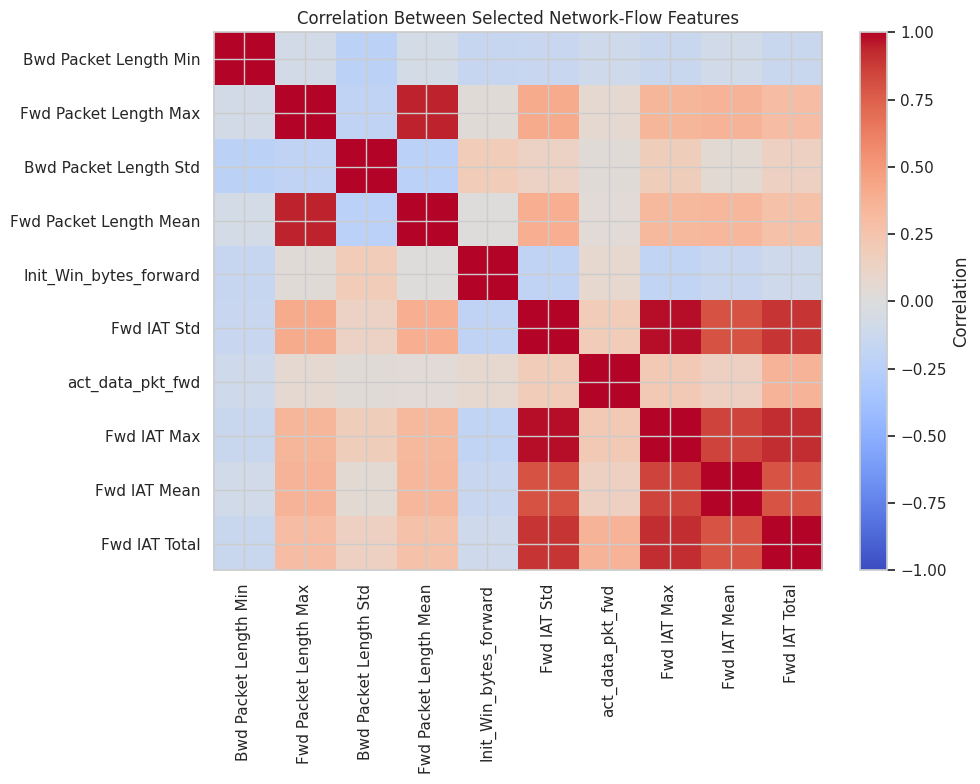

In [55]:
# ============================================================
# Correlation among the most class-separating features
# ============================================================

import matplotlib.pyplot as plt

correlation_data = eda_sample[top_eda_features].copy()

correlation_data = correlation_data.replace(
    [np.inf, -np.inf],
    np.nan
)

correlation_matrix_eda = correlation_data.corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix_eda,
    aspect="auto",
    cmap="coolwarm", vmin=-1, vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(top_eda_features)),
    top_eda_features,
    rotation=90
)

plt.yticks(
    range(len(top_eda_features)),
    top_eda_features
)

plt.title("Correlation Between Selected Network-Flow Features")

plt.tight_layout()
plt.show()

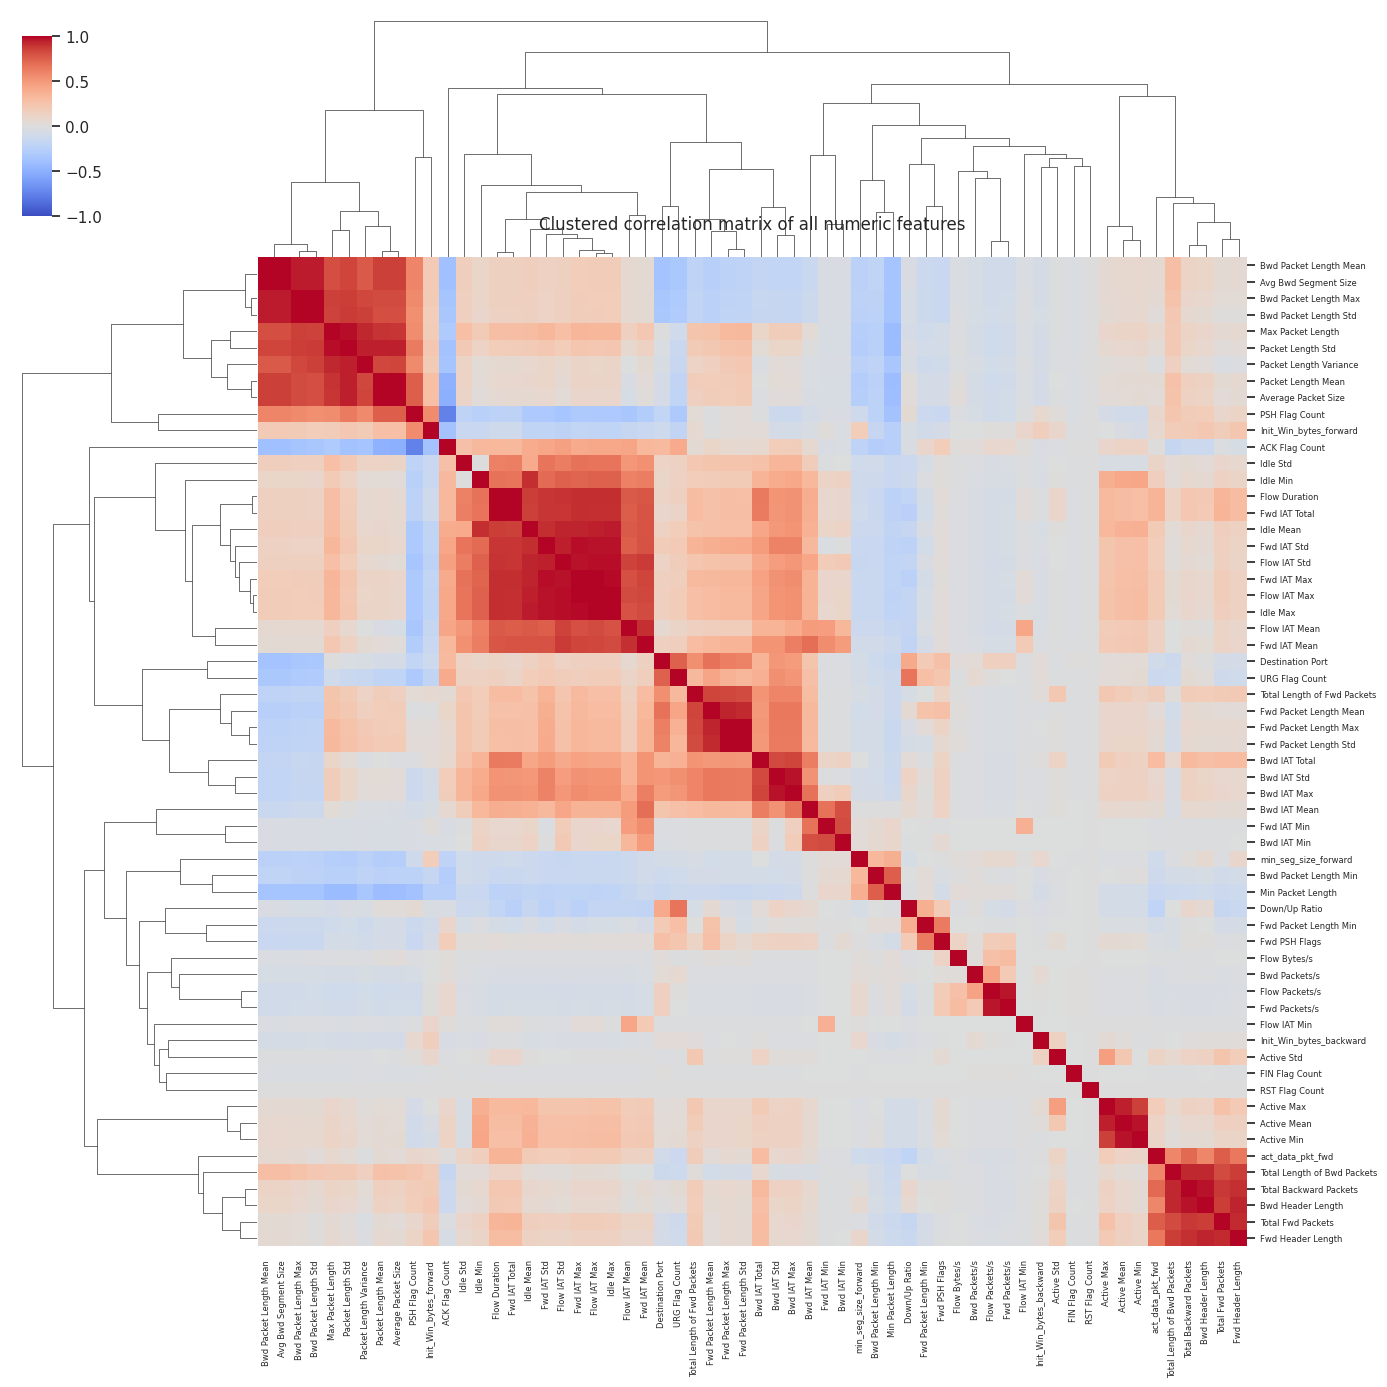

Features with a |r| >= 0.95 partner: 26 of 60


In [56]:
# ============================================================
# Clustered correlation heatmap of all numeric features
# ============================================================
corr_arr = eda_sample[numerical_columns].corr().fillna(0).to_numpy().copy()
np.fill_diagonal(corr_arr, 1.0)
corr_full = pd.DataFrame(corr_arr, index=numerical_columns, columns=numerical_columns)

grid = sns.clustermap(corr_full, cmap="coolwarm", vmin=-1, vmax=1, figsize=(15, 15),
                      xticklabels=True, yticklabels=True, cbar_pos=(0.02, 0.85, 0.02, 0.12))
grid.ax_heatmap.set_title("Clustered correlation matrix of all numeric features", pad=20)
plt.setp(grid.ax_heatmap.get_xticklabels(), fontsize=6)
plt.setp(grid.ax_heatmap.get_yticklabels(), fontsize=6)
plt.show()

# How many features take part in at least one |r| >= 0.95 relationship?
abs_corr = np.abs(corr_arr)
np.fill_diagonal(abs_corr, 0)
in_pair = (abs_corr >= 0.95).any(axis=1)
print(f"Features with a |r| >= 0.95 partner: {in_pair.sum()} of {len(numerical_columns)}")

**Interpretation (feature relationships).** In the cleaned data 30 feature pairs have |r| ≥ 0.95 and 26 of the 60 features have at least one such partner. The blocks visible in the clustered heatmap are intuitive: packet-length statistics (mean/max/std), the inter-arrival-time family (`Flow IAT Max`, `Fwd IAT Max`, `Idle Max`), and counts with header lengths. This is real multicollinearity. It does not hurt tree-based models' predictions, but (a) it dilutes individual feature-importance scores and (b) it would destabilise the Logistic Regression coefficients — hence the grouped importance analysis in Part 20.

In [57]:
# ============================================================
# Linear relationship of each feature with the target
# ============================================================

# Create a temporary numeric version of the target
target_numeric = (
    df[target_column]
    .astype("category")
    .cat.codes
)

# Calculate correlation with the target
target_correlation = df[numerical_columns].corrwith(
    target_numeric
)

target_correlation = target_correlation.sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

target_correlation_summary = pd.DataFrame({
    "Correlation With Target": target_correlation.round(4),
    "Absolute Correlation": target_correlation.abs().round(4)
})

print("Top numerical features by absolute correlation with the target:")

display(
    target_correlation_summary.head(20)
)

Top numerical features by absolute correlation with the target:


,Correlation With Target,Absolute Correlation
Bwd Packet Length Mean,0.6000,0.6000
Avg Bwd Segment Size,0.6000,0.6000
Bwd Packet Length Max,0.5738,0.5738
Bwd Packet Length Std,0.5728,0.5728
Destination Port,-0.5204,0.5204
URG Flag Count,-0.4721,0.4721
Packet Length Mean,0.4483,0.4483
Average Packet Size,0.4476,0.4476
Packet Length Std,0.4377,0.4377
Min Packet Length,-0.4226,0.4226


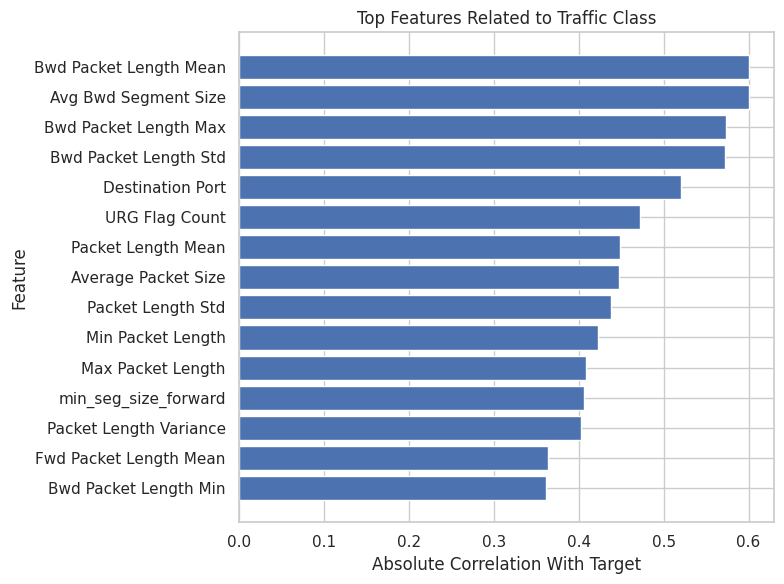

In [58]:
# ============================================================
# Top features by correlation with the target
# ============================================================

top_correlation = (
    target_correlation
    .abs()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(8, 6))

plt.barh(
    top_correlation.index,
    top_correlation.values
)

plt.title("Top Features Related to Traffic Class")
plt.xlabel("Absolute Correlation With Target")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**Interpretation.** The strongest linear associations with the label come from backward packet length statistics (|r| ≈ 0.57–0.60) and `Destination Port` (−0.52), followed by `URG Flag Count` and packet-size features. Linear correlation understates the non-linear separation seen elsewhere, which is why mutual information is used for selection.

In [59]:
# ============================================================
# Variance check after cleaning
# ============================================================

variance_summary = (
    df[numerical_columns]
    .var()
    .sort_values()
)

print("Features with the lowest variance:")
display(
    variance_summary.head(15).to_frame("Variance")
)

print("\nFeatures with the highest variance:")
display(
    variance_summary.tail(10).to_frame("Variance")
)

Features with the lowest variance:


,Variance
RST Flag Count,0.000121
FIN Flag Count,0.001611
Fwd PSH Flags,0.032322
URG Flag Count,0.121907
PSH Flag Count,0.229065
ACK Flag Count,0.249941
Down/Up Ratio,2.066977
min_seg_size_forward,16.803784
act_data_pkt_fwd,152.237515
Total Fwd Packets,240.552435



Features with the highest variance:


,Variance
Bwd IAT Max,2.645886e+14
Flow Bytes/s,2.872092e+14
Idle Min,3.971958e+14
Idle Mean,4.819193e+14
Bwd IAT Total,4.885096e+14
Flow IAT Max,7.192298e+14
Idle Max,7.313285e+14
Fwd IAT Max,7.625313e+14
Flow Duration,1.002374e+15
Fwd IAT Total,1.008044e+15


### 7.5 Attack-pattern analysis
*Question: do DDoS flows look different from benign flows in interpretable network-flow features?*

In [60]:
# ============================================================
# Interpretable "attack signature": class medians of key features
# ============================================================
signature_candidates = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Packet Length Mean", "Average Packet Size",
    "Bwd Packet Length Mean", "Flow IAT Mean", "Flow IAT Max",
    "Init_Win_bytes_forward", "Init_Win_bytes_backward",
    "ACK Flag Count", "PSH Flag Count", "URG Flag Count", "Down/Up Ratio", "Idle Mean",
]
present = [c for c in signature_candidates if c in df.columns]

signature = df.groupby(target_column)[present].median().T
benign_name = [c for c in signature.columns if c != POSITIVE_CLASS][0]
signature["Ratio DDoS / benign"] = (signature[POSITIVE_CLASS] / signature[benign_name].replace(0, np.nan)).round(2)
signature = signature.join(separation.set_index("Feature")[["Separation"]].round(3))
display(signature.sort_values("Separation", ascending=False))

,BENIGN,DDoS,Ratio DDoS / benign,Separation
Init_Win_bytes_forward,229.000000,2.560000e+02,1.12,0.481
Total Length of Fwd Packets,70.000000,2.600000e+01,0.37,0.388
Total Fwd Packets,2.000000,4.000000e+00,2.00,0.382
Average Packet Size,78.500000,8.976154e+02,11.43,0.359
Packet Length Mean,61.727273,8.335000e+02,13.50,0.339
URG Flag Count,0.000000,0.000000e+00,NaN,0.338
Flow Packets/s,21.878655,2.589220e+00,0.12,0.319
Bwd Packet Length Mean,13.000000,1.934500e+03,148.81,0.317
Flow IAT Mean,66329.000000,4.893305e+05,7.38,0.316
Flow IAT Max,170644.500000,1.876606e+06,11.00,0.306


**Interpretation (attack pattern).** Compared with benign flows, DDoS flows have (medians): a much larger backward volume (`Total Length of Bwd Packets` 11,601 vs 62 bytes; `Bwd Packet Length Mean` 1,934 vs 13) with **smaller** forward volume (26 vs 70 bytes); larger average packets (898 vs 78 bytes); longer duration (1.88 s vs 0.22 s) but a **lower** packet rate (2.6 vs 21.9 packets/s); and a `Down/Up Ratio` of 0 versus 1. Read together: tiny, uniform requests answered by large server responses at a modest per-flow rate — consistent with an HTTP flood against a web server. These patterns are *consistent with* that scenario, not proof of it. Because a distributed flood is made of many such flows, each flow looks individually unremarkable on rate features (`Flow Packets/s` separates poorly), which is why packet-size features dominate.

### 7.6 Outlier analysis

**Why outliers need care here.** In network traffic, extreme values are often *the signal*: a flood produces huge packet rates, a long-lived flow produces huge durations. Deleting every statistical outlier could delete exactly the attacks we want to find. The analysis therefore asks three questions for every extreme value:

1. **Detect** — how many values are extreme (IQR fences, percentiles, z-scores) and in which features?
2. **Interpret** — is the extreme value a *legitimate network event*, a *genuine attack pattern*, or a *measurement error*?
3. **Decide and verify** — keep, cap, transform or remove? Then check that the decision did no harm.

Physically *impossible* values (negative durations) were already handled in Part 6; this section deals with values that are merely *extreme but possible*.

In [61]:
# ============================================================
# IQR outlier detection
# ============================================================

outlier_results = []

for feature in numerical_columns:

    values = df[feature].replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": (
            outlier_count / len(values) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary = outlier_summary.sort_values(
    "Outlier Percentage",
    ascending=False
)

display(
    outlier_summary.head(20).round(2)
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Destination Port,80.00,80.00,0.00,80.00,80.00,86550,38.79
14,Flow Bytes/s,11.83,19704.84,19693.01,-29527.69,49244.36,44627,20.00
54,Active Max,0.00,1972.00,1972.00,-2958.00,4930.00,43667,19.57
52,Active Mean,0.00,1972.00,1972.00,-2958.00,4930.00,43667,19.57
55,Active Min,0.00,1966.00,1966.00,-2949.00,4915.00,43573,19.53
34,Bwd Packets/s,0.04,20.33,20.29,-30.40,50.78,39515,17.71
15,Flow Packets/s,0.61,65.02,64.40,-96.00,161.62,38960,17.46
33,Fwd Packets/s,0.42,30.54,30.13,-44.77,75.73,38692,17.34
1,Flow Duration,81642.75,8957858.75,8876216.00,-13232681.25,22272182.75,37415,16.77
4,Total Length of Fwd Packets,26.00,62.00,36.00,-28.00,116.00,37381,16.75


**Detection result.** Many features have 15–20% of values outside the IQR fences (e.g. `Flow Bytes/s` 20.0%, `Flow Duration` 16.8%, `Active Mean` 19.6%). That is far too many to be "errors" and is a signature of heavy-tailed traffic. `Destination Port` is flagged for 38.8% of rows only because its IQR is 0 (most flows use port 80), a limitation of the IQR rule, not a data problem.

Features selected for visual outlier inspection:
- Destination Port
- Flow Bytes/s
- Active Max
- Active Mean
- Active Min
- Bwd Packets/s


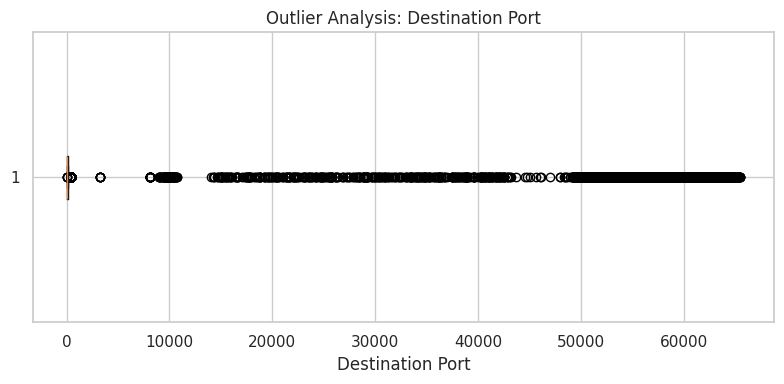

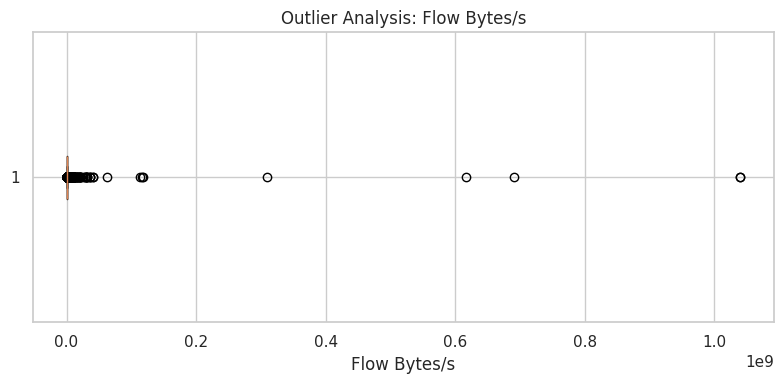

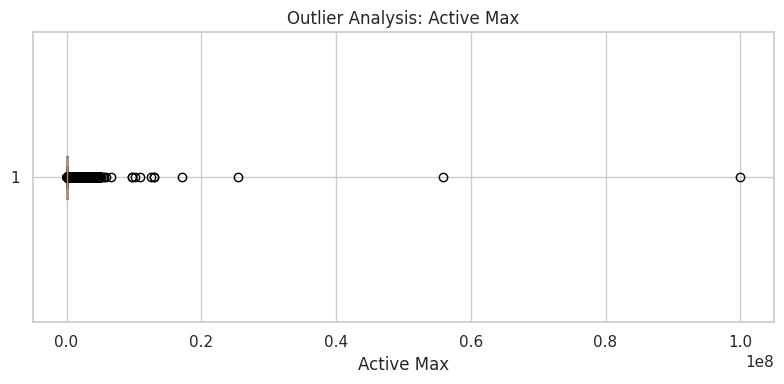

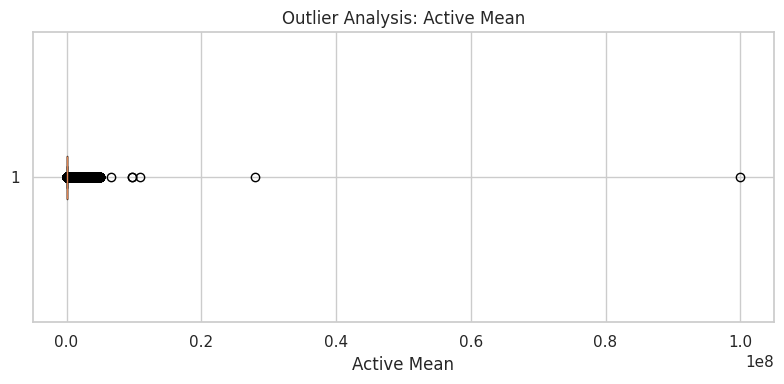

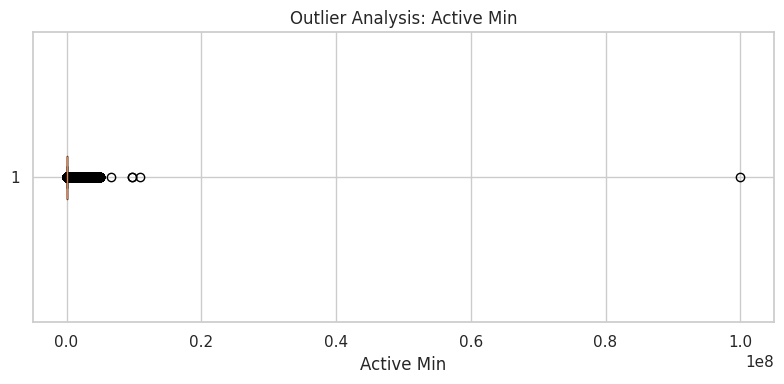

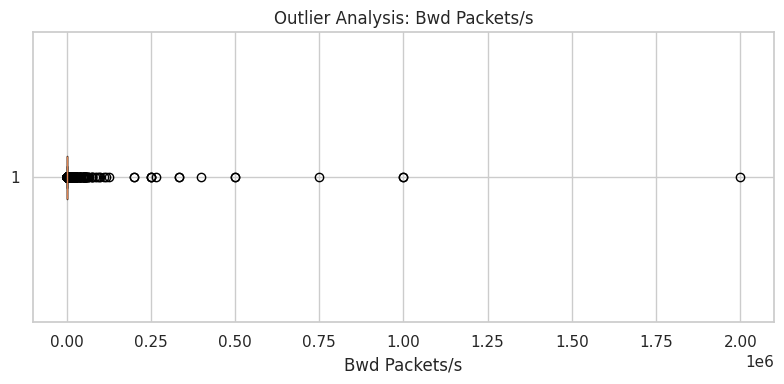

In [62]:
# ============================================================
# Visual outlier inspection (box plots)
# ============================================================

top_outlier_features = (
    outlier_summary
    .head(6)["Feature"]
    .tolist()
)

print("Features selected for visual outlier inspection:")
for feature in top_outlier_features:
    print(f"- {feature}")

for feature in top_outlier_features:

    values = eda_sample[feature].replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    plt.figure(figsize=(8, 4))

    plt.boxplot(
        values,
        vert=False,
        showfliers=True
    )

    plt.title(f"Outlier Analysis: {feature}")
    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

In [63]:
# ============================================================
# Outlier patterns by traffic class (medians and maxima)
# ============================================================

outlier_class_summary = []

for feature in top_outlier_features:

    for traffic_class in eda_sample[target_column].unique():

        values = eda_sample.loc[
            eda_sample[target_column] == traffic_class,
            feature
        ]

        values = values.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        if len(values) > 0:
            outlier_class_summary.append({
                "Feature": feature,
                "Traffic Class": traffic_class,
                "Median": values.median(),
                "Maximum": values.max()
            })

outlier_class_summary = pd.DataFrame(
    outlier_class_summary
)

display(
    outlier_class_summary.round(2)
)

,Feature,Traffic Class,Median,Maximum
0,Destination Port,BENIGN,443.00,6.549700e+04
1,Destination Port,DDoS,80.00,8.000000e+01
2,Flow Bytes/s,BENIGN,1754.16,1.040000e+09
3,Flow Bytes/s,DDoS,160.50,2.260000e+07
4,Active Max,BENIGN,0.00,1.000000e+08
5,Active Max,DDoS,0.00,4.973036e+06
6,Active Mean,BENIGN,0.00,1.000000e+08
7,Active Mean,DDoS,0.00,4.973036e+06
8,Active Min,BENIGN,0.00,1.000000e+08
9,Active Min,DDoS,0.00,4.973036e+06


In [64]:
# ============================================================
# Percentile profile and z-scores of the features with most IQR outliers
# ============================================================
focus_features = outlier_summary.head(12)["Feature"].tolist()

profile = df[focus_features].quantile([0.50, 0.99, 0.999, 1.0]).T
profile.columns = ["Median", "P99", "P99.9", "Maximum"]
profile["Max / P99"] = (profile["Maximum"] / profile["P99"].replace(0, np.nan)).round(1)

z = (df[focus_features] - df[focus_features].mean()) / df[focus_features].std()
profile["|z| > 3 (%)"] = ((z.abs() > 3).mean() * 100).round(2)
profile["|z| > 5 (%)"] = ((z.abs() > 5).mean() * 100).round(2)
display(profile.round(2))

,Median,P99,P99.9,Maximum,Max / P99,|z| > 3 (%),|z| > 5 (%)
Destination Port,80.00,6.383380e+04,6.534089e+04,6.553200e+04,1.0,0.00,0.00
Flow Bytes/s,931.05,4.000000e+06,4.130000e+07,2.070000e+09,517.5,0.08,0.06
Active Max,0.00,4.216581e+06,6.927202e+06,1.000000e+08,23.7,3.05,0.45
Active Mean,0.00,4.139468e+06,4.969781e+06,1.000000e+08,24.2,3.17,0.87
Active Min,0.00,4.128958e+06,4.939783e+06,1.000000e+08,24.2,3.17,1.02
Bwd Packets/s,1.43,1.960784e+04,1.666667e+05,2.000000e+06,102.0,0.21,0.13
Flow Packets/s,4.97,5.000000e+05,2.000000e+06,3.000000e+06,6.0,1.20,0.92
Fwd Packets/s,2.23,5.000000e+05,2.000000e+06,3.000000e+06,6.0,1.17,0.88
Flow Duration,1536491.00,1.158764e+08,1.192163e+08,1.199999e+08,1.0,1.48,0.00
Total Length of Fwd Packets,30.00,1.161300e+04,1.846700e+04,1.830120e+05,15.8,6.65,0.12


**Percentile / z-score view.** Beyond P99 the tails explode (e.g. `Flow Bytes/s` maximum is 517× its 99th percentile, `Bwd Packets/s` 102×), yet |z| > 5 affects at most about 1% of flows even in the worst features. Duration-type features are bounded (maximum ≈ 1.2e8 µs = 120 s, a flow-timeout value) so their extremes are a genuine ceiling, not noise. The very large rate values arise when a flow lasts only microseconds; they are mathematically correct outputs of the tool, not corrupt records.

In [65]:
# ============================================================
# Are the extreme values linked to a class? (informative vs. noise)
# ============================================================
bounds = outlier_summary.set_index("Feature")[["Lower Bound", "Upper Bound"]]

rate_rows, flag_matrix = [], pd.DataFrame(index=df.index)
for feature in numerical_columns:
    is_outlier = (df[feature] < bounds.loc[feature, "Lower Bound"]) | (df[feature] > bounds.loc[feature, "Upper Bound"])
    flag_matrix[feature] = is_outlier
    if feature in focus_features:
        rates = is_outlier.groupby(df[target_column]).mean() * 100
        rate_rows.append({"Feature": feature, **{f"Outlier rate {k} (%)": round(v, 2) for k, v in rates.items()}})

display(pd.DataFrame(rate_rows))

per_row = flag_matrix.sum(axis=1)
print("\nNumber of IQR-outlier features per flow, by class:")
display(per_row.groupby(df[target_column]).describe().round(2))
print("Share of flows that are an outlier in >= 10 features:")
display(((per_row >= 10).groupby(df[target_column]).mean() * 100).round(2).to_frame("% of flows"))

,Feature,Outlier rate BENIGN (%),Outlier rate DDoS (%)
0,Destination Port,91.01,0.00
1,Flow Duration,16.33,17.10
2,Total Length of Fwd Packets,39.31,0.00
3,Flow Bytes/s,25.59,15.85
4,Flow Packets/s,31.10,7.33
5,Fwd IAT Total,16.07,17.17
6,Fwd Header Length,14.50,17.29
7,Fwd Packets/s,32.76,5.89
8,Bwd Packets/s,26.26,11.36
9,Active Mean,30.37,11.55



Number of IQR-outlier features per flow, by class:


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
BENIGN,95096.0,9.98,6.58,0.0,5.0,8.0,10.0,32.0
DDoS,128016.0,3.34,4.99,0.0,0.0,1.0,4.0,18.0


Share of flows that are an outlier in >= 10 features:


,% of flows
Label,
BENIGN,34.37
DDoS,17.15


**Interpretation (are outliers legitimate behaviour or errors?).** This is the key evidence. Benign flows are the *more* extreme class: they are IQR-outliers in on average 10.0 features per flow versus 3.3 for DDoS flows, and 34.4% of benign flows are outliers in ≥ 10 features versus 17.2% of DDoS flows. Extreme values therefore reflect the **diversity of normal traffic** (large downloads, long-lived sessions, very short DNS exchanges), not a corrupted measurement and not a feature unique to attacks. The attack class is the *regular* one. Removing outliers would mostly remove legitimate benign behaviour and make the model less able to recognise unusual-but-harmless traffic (more false alarms).

**Outlier decision (documented before modelling).**
Outliers are **retained unchanged** for the tree-based models and **log-transformed inside the Logistic Regression pipeline only**. No rows are removed and no values are capped. The evidence for this is in the interpretation above and is verified numerically in Part 11.1 (decision trees give identical predictions on raw and log-transformed inputs; Logistic Regression is measured with and without the transform).

## 8. Feature engineering

Only features with a reason, a network interpretation, a clear implementation **and** evidence of usefulness are created.

| Feature | Reason / interpretation | Implementation |
|---|---|---|
| `Fwd_Bwd_Packet_Ratio` | Traffic **asymmetry**: a flood sends many requests and receives few (or no) answers, ordinary sessions are more balanced | `Total Fwd Packets / (Total Backward Packets + 1)` |
| `Fwd_Bwd_Byte_Ratio` | Same asymmetry measured in bytes | `Total Length of Fwd Packets / (Total Length of Bwd Packets + 1)` |

The `+1` avoids division by zero (flows without any reply are common and meaningful). Both features are computed row by row from two columns of the same row, so they use no information from other rows and cannot leak across the split. CICFlowMeter already supplies rates, means, standard deviations and a `Down/Up Ratio`, so **no further features are justified**; additional log or rate columns would only duplicate existing information (tree models are invariant to monotonic transforms).

In [66]:
# ============================================================
# Create traffic-direction ratio features
# ============================================================

# Create meaningful traffic-direction ratios

df["Fwd_Bwd_Packet_Ratio"] = (
    df["Total Fwd Packets"] /
    (df["Total Backward Packets"] + 1)
)

df["Fwd_Bwd_Byte_Ratio"] = (
    df["Total Length of Fwd Packets"] /
    (df["Total Length of Bwd Packets"] + 1)
)

# Add the new features to our numerical feature list
numerical_columns.extend([
    "Fwd_Bwd_Packet_Ratio",
    "Fwd_Bwd_Byte_Ratio"
])

print("New features created:")
print("- Fwd_Bwd_Packet_Ratio")
print("- Fwd_Bwd_Byte_Ratio")

print("\nUpdated number of numerical features:")
print(len(numerical_columns))

New features created:
- Fwd_Bwd_Packet_Ratio
- Fwd_Bwd_Byte_Ratio

Updated number of numerical features:
62


In [67]:
# ============================================================
# Verify engineered features
# ============================================================

engineered_features = [
    "Fwd_Bwd_Packet_Ratio",
    "Fwd_Bwd_Byte_Ratio"
]

verification = pd.DataFrame({
    "Missing Values": df[engineered_features].isnull().sum(),
    "Infinite Values": np.isinf(
        df[engineered_features]
    ).sum(),
    "Minimum": df[engineered_features].min(),
    "Median": df[engineered_features].median(),
    "Maximum": df[engineered_features].max()
})

display(verification)

print("\nEngineered features verified.")

,Missing Values,Infinite Values,Minimum,Median,Maximum
Fwd_Bwd_Packet_Ratio,0,0,0.125,0.666667,245.0
Fwd_Bwd_Byte_Ratio,0,0,0.000,0.248567,19897.0



Engineered features verified.


Fwd_Bwd_Packet_Ratio       Fwd_Bwd_Byte_Ratio       
                     median  mean             median   mean
Label                                                      
BENIGN                 0.67  0.96               0.51  59.48
DDoS                   1.14  2.12               0.00   9.87


Engineered feature distributions by traffic class:


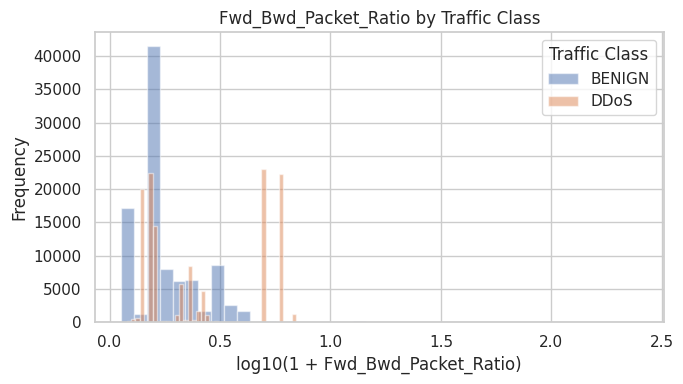

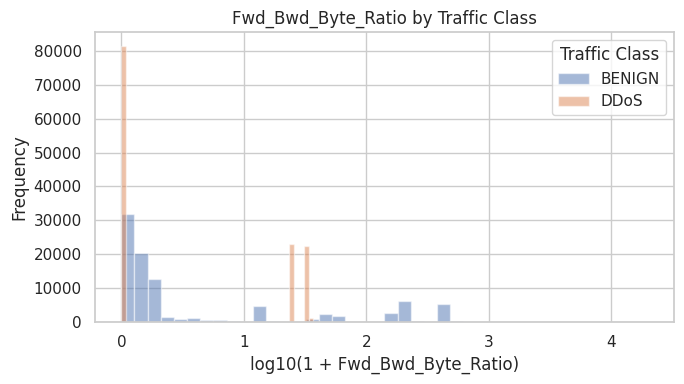

In [68]:
# ============================================================
# Engineered features by traffic class
# ============================================================

engineered_class_summary = (
    df.groupby(target_column)[engineered_features]
      .agg(["median", "mean"])
      .round(2)
)

display(engineered_class_summary)

print("\nEngineered feature distributions by traffic class:")

for feature in engineered_features:

    plt.figure(figsize=(7, 4))

    for traffic_class in df[target_column].unique():

        values = df.loc[
            df[target_column] == traffic_class,
            feature
        ]

        plt.hist(
            np.log10(values + 1),
            bins=40,
            alpha=0.5,
            label=str(traffic_class)
        )

    plt.title(f"{feature} by Traffic Class")
    plt.xlabel(f"log10(1 + {feature})")
    plt.ylabel("Frequency")
    plt.legend(title="Traffic Class")

    plt.tight_layout()
    plt.show()

In [69]:
# ============================================================
# Evidence: do the ratios separate the classes better than their ingredients?
# ============================================================
# eda_sample was drawn before the ratios existed, so draw a fresh stratified sample
fe_sample = (df.groupby(target_column, group_keys=False)
               .sample(frac=SAMPLE_SIZE / len(df), random_state=RANDOM_STATE))
y_fe = (fe_sample[target_column] == POSITIVE_CLASS).astype(int)

comparison = []
for feature in ["Total Fwd Packets", "Total Backward Packets", "Fwd_Bwd_Packet_Ratio",
                "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Fwd_Bwd_Byte_Ratio"]:
    auc = roc_auc_score(y_fe, fe_sample[feature].fillna(fe_sample[feature].median()))
    comparison.append({"Feature": feature, "Engineered": feature.startswith("Fwd_Bwd"),
                       "Separation (2*|AUC-0.5|)": round(2 * abs(auc - 0.5), 3)})
display(pd.DataFrame(comparison))

,Feature,Engineered,Separation (2*|AUC-0.5|)
0,Total Fwd Packets,False,0.382
1,Total Backward Packets,False,0.116
2,Fwd_Bwd_Packet_Ratio,True,0.250
3,Total Length of Fwd Packets,False,0.388
4,Total Length of Bwd Packets,False,0.285
5,Fwd_Bwd_Byte_Ratio,True,0.368


**Evidence for the engineered features.** The univariate evidence is mixed and is reported honestly: `Fwd_Bwd_Packet_Ratio` (separation 0.250) lies between its two ingredients (0.382 and 0.116), and `Fwd_Bwd_Byte_Ratio` (0.368) is *not* better than `Total Length of Fwd Packets` (0.388) on its own. The ratios do, however, rank first and fifteenth in mutual information (Part 11), and the byte ratio is the strongest single-feature classifier (Part 10). Whether they matter for the final model is checked in Part 20 — spoiler: after the shortcut audit the final model barely uses them because other features carry the same information, so the engineering is *justified but not essential*.

In [70]:
# ============================================================
# Update feature lists
# ============================================================

# Identify numerical and categorical columns again
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

# Remove target from feature lists
if target_column in numerical_columns:
    numerical_columns.remove(target_column)

if target_column in categorical_columns:
    categorical_columns.remove(target_column)

print("Feature lists updated successfully.")

print(f"\nTarget column        : {target_column}")
print(f"Numerical features   : {len(numerical_columns)}")
print(f"Categorical features : {len(categorical_columns)}")

print("\nEngineered features present:")
for feature in engineered_features:
    print(f"- {feature}: {'Yes' if feature in df.columns else 'No'}")

Feature lists updated successfully.

Target column        : Label
Numerical features   : 62
Categorical features : 0

Engineered features present:
- Fwd_Bwd_Packet_Ratio: Yes
- Fwd_Bwd_Byte_Ratio: Yes


In [71]:
# ============================================================
# Dataset status after cleaning and feature engineering
# ============================================================

print("CURRENT DATASET STATUS")
print("=" * 45)

print(f"Rows                : {df.shape[0]:,}")
print(f"Columns             : {df.shape[1]:,}")
print(f"Numerical features  : {len(numerical_columns)}")
print(f"Categorical features: {len(categorical_columns)}")
print(f"Target column       : {target_column}")

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nInfinite values:")
print(np.isinf(df[numerical_columns]).sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

CURRENT DATASET STATUS
Rows                : 223,112
Columns             : 63
Numerical features  : 62
Categorical features: 0
Target column       : Label

Missing values:
184

Infinite values:
0

Duplicate rows:
0


## 9. Train/test split, development split and train-only preprocessing

**Rules applied**

* Duplicates were removed **before** splitting (Part 6) so a copy of the same flow cannot sit in both train and test.
* The split is **stratified** on the label, so class proportions are identical in every subset.
* The **test set is untouched** until the final model has been selected. No imputation, selection, tuning or model comparison looks at it.
* Learned preprocessing (median imputation, mutual-information feature selection) is fitted on training data only. To keep even the *validation* rows out of those fits, they are fitted on the **fit** subset only.

```
cleaned data ──► train 80% ──► fit 80%        (fit imputer, select features, train & tune models)
                          └──► validation 20% (compare models, choose the final model)
             └─► test 20%                     (one-time final evaluation)
```

In [72]:
# ============================================================
# Separate features and target
# ============================================================

# Separate input features from the target variable.
X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

print("Modeling data prepared successfully.")
print(f"Feature matrix shape : {X.shape}")
print(f"Target shape         : {y.shape}")

print("\nTarget distribution:")
display(
    y.value_counts(dropna=False)
    .to_frame(name="Count")
    .assign(Percentage=lambda x: (x["Count"] / len(y) * 100).round(2))
)

print("\nFeature columns:")
print(X.columns.tolist())

Modeling data prepared successfully.
Feature matrix shape : (223112, 62)
Target shape         : (223112,)

Target distribution:


,Count,Percentage
Label,,
DDoS,128016,57.38
BENIGN,95096,42.62



Feature columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Bwd Segment Size', 'Init_Win_bytes_forw

In [73]:
# ============================================================
# Stratified train/test split
# ============================================================

from sklearn.model_selection import train_test_split

# Keep the final test set completely separate from model development.
# Stratification preserves the target-class proportions in both sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Stratified train-test split completed.")

print(f"\nTraining set:")
print(f"  Features : {X_train.shape}")
print(f"  Target   : {y_train.shape}")

print(f"\nFinal test set:")
print(f"  Features : {X_test.shape}")
print(f"  Target   : {y_test.shape}")

print("\nTraining target distribution:")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame(name="Percentage")
)

print("\nFinal test target distribution:")
display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame(name="Percentage")
)

Stratified train-test split completed.

Training set:
  Features : (178489, 62)
  Target   : (178489,)

Final test set:
  Features : (44623, 62)
  Target   : (44623,)

Training target distribution:


,Percentage
Label,
DDoS,57.38
BENIGN,42.62



Final test target distribution:


,Percentage
Label,
DDoS,57.38
BENIGN,42.62


In [74]:
# ============================================================
# Verify train/test data quality
# ============================================================

print("TRAINING DATA QUALITY")
print("=" * 45)

print(f"Missing values in X_train : {X_train.isnull().sum().sum():,}")
print(f"Infinite values in X_train: {np.isinf(X_train).sum().sum():,}")

print("\nTEST DATA QUALITY")
print("=" * 45)

print(f"Missing values in X_test  : {X_test.isnull().sum().sum():,}")
print(f"Infinite values in X_test : {np.isinf(X_test).sum().sum():,}")

print("\nTarget missing values:")
print(f"Training target : {y_train.isnull().sum():,}")
print(f"Testing target  : {y_test.isnull().sum():,}")

TRAINING DATA QUALITY
Missing values in X_train : 145
Infinite values in X_train: 0

TEST DATA QUALITY
Missing values in X_test  : 39
Infinite values in X_test : 0

Target missing values:
Training target : 0
Testing target  : 0


In [75]:
# ============================================================
# Target encoding, development split and training-only imputation
# ============================================================
# Encode the target once: BENIGN = 0, DDoS = 1 (DDoS is the "positive" / attack class).
label_encoder = LabelEncoder().fit(y)
CLASS_NAMES = list(label_encoder.classes_)
POSITIVE_INDEX = CLASS_NAMES.index(POSITIVE_CLASS)
print("Label encoding:", {name: i for i, name in enumerate(CLASS_NAMES)})

y_train_enc = pd.Series(label_encoder.transform(y_train), index=y_train.index, name="target")
y_test_enc = pd.Series(label_encoder.transform(y_test), index=y_test.index, name="target")

# Development split inside the TRAINING part only
X_fit_raw, X_val_raw, y_fit_enc, y_val_enc = train_test_split(
    X_train, y_train_enc, test_size=0.20, stratify=y_train_enc, random_state=RANDOM_STATE
)

# Median imputation: medians are learned from the FIT subset only
imputer_input_columns = X_fit_raw.columns.tolist()
feature_imputer = SimpleImputer(strategy="median")

def impute(frame):
    """Apply the fitted imputer and keep column names / index."""
    return pd.DataFrame(feature_imputer.transform(frame[imputer_input_columns]),
                        columns=imputer_input_columns, index=frame.index)

X_fit_all = pd.DataFrame(feature_imputer.fit_transform(X_fit_raw), columns=imputer_input_columns, index=X_fit_raw.index)
X_val_all = impute(X_val_raw)
X_test_all = impute(X_test)

print("\nNaN cells before / after imputation")
summary = pd.DataFrame({
    "Subset": ["fit", "validation", "test"],
    "Rows": [len(X_fit_raw), len(X_val_raw), len(X_test)],
    "NaN before": [X_fit_raw.isna().sum().sum(), X_val_raw.isna().sum().sum(), X_test.isna().sum().sum()],
    "NaN after": [X_fit_all.isna().sum().sum(), X_val_all.isna().sum().sum(), X_test_all.isna().sum().sum()],
    "Attack share (%)": [round(y_fit_enc.mean() * 100, 2), round(y_val_enc.mean() * 100, 2), round(y_test_enc.mean() * 100, 2)],
})
display(summary)

features_with_nan = X_fit_raw.isna().sum()
features_with_nan = features_with_nan[features_with_nan > 0]
print("Features that needed imputation (fit subset):")
display(features_with_nan.to_frame("Missing values"))

Label encoding: {'BENIGN': 0, 'DDoS': 1}

NaN cells before / after imputation


,Subset,Rows,NaN before,NaN after,Attack share (%)
0,fit,142791,124,0,57.38
1,validation,35698,21,0,57.38
2,test,44623,39,0,57.38


Features that needed imputation (fit subset):


,Missing values
Flow Duration,1
Flow Bytes/s,21
Flow Packets/s,21
Flow IAT Mean,1
Flow IAT Max,1
Flow IAT Min,76
Fwd IAT Min,3


## 10. Data-leakage and shortcut audit

Leakage means the model sees information it would not have in production. A keyword scan of the column names is **not** enough (a column can leak without being called "label"), so four different checks are made:

1. **Identifier / time columns** — can a row be memorised? (no IP, flow-ID or timestamp columns exist)
2. **Target-derived columns** — names that encode the label (keyword scan, retained from the uploaded notebook)
3. **Learned-from-everything statistics** — handled by construction: imputer and feature selection are fitted on the fit subset only
4. **Behavioural shortcuts** — single features that on their own almost reveal the label. This check uses a one-feature decision tree and is run on **training data only**.

A shortcut is not leakage in the strict sense, but it can make the model look better in the lab than it will be in the field.

In [76]:
# ============================================================
# Identifier-like columns
# ============================================================

identifier_summary = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Unique Percentage": (
        df.nunique() / len(df) * 100
    ).round(2)
})

# Show columns with very high uniqueness
potential_identifiers = identifier_summary[
    identifier_summary["Unique Percentage"] >= 95
].sort_values(
    "Unique Percentage",
    ascending=False
)

print("Potential identifier-like columns:")

if potential_identifiers.empty:
    print("No columns with 95% or more unique values were found.")
else:
    display(potential_identifiers)

Potential identifier-like columns:
No columns with 95% or more unique values were found.


In [77]:
# ============================================================
# Date/time columns
# ============================================================

datetime_keywords = [
    "date",
    "time",
    "timestamp"
]

potential_datetime_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in datetime_keywords
    )
]

print("Potential date/time columns:")

if potential_datetime_columns:
    for col in potential_datetime_columns:
        print(f"- {col}")
else:
    print("No obvious date/time columns found.")

Potential date/time columns:
No obvious date/time columns found.


In [78]:
# ============================================================
# Target-derived columns (keyword scan)
# ============================================================

leakage_keywords = [
    "label",
    "target",
    "attack",
    "class",
    "category"
]

potential_leakage_columns = []

for col in df.columns:

    if col == target_column:
        continue

    col_name = col.lower()

    if any(keyword in col_name for keyword in leakage_keywords):
        potential_leakage_columns.append(col)

print("Potential target-leakage columns:")
print("-" * 45)

if potential_leakage_columns:
    for col in potential_leakage_columns:
        print(f"- {col}")
else:
    print("No obvious target-leakage columns found.")

Potential target-leakage columns:
---------------------------------------------
No obvious target-leakage columns found.


,Feature,Accuracy using this feature only
0,Fwd_Bwd_Byte_Ratio,0.9966
1,Destination Port,0.9611
2,Total Length of Bwd Packets,0.9430
3,Bwd Packet Length Mean,0.9422
4,Average Packet Size,0.9422
5,Avg Bwd Segment Size,0.9422
6,Total Length of Fwd Packets,0.9405
7,Bwd Packet Length Max,0.9360
8,Init_Win_bytes_forward,0.9043
9,Fwd Header Length,0.9037


Reference: always predicting the majority class gives 0.5727


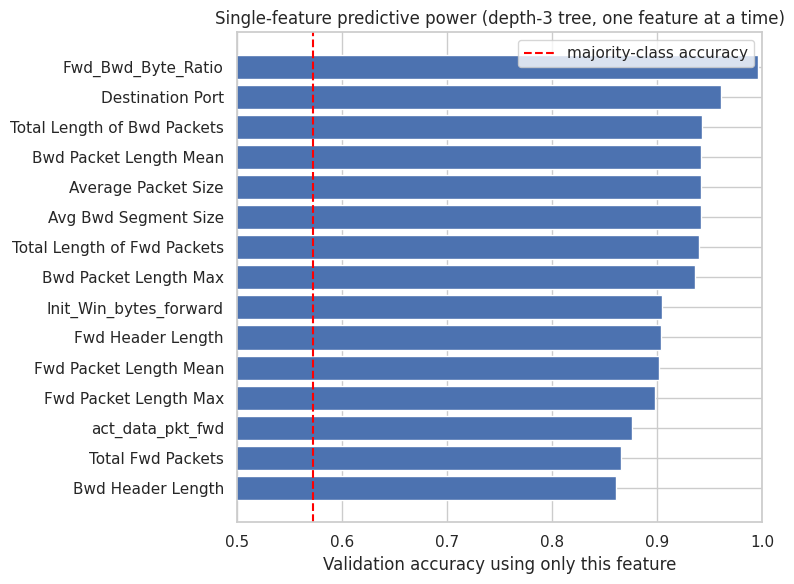

In [79]:
# ============================================================
# Single-feature predictive power (training data only)
# ============================================================
# A depth-3 decision tree is trained on ONE feature at a time. A feature that alone gives
# near-perfect accuracy is either a genuine strong signal or a dataset artefact.
screen_X = X_fit_all.sample(n=min(40000, len(X_fit_all)), random_state=RANDOM_STATE)
screen_y = y_fit_enc.loc[screen_X.index]
s_train, s_test, sy_train, sy_test = train_test_split(
    screen_X, screen_y, test_size=0.30, stratify=screen_y, random_state=RANDOM_STATE
)

stump_rows = []
for feature in X_fit_all.columns:
    stump = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(s_train[[feature]], sy_train)
    stump_rows.append({"Feature": feature,
                       "Accuracy using this feature only": accuracy_score(sy_test, stump.predict(s_test[[feature]]))})

stump_table = (pd.DataFrame(stump_rows)
                 .sort_values("Accuracy using this feature only", ascending=False)
                 .reset_index(drop=True))
majority_accuracy = max(sy_test.mean(), 1 - sy_test.mean())

display(stump_table.head(12).round(4))
print(f"Reference: always predicting the majority class gives {majority_accuracy:.4f}")

top = stump_table.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["Feature"], top["Accuracy using this feature only"], color="#4C72B0")
plt.axvline(majority_accuracy, color="red", ls="--", label="majority-class accuracy")
plt.xlim(0.5, 1.0)
plt.title("Single-feature predictive power (depth-3 tree, one feature at a time)")
plt.xlabel("Validation accuracy using only this feature"); plt.legend()
plt.tight_layout(); plt.show()

**Interpretation (single-feature screen).** The majority-class reference is 0.573. A depth-3 tree on **one** feature reaches 99.66% with `Fwd_Bwd_Byte_Ratio` and 96.1% with `Destination Port`; five more raw features exceed 94%. The engineered ratio is derived only from two byte counts of the same flow (no label information is used), so this is not leakage — it simply shows how easy this capture is to separate. `Destination Port` is different: it is suspicious on domain grounds and is analysed next.

In [80]:
# ============================================================
# Closer look at the strongest single feature: Destination Port
# ============================================================
port_frame = pd.DataFrame({
    "Destination Port": X_fit_all["Destination Port"],
    "Class": label_encoder.inverse_transform(y_fit_enc),
})

dominant_attack_port = int(port_frame.loc[port_frame["Class"] == POSITIVE_CLASS, "Destination Port"].mode()[0])

port_summary = port_frame.groupby("Class")["Destination Port"].agg(
    Flows="count", Distinct_ports="nunique", Median="median", Min="min", Max="max")
port_summary[f"Share on port {dominant_attack_port} (%)"] = (
    (port_frame["Destination Port"] == dominant_attack_port).groupby(port_frame["Class"]).mean() * 100).round(3)
display(port_summary)

for cls in CLASS_NAMES:
    top_ports = (port_frame.loc[port_frame["Class"] == cls, "Destination Port"]
                 .value_counts(normalize=True).head(5).mul(100).round(2))
    print(f"\nTop destination ports for {cls} (% of its flows):")
    display(top_ports.to_frame("%"))

,Flows,Distinct_ports,Median,Min,Max,Share on port 80 (%)
Class,,,,,,
BENIGN,60862,18008,443.0,0.0,65532.0,8.984
DDoS,81929,2,80.0,80.0,64873.0,99.999



Top destination ports for BENIGN (% of its flows):


,%
Destination Port,
53.0,31.94
443.0,13.68
80.0,8.98
8080.0,0.54
123.0,0.38



Top destination ports for DDoS (% of its flows):


,%
Destination Port,
80.0,100.0
64873.0,0.0


**Interpretation (Destination Port).** DDoS flows use only **2** distinct destination ports and 99.999% of them go to port 80, whereas benign flows use 18,008 distinct ports (port 53 31.9%, 443 13.7%, port 80 9.0%). In this capture the attacker targeted one service on one server. A model can therefore "detect DDoS" by checking `port == 80` — a property of the *experiment*, not of attack behaviour. A real attack on another port (or on port 80 on another server) would not be recognised by that rule, and benign web traffic on port 80 would be at risk of false alarms.

In [81]:
# ============================================================
# Ablation: how much does the model need Destination Port?
# ============================================================
# Train the same models with and without the port; evaluate on the VALIDATION subset (not the test set).
all_features = X_fit_all.columns.tolist()
without_port = [f for f in all_features if f != "Destination Port"]

def make_rf():
    return RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced",
                                  n_jobs=-1, random_state=RANDOM_STATE)

def make_xgb():
    return XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.10, subsample=0.80,
                         colsample_bytree=0.80, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=-1)

def holdout_score(model, features):
    """Fit on the fit subset, return (macro F1, number of errors) on the validation subset."""
    model.fit(X_fit_all[features], y_fit_enc)
    pred = model.predict(X_val_all[features])
    return f1_score(y_val_enc, pred, average="macro"), int((pred != y_val_enc).sum())

ablation_rows = []
for name, factory in {"Random Forest": make_rf, "XGBoost": make_xgb}.items():
    f1_with, err_with = holdout_score(factory(), all_features)
    f1_without, err_without = holdout_score(factory(), without_port)
    ablation_rows.append({"Model": name,
                          "Macro F1 with port": f1_with, "Errors with port": err_with,
                          "Macro F1 without port": f1_without, "Errors without port": err_without,
                          "Macro F1 loss": f1_with - f1_without})
ablation = pd.DataFrame(ablation_rows)
display(ablation.round(5))

# Pre-declared decision rule: remove the shortcut if it costs less than 0.001 macro-F1 for every model.
PORT_TOLERANCE = 0.001
drop_port = bool((ablation["Macro F1 loss"] < PORT_TOLERANCE).all())
print(f"\nDecision rule: drop 'Destination Port' if the loss is < {PORT_TOLERANCE} for all models  ->  drop_port = {drop_port}")

,Model,Macro F1 with port,Errors with port,Macro F1 without port,Errors without port,Macro F1 loss
0,Random Forest,0.99994,2,0.99986,5,0.00009
1,XGBoost,1.00000,0,0.99997,1,0.00003



Decision rule: drop 'Destination Port' if the loss is < 0.001 for all models  ->  drop_port = True


**Decision.** Removing the port changes validation macro-F1 by only 0.00009 (Random Forest: 2 → 5 errors) and 0.00003 (XGBoost: 0 → 1 error) — far below the pre-declared tolerance of 0.001. The information is therefore redundant for classification, while keeping it would let the model lean on a lab artefact. **`Destination Port` is removed from the model inputs.** This is a deliberate trade of ≈ a handful of validation flows for a model that must rely on flow behaviour.

In [82]:
# ============================================================
# Apply the leakage / shortcut decision
# ============================================================
candidate_features = [f for f in all_features if not (drop_port and f == "Destination Port")]

print(f"Features before the audit : {len(all_features)}")
print(f"Features after the audit  : {len(candidate_features)}")
print("Removed:", [f for f in all_features if f not in candidate_features] or "nothing")

Features before the audit : 62
Features after the audit  : 61
Removed: ['Destination Port']


### Leakage / shortcut audit — summary of every suspicious feature

| Feature / mechanism | Concern | Evidence | Decision |
|---|---|---|---|
| Target-derived columns | would encode the label | keyword scan: none | nothing to remove |
| Identifier / time columns | memorising rows | none exist in the CSV | nothing to remove |
| Statistics from the whole data set | leakage via preprocessing | imputer and MI fitted on the *fit* subset only | by construction clean |
| **`Destination Port`** | scenario shortcut (99.999% of DDoS on port 80) | single-feature accuracy 96.1%; ablation loss < 0.0001 macro-F1 | **removed** |
| `Fwd_Bwd_Byte_Ratio` (engineered) | very strong alone (99.66%) | built from two same-row counts, no label use | **kept**; flagged |
| `Init_Win_bytes_forward` | initial TCP window is a TCP-stack fingerprint of the sending host/tool (256 for 54.5% of DDoS flows vs 1.1% of benign flows) | appears as a top feature in Part 20 | **kept**, flagged as a generalisation risk |
| Flag counts, `min_seg_size_forward` | tool/host fingerprint | near class-pure (Part 7.3) | kept (behavioural), flagged |
| Near-duplicate flows across train/test | optimistic scores | exact duplicates removed; near-duplicates from one attack burst cannot be separated without timestamps/IPs | **limitation** (Part 23) |

## 11. Feature selection

**Goal:** keep the features that carry information about the label, drop the rest, and be able to justify each decision. The selection is fitted on the **fit subset only**.

| Method | Used? | Reason |
|---|---|---|
| Remove constant / identical columns | ✅ done in Part 6 | zero or duplicate information |
| **Mutual information (MI)** | ✅ main filter | captures non-linear dependence, no normality assumption, works on skewed data |
| **Tree-based importance** | ✅ cross-check | an independent, model-based opinion; confirms that MI did not discard anything the trees rely on |
| All-features vs. selected-features comparison | ✅ | proves empirically that the filter does not cost performance |
| ANOVA F-test | ❌ | assumes roughly normal groups; most features are heavily skewed (Part 7.2) |
| Recursive feature elimination | ❌ | needs dozens of model refits for no expected benefit here |
| Dropping correlated features | ❌ (deliberately) | the main models are tree-based and insensitive to correlated inputs; removal would only cost information. The effect on *interpretation* is handled in Part 20 with grouped importance |

Rule: keep features whose MI is at or above the **median** MI of the candidate features (the original notebook's rule, retained).

Candidate features : 61
Selected features  : 31   (MI threshold = median = 0.3025)
Dropped features   : 30


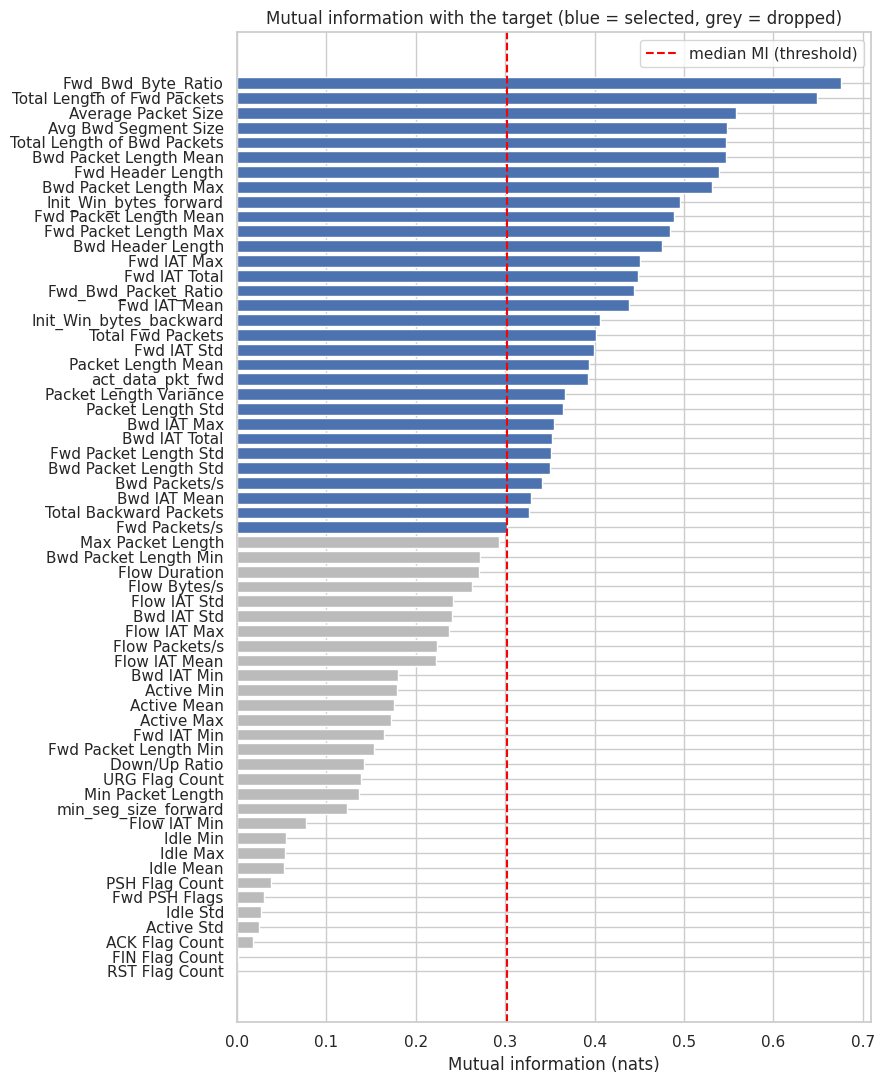

Selected features (ordered by MI):


,Mutual information
Fwd_Bwd_Byte_Ratio,0.6758
Total Length of Fwd Packets,0.6490
Average Packet Size,0.5583
Avg Bwd Segment Size,0.5481
Total Length of Bwd Packets,0.5472
Bwd Packet Length Mean,0.5472
Fwd Header Length,0.5386
Bwd Packet Length Max,0.5311
Init_Win_bytes_forward,0.4953
Fwd Packet Length Mean,0.4893


Dropped features:


,Mutual information
Flow Duration,0.2711
Fwd Packet Length Min,0.1537
Bwd Packet Length Min,0.2720
Flow Bytes/s,0.2627
Flow Packets/s,0.2233
Flow IAT Mean,0.2229
Flow IAT Std,0.2419
Flow IAT Max,0.2371
Flow IAT Min,0.0772
Fwd IAT Min,0.1647


Shapes -> fit (142791, 31) | validation (35698, 31) | test (44623, 31) | train(final) (178489, 31)
NaN check: 0 0 0


In [83]:
# ============================================================
# Mutual-information feature selection (fit subset only)
# ============================================================
mi_scores = pd.Series(
    mutual_info_classif(X_fit_all[candidate_features], y_fit_enc, random_state=RANDOM_STATE),
    index=candidate_features,
).sort_values(ascending=False)

mi_threshold = mi_scores.median()
selected_features = mi_scores[mi_scores >= mi_threshold].index.tolist()
if len(selected_features) < 10:                      # safety net, retained from the uploaded notebook
    selected_features = mi_scores.head(10).index.tolist()
dropped_features = [f for f in candidate_features if f not in selected_features]

# Final modelling matrices
X_fit = X_fit_all[selected_features].copy()
X_val = X_val_all[selected_features].copy()
X_test_sel = X_test_all[selected_features].copy()
X_train_final = pd.concat([X_fit, X_val])            # fit + validation = the whole training part
y_train_final = pd.concat([y_fit_enc, y_val_enc])

print(f"Candidate features : {len(candidate_features)}")
print(f"Selected features  : {len(selected_features)}   (MI threshold = median = {mi_threshold:.4f})")
print(f"Dropped features   : {len(dropped_features)}")

colors = ["#4C72B0" if f in selected_features else "#BBBBBB" for f in mi_scores.index]
plt.figure(figsize=(9, 11))
plt.barh(mi_scores.index[::-1], mi_scores.values[::-1], color=colors[::-1])
plt.axvline(mi_threshold, color="red", ls="--", label="median MI (threshold)")
plt.title("Mutual information with the target (blue = selected, grey = dropped)")
plt.xlabel("Mutual information (nats)"); plt.legend(); plt.tight_layout(); plt.show()

print("Selected features (ordered by MI):")
display(mi_scores.loc[selected_features].to_frame("Mutual information").round(4))
print("Dropped features:")
display(mi_scores.loc[dropped_features].to_frame("Mutual information").round(4))
print(f"Shapes -> fit {X_fit.shape} | validation {X_val.shape} | test {X_test_sel.shape} | train(final) {X_train_final.shape}")
print("NaN check:", X_fit.isna().sum().sum(), X_val.isna().sum().sum(), X_test_sel.isna().sum().sum())

**Interpretation (selection).** 31 of the 61 candidate features are kept (MI ≥ the median 0.3025). The kept features are dominated by packet-length/size statistics, header lengths, forward inter-arrival times, initial window sizes and the two engineered ratios (`Fwd_Bwd_Byte_Ratio` has the highest MI, 0.676). Dropped are the flag counts, the active/idle family, `Flow Duration` and the flow-level rate features: their MI (e.g. `Flow Duration` 0.271, `Flow Bytes/s` 0.263) is just below the cut-off or very small (flag counts), i.e. they carry less information about the label than packet sizes in this capture. The two dropped flow-level rates sit near the threshold, so the cut-off is a convention, not a hard boundary — the comparison below checks that it costs nothing.

In [84]:
# ============================================================
# Redundancy that remains among the selected features
# ============================================================
corr_selected = X_fit.corr().abs()
upper = corr_selected.where(np.triu(np.ones(corr_selected.shape), k=1).astype(bool))
high_pairs = upper.stack().loc[lambda s: s >= 0.95].sort_values(ascending=False)

print(f"Selected features: {len(selected_features)} | pairs with |r| >= 0.95: {len(high_pairs)}")
display(high_pairs.head(15).round(3).to_frame("|correlation|"))

Selected features: 31 | pairs with |r| >= 0.95: 15


,,|correlation|
Avg Bwd Segment Size,Bwd Packet Length Mean,1.000
Average Packet Size,Packet Length Mean,0.999
Bwd Packet Length Max,Bwd Packet Length Std,0.993
Fwd Packet Length Max,Fwd Packet Length Std,0.992
Fwd IAT Max,Fwd IAT Std,0.980
Bwd Header Length,Total Backward Packets,0.974
Total Length of Bwd Packets,Total Backward Packets,0.973
Fwd Header Length,Total Fwd Packets,0.967
Bwd Packet Length Mean,Bwd Packet Length Max,0.961
Avg Bwd Segment Size,Bwd Packet Length Max,0.961


In [85]:
# ============================================================
# Cross-check: tree-based importance vs. mutual information
# ============================================================
probe_idx = X_fit_all.sample(n=min(60000, len(X_fit_all)), random_state=RANDOM_STATE).index
rf_probe = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced",
                                  n_jobs=-1, random_state=RANDOM_STATE)
rf_probe.fit(X_fit_all.loc[probe_idx, candidate_features], y_fit_enc.loc[probe_idx])

rf_importance = pd.Series(rf_probe.feature_importances_, index=candidate_features).sort_values(ascending=False)
rho, p = spearmanr(mi_scores[candidate_features], rf_importance[candidate_features])
print(f"Spearman rank correlation between MI and RF importance: {rho:.3f} (p = {p:.1e})")

for k in (10, 15):
    top_k = rf_importance.head(k).index
    kept = [f for f in top_k if f in selected_features]
    print(f"Random-forest top-{k} features kept by the MI filter: {len(kept)}/{k}")

lost = [f for f in rf_importance.head(15).index if f not in selected_features]
print("Top-15 RF features NOT selected by MI:", lost or "none")

Spearman rank correlation between MI and RF importance: 0.881 (p = 8.4e-21)
Random-forest top-10 features kept by the MI filter: 10/10
Random-forest top-15 features kept by the MI filter: 14/15
Top-15 RF features NOT selected by MI: ['Bwd Packet Length Min']


In [86]:
# ============================================================
# Does the MI filter cost performance? (all candidates vs. selected, XGBoost, validation subset)
# ============================================================
rows = []
for label, cols in [("All candidate features", candidate_features), ("MI-selected features", selected_features)]:
    model = make_xgb()
    t0 = time.perf_counter()
    model.fit(X_fit_all[cols], y_fit_enc)
    fit_s = time.perf_counter() - t0
    pred = model.predict(X_val_all[cols])
    rows.append({"Feature set": label, "Features": len(cols),
                 "Macro F1": f1_score(y_val_enc, pred, average="macro"),
                 "Errors": int((pred != y_val_enc).sum()), "Fit time (s)": round(fit_s, 1)})
display(pd.DataFrame(rows).round(5))

,Feature set,Features,Macro F1,Errors,Fit time (s)
0,All candidate features,61,0.99997,1,3.9
1,MI-selected features,31,0.99997,1,2.1


**Interpretation (feature-selection validation).** The independent random-forest ranking agrees strongly with MI (Spearman ρ = 0.88; all of the forest's top-10 features were kept and 14 of its top-15). The one top-15 feature not selected is `Bwd Packet Length Min`. Most importantly, XGBoost reaches **exactly the same validation macro-F1 (0.99997, one error) with 31 features as with all 61**, while training faster (1.9 s vs 3.3 s). The filter therefore removes noise and redundancy without losing information. 15 pairs with |r| ≥ 0.95 remain among the selected features; that is accepted deliberately for tree-based models.

### 11.1 Outlier-treatment verification
The outlier decision (Part 7.6) was: *keep extreme values; apply a signed log transform only inside the Logistic Regression pipeline.* Two checks verify it on the validation subset:

1. A decision tree only compares values with thresholds, so a strictly increasing transform such as `log1p` must **not change** its predictions → raw data is fine for all tree models.
2. Logistic Regression is scale-sensitive; measure whether the transform actually helps it.

`signed_log1p(x) = sign(x) · log(1 + |x|)` keeps the sign so the `-1` window-size sentinel still works.

In [87]:
# ============================================================
# Verify the outlier-treatment decision
# ============================================================
def signed_log1p(values):
    """log(1 + |x|) with the sign of x preserved (safe for the -1 sentinel values)."""
    return np.sign(values) * np.log1p(np.abs(values))

# 1) Decision tree: raw vs. log-transformed inputs
dt_raw = DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE).fit(X_fit, y_fit_enc)
dt_log = DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE).fit(signed_log1p(X_fit), y_fit_enc)
pred_raw, pred_log = dt_raw.predict(X_val), dt_log.predict(signed_log1p(X_val))
print(f"Decision tree - share of identical predictions on raw vs. log inputs: {(pred_raw == pred_log).mean():.5f}")

# 2) Logistic regression: with vs. without the transform
lr_plain = Pipeline([("scaler", StandardScaler()),
                     ("model", LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE))])
lr_logged = Pipeline([("log", FunctionTransformer(signed_log1p)), ("scaler", StandardScaler()),
                      ("model", LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE))])
rows = []
for label, model in [("Decision Tree, raw", dt_raw), ("Logistic Regression, scaled only", lr_plain),
                     ("Logistic Regression, log + scaled", lr_logged)]:
    if "Logistic" in label:
        model.fit(X_fit, y_fit_enc)
    pred = model.predict(X_val)
    rows.append({"Model": label, "Macro F1": f1_score(y_val_enc, pred, average="macro"),
                 "Errors": int((pred != y_val_enc).sum())})
display(pd.DataFrame(rows).round(5))

Decision tree - share of identical predictions on raw vs. log inputs: 0.99997


,Model,Macro F1,Errors
0,"Decision Tree, raw",0.99957,15
1,"Logistic Regression, scaled only",0.99814,65
2,"Logistic Regression, log + scaled",0.99831,59


**Verification of the outlier decision.** (1) A strictly increasing transform leaves a decision tree unchanged: raw and log-transformed inputs give identical predictions for 99.997% of validation flows (the remainder are floating-point ties). Tree models therefore need no outlier treatment. (2) For Logistic Regression the signed-log transform helps slightly (65 → 59 errors, macro-F1 0.99814 → 0.99831) — a small, in-direction improvement, which is why it is kept in that pipeline only. The decision to retain all extreme values is confirmed: nothing was removed or capped, and the tree models reach macro-F1 ≈ 0.9995–0.99997.

## 12. Class-imbalance analysis and handling

The class ratio was quantified in Part 7.1. Before choosing a remedy, the impact of each option is **measured** rather than assumed. Five strategies are compared with 3-fold cross-validation on a 40,000-row stratified subsample of the **fit** subset, using a fast decision tree. The resamplers sit inside an `imblearn` pipeline, so resampling is applied only to the training part of each fold and never to a validation fold or to the test set.

Metrics: macro-F1, balanced accuracy, and the recall of each class separately (so that a gain for one class cannot hide a loss for the other).

In [88]:
# ============================================================
# Compare imbalance-handling strategies (resampling inside the CV folds only)
# ============================================================
sub_X = X_fit.sample(n=min(40000, len(X_fit)), random_state=RANDOM_STATE)
sub_y = y_fit_enc.loc[sub_X.index]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "macro_f1": "f1_macro",
    "balanced_acc": "balanced_accuracy",
    "recall_benign": make_scorer(recall_score, pos_label=0),
    "recall_ddos": make_scorer(recall_score, pos_label=1),
}

def tree(**kwargs):
    return DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE, **kwargs)

strategies = {
    "No handling": tree(),
    "class_weight='balanced'": tree(class_weight="balanced"),
    "Random undersampling": ImbPipeline([("sampler", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", tree())]),
    "Random oversampling": ImbPipeline([("sampler", RandomOverSampler(random_state=RANDOM_STATE)), ("model", tree())]),
    "SMOTE": ImbPipeline([("sampler", SMOTE(random_state=RANDOM_STATE)), ("model", tree())]),
}

rows = []
for name, estimator in strategies.items():
    t0 = time.perf_counter()
    res = cross_validate(estimator, sub_X, sub_y, cv=cv3, scoring=scoring, n_jobs=1)
    row = {"Strategy": name}
    for key in scoring:
        row[key] = f"{res['test_' + key].mean():.4f} ± {res['test_' + key].std():.4f}"
    row["Time (s)"] = round(time.perf_counter() - t0, 1)
    rows.append(row)

imbalance_comparison = pd.DataFrame(rows).set_index("Strategy")
display(imbalance_comparison)

,macro_f1,balanced_acc,recall_benign,recall_ddos,Time (s)
Strategy,,,,,
No handling,0.9993 ± 0.0002,0.9993 ± 0.0002,0.9992 ± 0.0003,0.9994 ± 0.0004,0.7
class_weight='balanced',0.9993 ± 0.0002,0.9992 ± 0.0002,0.9990 ± 0.0002,0.9995 ± 0.0003,0.7
Random undersampling,0.9992 ± 0.0002,0.9992 ± 0.0001,0.9992 ± 0.0002,0.9993 ± 0.0005,0.5
Random oversampling,0.9993 ± 0.0003,0.9993 ± 0.0002,0.9991 ± 0.0003,0.9994 ± 0.0004,0.7
SMOTE,0.9992 ± 0.0003,0.9992 ± 0.0003,0.9992 ± 0.0002,0.9993 ± 0.0004,3.3


**Decision (imbalance handling).** All five strategies give the same result within one standard deviation (macro-F1 0.9992–0.9993; both class recalls ≈ 0.999), so **resampling brings no measurable benefit** here. That is expected for a 1.35 : 1 ratio, and SMOTE additionally costs 5× the time of the other options and creates synthetic network flows that may not be physically realistic. **No resampling is applied.** The models keep `class_weight="balanced"` as a harmless safeguard (it changed nothing measurable); the test set is never resampled.

## 13. Baseline and individual models

**One evaluation framework for every model.** Each model is trained on the **fit** subset and scored on the **validation** subset with the same helper function, `evaluate_model`. It returns accuracy, weighted precision/recall/F1, **macro F1**, the **per-class precision and recall**, the confusion-matrix counts (false positives = benign flows flagged as attacks, false negatives = attacks that were missed), ROC-AUC, PR-AUC, training time and prediction latency.

**Why these metrics.** Accuracy alone can look good by accident; per-class recall shows whether attacks are actually being caught; macro-F1 weights both classes equally. In intrusion detection a *false negative* is a missed attack (the costly error), a *false positive* is a wasted analyst alert.

**Models** (hyper-parameters are those of the uploaded notebook):

* **Baseline** – `DummyClassifier(most_frequent)`: the floor any real model must beat.
* **Decision Tree** – one tree of axis-aligned splits; fast, interpretable, doubles as the simple-model baseline.
* **Random Forest** – *bagging* of many deep trees on bootstrap samples and random feature subsets; averaging cuts variance.
* **Extra Trees** – like Random Forest but split thresholds are drawn at random; even lower variance, faster training, slightly higher bias.
* **XGBoost** – *boosting*: trees are added one after another, each correcting the errors of the previous ones; usually the strongest tabular learner.
* **Logistic Regression** – linear model on log-transformed, standardised inputs; a non-tree reference point and a diverse member for the ensembles.

In [89]:
# ============================================================
# Evaluation framework used for every model
# ============================================================
dev_registry = {}     # name -> {"model", "pred", "proba", "row"}  (validation-subset results)

def evaluate_model(name, model, X_eval, y_eval, fit_seconds=np.nan):
    """Score a FITTED model on (X_eval, y_eval) and return (metrics_row, predictions, attack_probability).
    Class 1 (DDoS) is the positive class: FN = missed attacks, FP = benign flows flagged."""
    t0 = time.perf_counter()
    pred = model.predict(X_eval)
    predict_seconds = time.perf_counter() - t0
    proba = model.predict_proba(X_eval)[:, POSITIVE_INDEX]

    tn, fp, fn, tp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (weighted)": precision_score(y_eval, pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_eval, pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_eval, pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_eval, pred, average="macro", zero_division=0),
        f"Precision {CLASS_NAMES[0]}": precision_score(y_eval, pred, pos_label=0, zero_division=0),
        f"Recall {CLASS_NAMES[0]}": recall_score(y_eval, pred, pos_label=0, zero_division=0),
        f"Precision {CLASS_NAMES[1]}": precision_score(y_eval, pred, pos_label=1, zero_division=0),
        f"Recall {CLASS_NAMES[1]}": recall_score(y_eval, pred, pos_label=1, zero_division=0),
        "False positives": int(fp), "False negatives": int(fn),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
        "Fit time (s)": fit_seconds,
        "Predict ms / 1k flows": predict_seconds / len(X_eval) * 1000 * 1000,
    }
    return row, pred, proba

def fit_and_register(name, model, X_fit_=None, y_fit_=None):
    """Fit on the FIT subset, score on the VALIDATION subset and store the result."""
    X_fit_ = X_fit if X_fit_ is None else X_fit_
    y_fit_ = y_fit_enc if y_fit_ is None else y_fit_
    t0 = time.perf_counter()
    model.fit(X_fit_, y_fit_)
    fit_seconds = time.perf_counter() - t0
    row, pred, proba = evaluate_model(name, model, X_val, y_val_enc, fit_seconds)
    dev_registry[name] = {"model": model, "pred": pred, "proba": proba, "row": row}
    print(f"{name:<28} macro F1 = {row['Macro F1']:.5f} | FN = {row['False negatives']:>3} | "
          f"FP = {row['False positives']:>3} | fit {fit_seconds:6.1f}s")
    return model

def results_table(names):
    """Validation results of the given models as a DataFrame."""
    return pd.DataFrame([dev_registry[n]["row"] for n in names]).set_index("Model")

def plot_confusion_matrices(names, y_true, title, n_cols=3):
    """Grid of confusion matrices (counts, with row-normalised % in brackets)."""
    n_rows = int(np.ceil(len(names) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.2 * n_rows))
    for ax, name in zip(np.atleast_1d(axes).ravel(), names):
        cm = confusion_matrix(y_true, dev_registry[name]["pred"], labels=[0, 1])
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
        labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.2f}%)" for j in range(2)] for i in range(2)])
        sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax.set_title(name); ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
    for ax in np.atleast_1d(axes).ravel()[len(names):]:
        ax.axis("off")
    plt.suptitle(title, y=1.0, fontsize=13)
    plt.tight_layout(); plt.show()

def print_reports(names, y_true):
    """Per-class precision / recall / F1 for each model."""
    for name in names:
        print("-" * 70, f"\n{name}\n" + "-" * 70)
        print(classification_report(y_true, dev_registry[name]["pred"], target_names=CLASS_NAMES,
                                    digits=4, zero_division=0))

print("Framework ready. Positive (attack) class:", POSITIVE_CLASS, "| index:", POSITIVE_INDEX)

Framework ready. Positive (attack) class: DDoS | index: 1


In [90]:
# ============================================================
# Baseline model
# ============================================================
fit_and_register("Baseline (most frequent)", DummyClassifier(strategy="most_frequent"))

Baseline (most frequent)     macro F1 = 0.36459 | FN =   0 | FP = 15215 | fit    0.0s


DummyClassifier(strategy='most_frequent')

In [91]:
# ============================================================
# Decision Tree
# ============================================================
fit_and_register("Decision Tree", DecisionTreeClassifier(max_depth=12, class_weight="balanced",
                                                         random_state=RANDOM_STATE))

Decision Tree                macro F1 = 0.99954 | FN =  12 | FP =   4 | fit    2.1s


DecisionTreeClassifier(class_weight='balanced', max_depth=12, random_state=42)

In [92]:
# ============================================================
# Random Forest
# ============================================================
fit_and_register("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced",
                                                         random_state=RANDOM_STATE, n_jobs=-1))

Random Forest                macro F1 = 0.99989 | FN =   2 | FP =   2 | fit   21.0s


RandomForestClassifier(class_weight='balanced', max_depth=15, n_jobs=-1,
                       random_state=42)

In [93]:
# ============================================================
# Extra Trees
# ============================================================
fit_and_register("Extra Trees", ExtraTreesClassifier(n_estimators=100, max_depth=15, class_weight="balanced",
                                                     random_state=RANDOM_STATE, n_jobs=-1))

Extra Trees                  macro F1 = 0.99926 | FN =  23 | FP =   3 | fit    6.8s


ExtraTreesClassifier(class_weight='balanced', max_depth=15, n_jobs=-1,
                     random_state=42)

In [94]:
# ============================================================
# XGBoost
# ============================================================
fit_and_register("XGBoost", XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.10, subsample=0.80,
                                          colsample_bytree=0.80, objective="binary:logistic",
                                          eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1))

XGBoost                      macro F1 = 0.99997 | FN =   0 | FP =   1 | fit    3.2s


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [95]:
# ============================================================
# Logistic Regression (signed-log transform -> standardise -> logistic regression)
# ============================================================
def make_logistic():
    return Pipeline([
        ("log", FunctionTransformer(signed_log1p)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)),
    ])

fit_and_register("Logistic Regression", make_logistic())

Logistic Regression          macro F1 = 0.99831 | FN =  31 | FP =  28 | fit    1.3s


Pipeline(steps=[('log',
                 FunctionTransformer(func=<function signed_log1p at 0x7c6a39c77f60>)),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=500,
                                    random_state=42))])

,Accuracy,Precision (weighted),Recall (weighted),Weighted F1,Macro F1,Precision BENIGN,Recall BENIGN,Precision DDoS,Recall DDoS,False positives,False negatives,ROC-AUC,PR-AUC,Fit time (s),Predict ms / 1k flows
Model,,,,,,,,,,,,,,,
XGBoost,0.99997,0.99997,0.99997,0.99997,0.99997,1.00000,0.99993,0.99995,1.00000,1,0,1.00000,1.00000,3.15015,2.11274
Random Forest,0.99989,0.99989,0.99989,0.99989,0.99989,0.99987,0.99987,0.99990,0.99990,2,2,1.00000,1.00000,21.03740,5.19927
Decision Tree,0.99955,0.99955,0.99955,0.99955,0.99954,0.99921,0.99974,0.99980,0.99941,4,12,0.99975,0.99978,2.12021,0.14675
Extra Trees,0.99927,0.99927,0.99927,0.99927,0.99926,0.99849,0.99980,0.99985,0.99888,3,23,0.99997,0.99998,6.76581,9.89486
Logistic Regression,0.99835,0.99835,0.99835,0.99835,0.99831,0.99796,0.99816,0.99863,0.99849,28,31,0.99986,0.99981,1.30409,2.23935
Baseline (most frequent),0.57379,0.32923,0.57379,0.41839,0.36459,0.00000,0.00000,0.57379,1.00000,15215,0,0.50000,0.57379,0.00478,0.00887


---------------------------------------------------------------------- 
Decision Tree
----------------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN     0.9992    0.9997    0.9995     15215
        DDoS     0.9998    0.9994    0.9996     20483

    accuracy                         0.9996     35698
   macro avg     0.9995    0.9996    0.9995     35698
weighted avg     0.9996    0.9996    0.9996     35698

---------------------------------------------------------------------- 
Random Forest
----------------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN     0.9999    0.9999    0.9999     15215
        DDoS     0.9999    0.9999    0.9999     20483

    accuracy                         0.9999     35698
   macro avg     0.9999    0.9999    0.9999     35698
weighted avg     0.9999    0.9999    0.9999     35698

--------------------------------

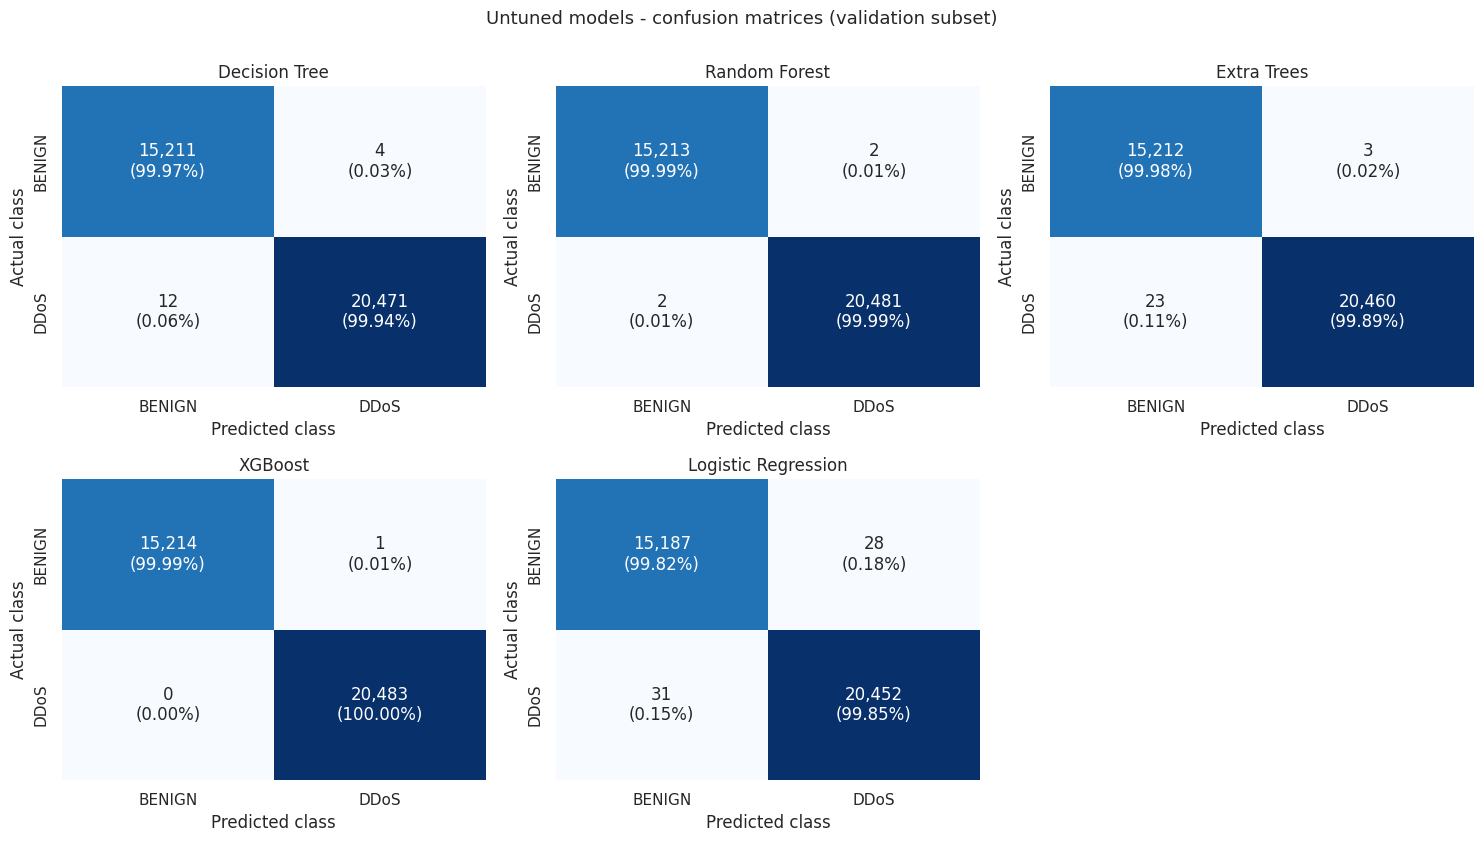

In [96]:
# ============================================================
# Evaluation of the untuned models on the VALIDATION subset
# ============================================================
untuned_names = ["Baseline (most frequent)", "Decision Tree", "Random Forest",
                 "Extra Trees", "XGBoost", "Logistic Regression"]

display(results_table(untuned_names).sort_values("Macro F1", ascending=False).round(5))
print_reports(untuned_names[1:], y_val_enc)
plot_confusion_matrices(untuned_names[1:], y_val_enc, "Untuned models - confusion matrices (validation subset)")

**Interpretation (untuned models, validation subset).** The dummy baseline reaches macro-F1 0.365 (it predicts "DDoS" for everything, flagging all 15,215 benign flows) — the floor to beat. Every real model is far above it: XGBoost 0.99997 (0 missed attacks, 1 false alarm), Random Forest 0.99989 (2/2), Decision Tree 0.99954 (12/4), Extra Trees 0.99926 (23 missed attacks, 3 false alarms), Logistic Regression 0.99831 (31/28). A *single* decision tree is already strong, which confirms the classes are almost separable by thresholds. Extra Trees, with its random thresholds, misses most attacks of the tree family; the linear model is the weakest because the class boundary is not linear.

## 14. Hyper-parameter tuning

**Method.** `RandomizedSearchCV` with 3-fold stratified cross-validation, scored by **macro-F1** (it weights both classes equally, which fits the intrusion-detection goal better than accuracy). To keep the search fast, the *ranking* of configurations is done on a stratified 60,000-row subsample of the fit subset; the winning configuration is then re-fitted on the **full** fit subset. The test set is never involved.

**What is tuned and why**

| Parameter | Models | Why it matters |
|---|---|---|
| `max_depth` | DT, RF, ET, XGB | controls model complexity: too shallow → underfits, too deep → memorises |
| `min_samples_split`, `min_samples_leaf` | DT, RF, ET | minimum evidence needed to create a split / leaf; regularises against noise |
| `n_estimators` | RF, ET, XGB | number of trees; more trees = lower variance, more compute |
| `learning_rate` | XGB | size of each boosting step; trades speed against accuracy |
| `subsample`, `colsample_bytree` | XGB | row / column sampling per tree; randomisation that reduces overfitting |
| `C` (and `solver`) | Logistic Regression | inverse regularisation strength |

The grids are deliberately small (5 random configurations per model): the goal is a sensible, reproducible configuration, not an exhaustive search.

In [97]:
# ============================================================
# Hyper-parameter tuning (RandomizedSearchCV, macro F1, 3-fold CV)
# ============================================================
N_ITER = 5
TUNE_SAMPLE = 60000

tune_X = X_fit.sample(n=min(TUNE_SAMPLE, len(X_fit)), random_state=RANDOM_STATE)
tune_y = y_fit_enc.loc[tune_X.index]

search_spaces = {
    "Decision Tree": {"max_depth": [8, 12, 16, 20], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 5]},
    "Random Forest": {"n_estimators": [80, 100, 150], "max_depth": [10, 15, 20],
                      "min_samples_split": [2, 5], "min_samples_leaf": [1, 2]},
    "Extra Trees":   {"n_estimators": [80, 100, 150], "max_depth": [10, 15, 20],
                      "min_samples_split": [2, 5], "min_samples_leaf": [1, 2]},
    "XGBoost":       {"n_estimators": [80, 100, 150], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.10, 0.15],
                      "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0]},
    "Logistic Regression": {"model__C": [0.1, 1.0, 10.0], "model__solver": ["liblinear", "lbfgs"]},
}

base_estimators = {
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees":   ExtraTreesClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost":       XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                                   random_state=RANDOM_STATE, n_jobs=-1),
    "Logistic Regression": make_logistic(),
}

tuned_models, tuning_rows = {}, []
for name, estimator in base_estimators.items():
    t0 = time.perf_counter()
    search = RandomizedSearchCV(estimator, search_spaces[name], n_iter=N_ITER, scoring="f1_macro",
                                cv=cv3, random_state=RANDOM_STATE, n_jobs=1, refit=False)
    search.fit(tune_X, tune_y)
    search_seconds = time.perf_counter() - t0

    best = clone(estimator).set_params(**search.best_params_)
    fit_and_register(f"{name} (tuned)", best)           # refit on the FULL fit subset + validation scoring
    tuned_models[name] = best

    tuning_rows.append({"Model": name, "Best CV macro F1": search.best_score_,
                        "Validation macro F1 (untuned)": dev_registry[name]["row"]["Macro F1"],
                        "Validation macro F1 (tuned)": dev_registry[f"{name} (tuned)"]["row"]["Macro F1"],
                        "Search time (s)": round(search_seconds, 1), "Best parameters": search.best_params_})

tuning_summary = pd.DataFrame(tuning_rows).set_index("Model")
pd.set_option("display.max_colwidth", 120)
display(tuning_summary.round(5))

Decision Tree (tuned)        macro F1 = 0.99974 | FN =   7 | FP =   2 | fit    2.5s
Random Forest (tuned)        macro F1 = 0.99994 | FN =   1 | FP =   1 | fit   30.4s
Extra Trees (tuned)          macro F1 = 0.99931 | FN =  21 | FP =   3 | fit   12.4s
XGBoost (tuned)              macro F1 = 0.99997 | FN =   0 | FP =   1 | fit    2.5s
Logistic Regression (tuned)  macro F1 = 0.99831 | FN =  32 | FP =  27 | fit    3.7s


,Best CV macro F1,Validation macro F1 (untuned),Validation macro F1 (tuned),Search time (s),Best parameters
Model,,,,,
Decision Tree,0.99957,0.99954,0.99974,4.8,"{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 20}"
Random Forest,0.99980,0.99989,0.99994,77.0,"{'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}"
Extra Trees,0.99944,0.99926,0.99931,31.0,"{'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}"
XGBoost,0.99980,0.99997,0.99997,16.3,"{'subsample': 1.0, 'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}"
Logistic Regression,0.99826,0.99831,0.99831,12.1,"{'model__solver': 'liblinear', 'model__C': 1.0}"


**Interpretation (tuning).** Tuning helped the weaker tree models a little and did not change the best ones: Decision Tree 0.99954 → 0.99974, Random Forest 0.99989 → 0.99994, Extra Trees 0.99926 → 0.99931, XGBoost unchanged at 0.99997, Logistic Regression unchanged. The selected parameters point in one direction — deeper trees (`max_depth` 20 for DT/RF/ET) and, for XGBoost, a *shallower* but longer ensemble (depth 4, 150 trees, learning rate 0.1). Gains of this size (a few flows out of 35,698) are within noise, so tuning here mainly confirms that the default-like configurations were already near the optimum.

## 15. Ensemble learning

An ensemble combines several models so that their individual mistakes partly cancel.

| Technique | How it works | Examples here |
|---|---|---|
| **Bagging** | train the *same* learner on many bootstrap samples, average the predictions → lower variance | the idea behind Random Forest |
| **Random Forest** | bagging of decision trees **plus** a random feature subset at every split → decorrelated trees | `Random Forest` |
| **Extra Trees** | like Random Forest, but split thresholds are also random and no bootstrap → even more randomisation, faster | `Extra Trees` |
| **Boosting** | train learners *sequentially*, each one concentrating on the examples the previous ones got wrong → lower bias | gradient boosting |
| **XGBoost** | an optimised, regularised gradient-boosting implementation | `XGBoost` |
| **Soft voting** | average the predicted *probabilities* of several different models | `Soft Voting` |
| **Stacking** | a meta-model learns how to combine the base models' out-of-fold predictions | `Stacking` |

Random Forest, Extra Trees and XGBoost were tuned above (the required ensemble methods). In addition, a **Soft Voting** and a **Stacking** ensemble are built from the five tuned models (Decision Tree, Random Forest, Extra Trees, XGBoost, Logistic Regression), which are deliberately different in nature (bagged trees, boosted trees, a linear model). They are fitted on the fit subset and judged on the validation subset like every other model.

In [98]:
# ============================================================
# Soft Voting and Stacking ensembles (built from the tuned models)
# ============================================================
def base_learners():
    """Fresh, un-fitted copies of the tuned models (the ensembles fit their own copies)."""
    return [(name.lower().replace(" ", "_"), clone(model)) for name, model in tuned_models.items()]

voting = VotingClassifier(estimators=base_learners(), voting="soft", n_jobs=1)
fit_and_register("Soft Voting", voting)

stacking = StackingClassifier(
    estimators=base_learners(),
    final_estimator=LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE),
    cv=3, n_jobs=1,
)
fit_and_register("Stacking", stacking)

Soft Voting                  macro F1 = 0.99977 | FN =   7 | FP =   1 | fit   51.6s
Stacking                     macro F1 = 0.99989 | FN =   3 | FP =   1 | fit  145.6s


StackingClassifier(cv=3,
                   estimators=[('decision_tree',
                                DecisionTreeClassifier(class_weight='balanced',
                                                       max_depth=20,
                                                       min_samples_leaf=2,
                                                       random_state=42)),
                               ('random_forest',
                                RandomForestClassifier(class_weight='balanced',
                                                       max_depth=20,
                                                       n_estimators=150,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('extra_trees',
                                ExtraTreesClassifier(class_weight='balanced',
                                                     max_depth=20,
                                                     n_est...
                                              num_parallel_tree=None, ...)),
                               ('logistic_regression',
                                Pipeline(steps=[('log',
                                                 FunctionTransformer(func=<function signed_log1p at 0x7c6a39c77f60>)),
                                                ('scaler', StandardScaler()),
                                                ('model',
                                                 LogisticRegression(class_weight='balanced',
                                                                    max_iter=500,
                                                                    random_state=42,
                                                                    solver='liblinear'))]))],
                   final_estimator=LogisticRegression(class_weight='balanced',
                                                      max_iter=500,
                                                      random_state=42),
                   n_jobs=1)

**Interpretation (ensembles).** Neither combined ensemble beat the best single ensemble model: Soft Voting scored 0.99977 (7 missed attacks, 1 false alarm) and Stacking 0.99989 (3/1), versus 0.99997 (0/1) for tuned XGBoost and 0.99994 (1/1) for tuned Random Forest. This is a usual outcome when one member is already almost perfect: the weaker members (Logistic Regression, Extra Trees, Decision Tree) dilute the average, and there is little error left for the combination to cancel. Stacking also costs ~50× the training time of XGBoost (97 s vs 2 s). Random Forest, Extra Trees and XGBoost — the required ensemble methods — are themselves ensembles (bagging, randomised bagging and boosting).

## 16. Model evaluation and comparison (validation subset)

All candidates are compared on the **same** validation subset. The table, the per-class reports, the confusion matrices and the ROC / precision-recall curves below are the evidence for model selection in Part 17.

,Accuracy,Precision (weighted),Recall (weighted),Weighted F1,Macro F1,Precision BENIGN,Recall BENIGN,Precision DDoS,Recall DDoS,False positives,False negatives,ROC-AUC,PR-AUC,Fit time (s),Predict ms / 1k flows
Model,,,,,,,,,,,,,,,
XGBoost (tuned),0.99997,0.99997,0.99997,0.99997,0.99997,1.00000,0.99993,0.99995,1.00000,1,0,1.00000,1.00000,2.54293,2.34858
Random Forest (tuned),0.99994,0.99994,0.99994,0.99994,0.99994,0.99993,0.99993,0.99995,0.99995,1,1,1.00000,1.00000,30.44115,13.60379
Stacking,0.99989,0.99989,0.99989,0.99989,0.99989,0.99980,0.99993,0.99995,0.99985,1,3,1.00000,1.00000,145.60032,23.70804
Soft Voting,0.99978,0.99978,0.99978,0.99978,0.99977,0.99954,0.99993,0.99995,0.99966,1,7,1.00000,1.00000,51.64399,22.28249
Decision Tree (tuned),0.99975,0.99975,0.99975,0.99975,0.99974,0.99954,0.99987,0.99990,0.99966,2,7,0.99981,0.99980,2.51137,0.19740
Extra Trees (tuned),0.99933,0.99933,0.99933,0.99933,0.99931,0.99862,0.99980,0.99985,0.99897,3,21,0.99998,0.99999,12.43363,9.76100
Logistic Regression (tuned),0.99835,0.99835,0.99835,0.99835,0.99831,0.99790,0.99823,0.99868,0.99844,27,32,0.99990,0.99990,3.68285,1.15937
Baseline (most frequent),0.57379,0.32923,0.57379,0.41839,0.36459,0.00000,0.00000,0.57379,1.00000,15215,0,0.50000,0.57379,0.00478,0.00887


---------------------------------------------------------------------- 
Decision Tree (tuned)
----------------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN     0.9995    0.9999    0.9997     15215
        DDoS     0.9999    0.9997    0.9998     20483

    accuracy                         0.9997     35698
   macro avg     0.9997    0.9998    0.9997     35698
weighted avg     0.9997    0.9997    0.9997     35698

---------------------------------------------------------------------- 
Random Forest (tuned)
----------------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN     0.9999    0.9999    0.9999     15215
        DDoS     1.0000    1.0000    1.0000     20483

    accuracy                         0.9999     35698
   macro avg     0.9999    0.9999    0.9999     35698
weighted avg     0.9999    0.9999    0.9999     35698

----------------

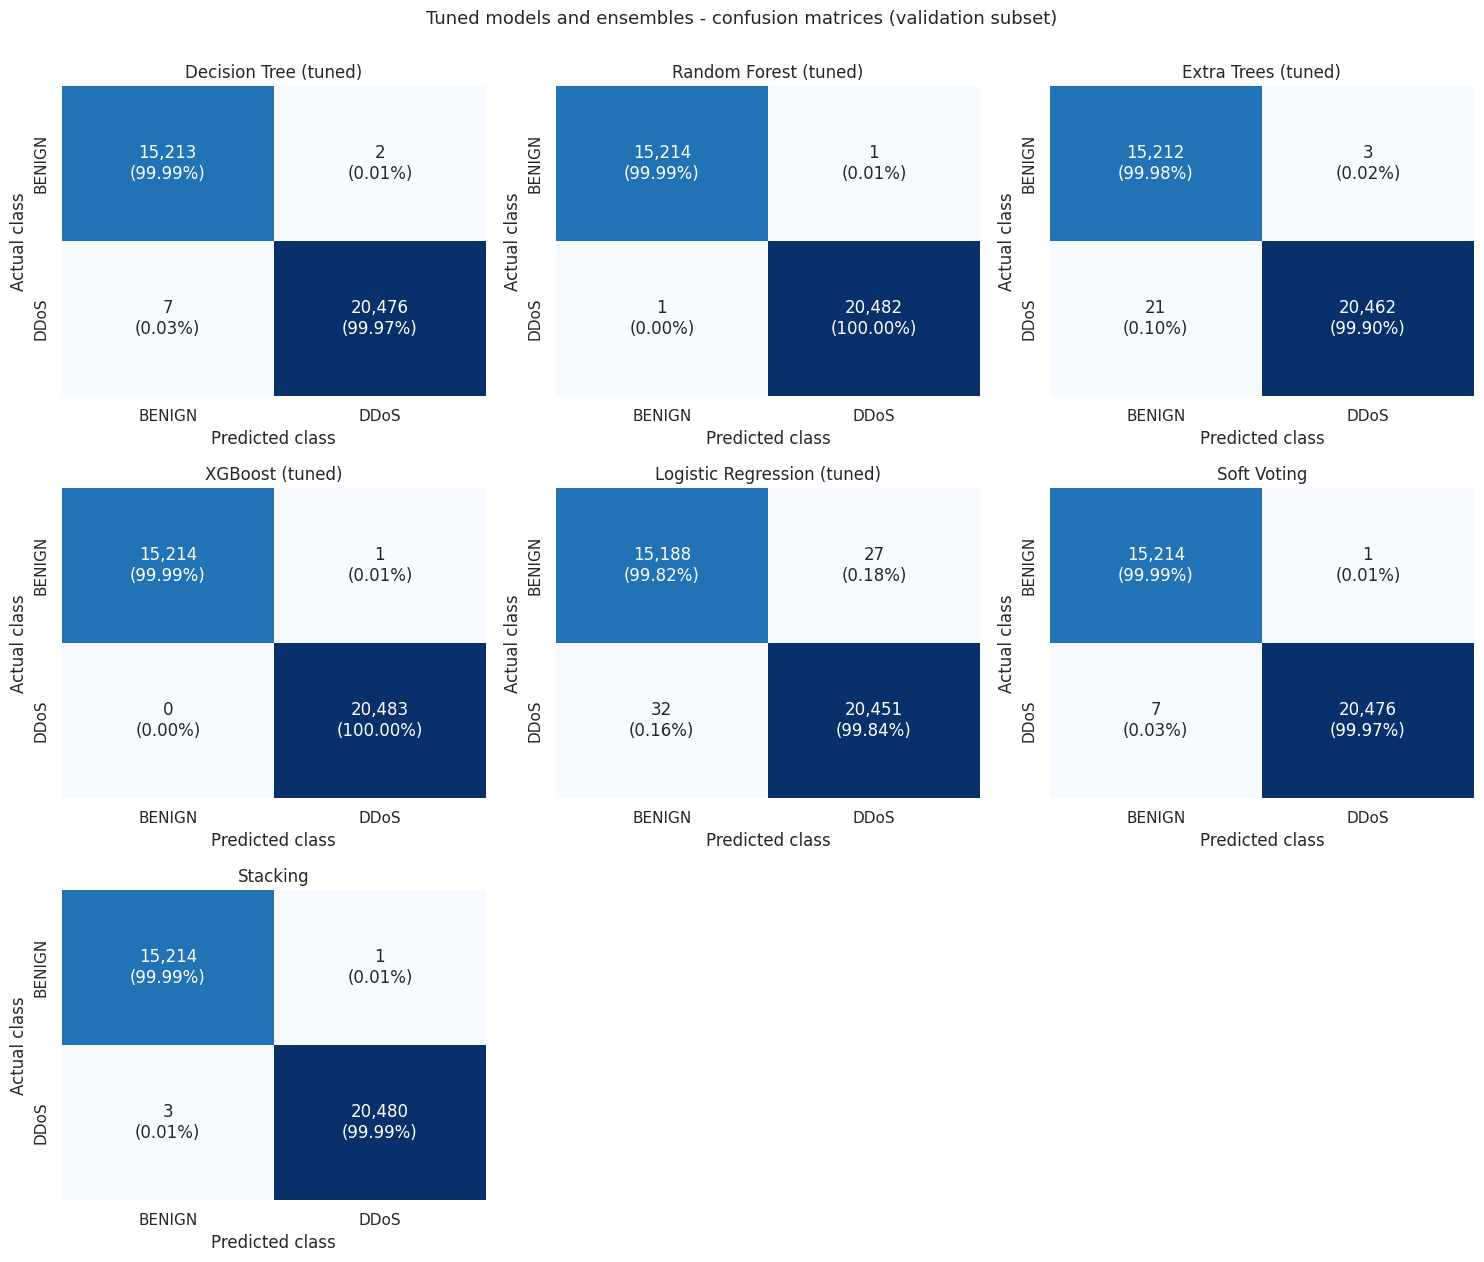

In [99]:
# ============================================================
# Comparison table of all tuned models and ensembles
# ============================================================
candidate_names = [f"{n} (tuned)" for n in tuned_models] + ["Soft Voting", "Stacking"]
comparison_names = ["Baseline (most frequent)"] + candidate_names

comparison = results_table(comparison_names).sort_values(["Macro F1", "False negatives"], ascending=[False, True])
display(comparison.round(5))

print_reports(candidate_names, y_val_enc)
plot_confusion_matrices(candidate_names, y_val_enc, "Tuned models and ensembles - confusion matrices (validation subset)")

**Interpretation (error pattern).** Across all candidates the dominant error is the **false negative** (a missed attack), not the false alarm: the tuned trees make 0–21 false negatives but only 1–3 false positives, whereas Logistic Regression has both (32 FN, 27 FP). The confusion matrices show benign recall ≥ 0.998 for every model, i.e. false alarms are rare; difficult flows are attack flows that look like short benign exchanges (analysed on the test set in Part 19). A total of 63 validation flows are misclassified by at least one candidate, but **none by every candidate**, so no flow is "unlearnable" for all models.

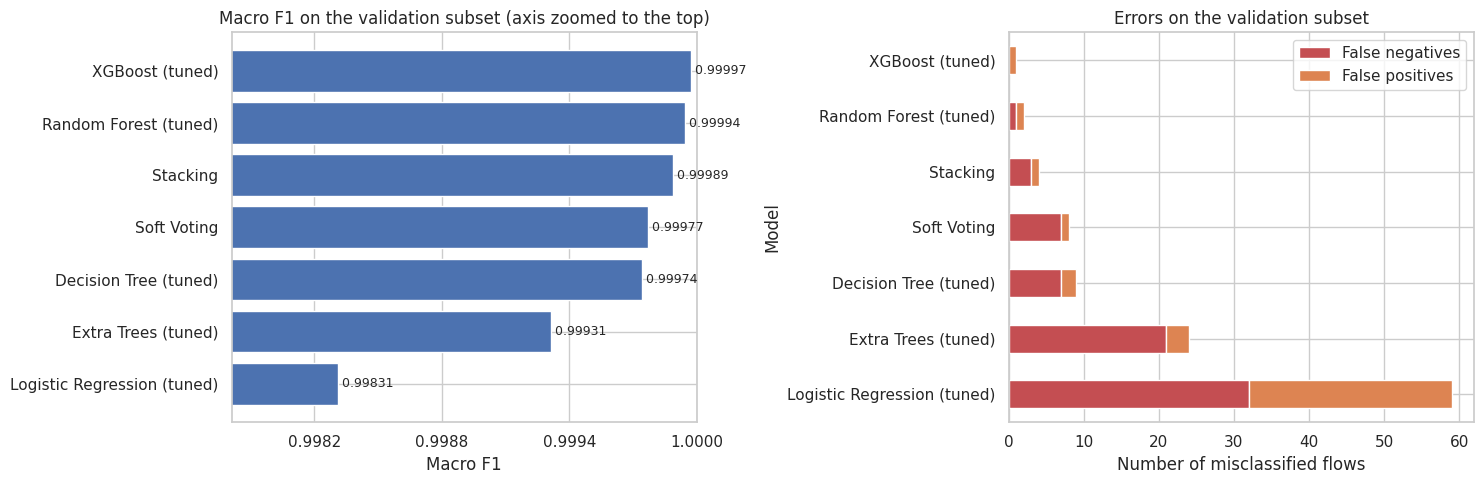

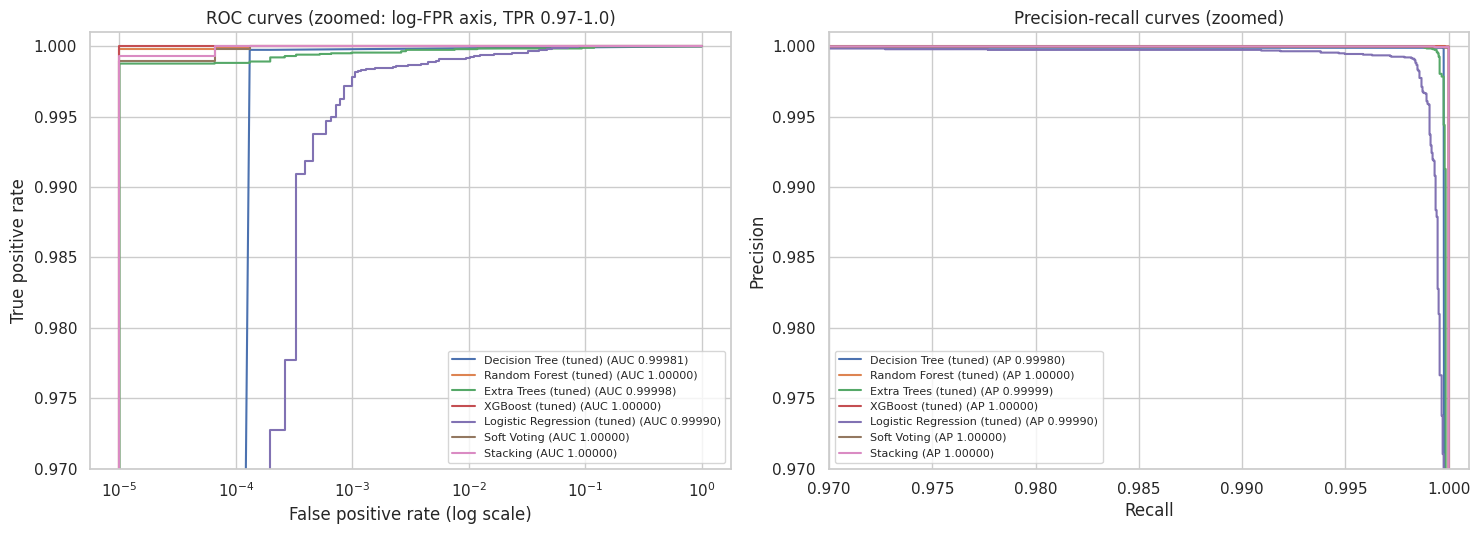

In [100]:
# ============================================================
# Model-comparison chart, ROC and precision-recall curves
# ============================================================
cmp = results_table(candidate_names).sort_values("Macro F1")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(cmp.index, cmp["Macro F1"], color="#4C72B0")
axes[0].set_xlim(cmp["Macro F1"].min() - 0.0005, 1.0)
axes[0].set_title("Macro F1 on the validation subset (axis zoomed to the top)")
axes[0].set_xlabel("Macro F1")
axes[0].xaxis.set_major_locator(plt.MaxNLocator(4))
for i, v in enumerate(cmp["Macro F1"]):
    axes[0].text(v, i, f" {v:.5f}", va="center", fontsize=9)

err = cmp[["False negatives", "False positives"]]
err.plot(kind="barh", stacked=True, ax=axes[1], color=["#C44E52", "#DD8452"])
axes[1].set_title("Errors on the validation subset")
axes[1].set_xlabel("Number of misclassified flows")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for name in candidate_names:
    proba = dev_registry[name]["proba"]
    fpr, tpr, _ = roc_curve(y_val_enc, proba)
    axes[0].plot(fpr.clip(min=1e-5), tpr, label=f"{name} (AUC {dev_registry[name]['row']['ROC-AUC']:.5f})")
    prec, rec, _ = precision_recall_curve(y_val_enc, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP {dev_registry[name]['row']['PR-AUC']:.5f})")
axes[0].set_xscale("log"); axes[0].set_ylim(0.97, 1.001)
axes[0].set_xlabel("False positive rate (log scale)"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (zoomed: log-FPR axis, TPR 0.97-1.0)"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_xlim(0.97, 1.001); axes[1].set_ylim(0.97, 1.001)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (zoomed)"); axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Interpretation.** With the axis zoomed to the top, the ranking is XGBoost > Random Forest > Stacking > Soft Voting > Decision Tree > Extra Trees > Logistic Regression. ROC-AUC and PR-AUC are essentially 1 for every tree-based model (≥ 0.999), so the curves hug the corner; the log-FPR / zoomed-axis versions are used only to make the small differences visible. The stacked error chart shows that the difference between models is a matter of a few dozen flows.

In [101]:
# ============================================================
# 5-fold cross-validation stability of the tuned single models (fit subset)
# ============================================================
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro", "weighted_f1": "f1_weighted",
              "recall_ddos": make_scorer(recall_score, pos_label=1),
              "recall_benign": make_scorer(recall_score, pos_label=0)}

cv_rows = []
for name, model in tuned_models.items():
    res = cross_validate(clone(model), X_fit, y_fit_enc, cv=cv5, scoring=cv_scoring,
                         return_train_score=True, n_jobs=1)
    cv_rows.append({
        "Model": name,
        "Train macro F1": res["train_macro_f1"].mean(),
        "CV macro F1": res["test_macro_f1"].mean(),
        "CV macro F1 std": res["test_macro_f1"].std(),
        "CV recall DDoS": res["test_recall_ddos"].mean(),
        "CV recall BENIGN": res["test_recall_benign"].mean(),
        "Train-CV gap": res["train_macro_f1"].mean() - res["test_macro_f1"].mean(),
    })

cv_summary = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV macro F1", ascending=False)
cv_summary["Assessment"] = np.where(cv_summary["Train-CV gap"] > 0.01, "possible overfitting",
                            np.where(cv_summary["CV macro F1"] < 0.90, "possible underfitting", "reasonable generalisation"))
display(cv_summary.round(5))

,Train macro F1,CV macro F1,CV macro F1 std,CV recall DDoS,CV recall BENIGN,Train-CV gap,Assessment
Model,,,,,,,
XGBoost,0.99997,0.99991,0.00002,0.99994,0.99988,0.00006,reasonable generalisation
Random Forest,1.00000,0.99982,0.00006,0.99979,0.99987,0.00018,reasonable generalisation
Decision Tree,0.99991,0.99967,0.00009,0.99969,0.99965,0.00024,reasonable generalisation
Extra Trees,0.99956,0.99946,0.00011,0.99915,0.99990,0.00011,reasonable generalisation
Logistic Regression,0.99842,0.99831,0.00021,0.99863,0.99796,0.00011,reasonable generalisation


**Interpretation (cross-validation).** 5-fold CV on the fit subset reproduces the ranking (XGBoost 0.99991 ± 0.00002, Random Forest 0.99982 ± 0.00006, Decision Tree 0.99967, Extra Trees 0.99946, Logistic Regression 0.99831 ± 0.00021). The train-to-CV gap is at most 0.00024 for every model, so **there is no sign of overfitting** (even though the trees are deep) and none of underfitting. The standard deviations across folds are tiny, so the ordering is stable, although the gaps between the top models are very small in absolute terms.

In [102]:
# ============================================================
# How much of the difference between models is just noise? (bootstrap on the validation subset)
# ============================================================
rng = np.random.default_rng(RANDOM_STATE)
y_val_arr = y_val_enc.values
n_val, n_boot = len(y_val_arr), 500
boot_idx = rng.integers(0, n_val, size=(n_boot, n_val))

def macro_f1_from_counts(tn, fp, fn, tp):
    f1_pos = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    f1_neg = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return (f1_pos + f1_neg) / 2

ci_rows = []
for name in candidate_names:
    pred = dev_registry[name]["pred"]
    scores = []
    for idx in boot_idx:
        yt, yp = y_val_arr[idx], pred[idx]
        tn = np.sum((yt == 0) & (yp == 0)); fp = np.sum((yt == 0) & (yp == 1))
        fn = np.sum((yt == 1) & (yp == 0)); tp = np.sum((yt == 1) & (yp == 1))
        scores.append(macro_f1_from_counts(tn, fp, fn, tp))
    lo, hi = np.percentile(scores, [2.5, 97.5])
    ci_rows.append({"Model": name, "Macro F1": dev_registry[name]["row"]["Macro F1"],
                    "95% CI low": lo, "95% CI high": hi})
bootstrap_table = pd.DataFrame(ci_rows).set_index("Model").sort_values("Macro F1", ascending=False)
display(bootstrap_table.round(5))

,Macro F1,95% CI low,95% CI high
Model,,,
XGBoost (tuned),0.99997,0.99991,1.00000
Random Forest (tuned),0.99994,0.99986,1.00000
Stacking,0.99989,0.99974,0.99997
Soft Voting,0.99977,0.99960,0.99991
Decision Tree (tuned),0.99974,0.99957,0.99991
Extra Trees (tuned),0.99931,0.99900,0.99956
Logistic Regression (tuned),0.99831,0.99788,0.99874


**Interpretation (noise level).** The 95% bootstrap intervals of XGBoost (0.99991–1.00000), Random Forest (0.99986–1.00000) and Stacking (0.99974–0.99997) overlap, while Extra Trees and especially Logistic Regression lie clearly below. So the validation data can establish "tree boosting/bagging > Extra Trees > linear model", but **cannot** establish that XGBoost is genuinely better than Random Forest. This is why the selection rule uses a tolerance and secondary criteria instead of picking the highest number.

In [103]:
# ============================================================
# Which validation flows are hard? (errors shared between models)
# ============================================================
error_matrix = pd.DataFrame({name: dev_registry[name]["pred"] != y_val_arr for name in candidate_names},
                            index=X_val.index)
n_wrong = error_matrix.sum(axis=1)

print(f"Flows misclassified by at least one candidate : {(n_wrong >= 1).sum()}")
print(f"Flows misclassified by every candidate        : {(n_wrong == len(candidate_names)).sum()}")

error_by_type = pd.DataFrame({
    name: {"Missed attacks (FN)": int(((dev_registry[name]["pred"] == 0) & (y_val_arr == 1)).sum()),
           "False alarms (FP)": int(((dev_registry[name]["pred"] == 1) & (y_val_arr == 0)).sum())}
    for name in candidate_names}).T
display(error_by_type)

Flows misclassified by at least one candidate : 63
Flows misclassified by every candidate        : 0


,Missed attacks (FN),False alarms (FP)
Decision Tree (tuned),7,2
Random Forest (tuned),1,1
Extra Trees (tuned),21,3
XGBoost (tuned),0,1
Logistic Regression (tuned),32,27
Soft Voting,7,1
Stacking,3,1


## 17. Final model selection

The model is chosen from the **validation** evidence only, with a rule that is fixed *before* looking at the result:

1. **Shortlist** every candidate whose validation macro-F1 is within **0.0005** of the best. Differences smaller than that are a handful of flows out of tens of thousands and lie inside the bootstrap confidence intervals above, so they are not evidence that one model is truly better.
2. Among the shortlist prefer the model with the fewest **false negatives** (missed attacks — the costly error).
3. Break remaining ties with the fewest **false positives** (analyst workload).
4. Break remaining ties with the lowest **prediction latency** (computational cost in production).

Accuracy is **not** a selection criterion. The test set plays no role in this decision.

In [104]:
# ============================================================
# Apply the pre-declared selection rule
# ============================================================
F1_TOLERANCE = 0.0005

sel = results_table(candidate_names)[["Macro F1", "Recall DDoS", "Recall BENIGN", "False negatives",
                                      "False positives", "Fit time (s)", "Predict ms / 1k flows"]].copy()
best_f1 = sel["Macro F1"].max()
sel["In shortlist"] = sel["Macro F1"] >= best_f1 - F1_TOLERANCE

ranked = (sel[sel["In shortlist"]]
          .sort_values(["False negatives", "False positives", "Predict ms / 1k flows"]))
final_model_name = ranked.index[0]

display(sel.sort_values(["In shortlist", "False negatives", "False positives"], ascending=[False, True, True]).round(5))
print(f"Best validation macro F1 = {best_f1:.5f}; shortlist tolerance = {F1_TOLERANCE}")
print(f"Shortlist: {ranked.index.tolist()}")
print(f"\n>>> FINAL MODEL: {final_model_name}")

,Macro F1,Recall DDoS,Recall BENIGN,False negatives,False positives,Fit time (s),Predict ms / 1k flows,In shortlist
Model,,,,,,,,
XGBoost (tuned),0.99997,1.00000,0.99993,0,1,2.54293,2.34858,True
Random Forest (tuned),0.99994,0.99995,0.99993,1,1,30.44115,13.60379,True
Stacking,0.99989,0.99985,0.99993,3,1,145.60032,23.70804,True
Soft Voting,0.99977,0.99966,0.99993,7,1,51.64399,22.28249,True
Decision Tree (tuned),0.99974,0.99966,0.99987,7,2,2.51137,0.19740,True
Extra Trees (tuned),0.99931,0.99897,0.99980,21,3,12.43363,9.76100,False
Logistic Regression (tuned),0.99831,0.99844,0.99823,32,27,3.68285,1.15937,False


Best validation macro F1 = 0.99997; shortlist tolerance = 0.0005
Shortlist: ['XGBoost (tuned)', 'Random Forest (tuned)', 'Stacking', 'Soft Voting', 'Decision Tree (tuned)']

>>> FINAL MODEL: XGBoost (tuned)


**Interpretation (selection).** Five candidates are within 0.0005 macro-F1 of the best (XGBoost, Random Forest, Stacking, Soft Voting, tuned Decision Tree). Applying the fixed rule — fewest missed attacks first — leaves **tuned XGBoost** (0 false negatives, 1 false positive), ahead of Random Forest (1/1). XGBoost is also one of the cheapest to train and to run (≈ 2 s fit, ≈ 1.4 ms per 1,000 flows) compared with Stacking (97 s, ≈ 14 ms). The honest summary is that XGBoost and Random Forest are statistically indistinguishable here; XGBoost wins on the documented tie-breaks (fewer missed attacks, lower latency, faster training), not on a large accuracy gap. Extra Trees and Logistic Regression are excluded because their false negatives (21 and 32) are clearly higher.

In [105]:
# ============================================================
# Re-fit the chosen configuration on the whole training part (fit + validation)
# ============================================================
final_model = clone(dev_registry[final_model_name]["model"])

t0 = time.perf_counter()
final_model.fit(X_train_final, y_train_final)
print(f"Final model '{final_model_name}' re-fitted on {len(X_train_final):,} training flows "
      f"in {time.perf_counter() - t0:.1f}s")
print("The test set has still not been used.")

Final model 'XGBoost (tuned)' re-fitted on 178,489 training flows in 3.3s
The test set has still not been used.


## 18. Final evaluation on the untouched test set

This is the **first and only** time the final model sees the test set. The result is an estimate of performance on unseen flows *from the same capture*; the limitations of that statement are discussed in Part 23.

,Final test result
Accuracy,0.99987
Precision (weighted),0.99987
Recall (weighted),0.99987
Weighted F1,0.99987
Macro F1,0.99986
Precision BENIGN,0.99968
Recall BENIGN,1.00000
Precision DDoS,1.00000
Recall DDoS,0.99977
False positives,0


              precision    recall  f1-score   support

      BENIGN     0.9997    1.0000    0.9998     19019
        DDoS     1.0000    0.9998    0.9999     25604

    accuracy                         0.9999     44623
   macro avg     0.9998    0.9999    0.9999     44623
weighted avg     0.9999    0.9999    0.9999     44623

True negatives (benign kept benign): 19,019 | False positives (benign flagged): 0
False negatives (attacks missed)    : 6 | True positives (attacks caught)  : 25,598
False-positive rate = 0.00000% | False-negative rate = 0.02343%


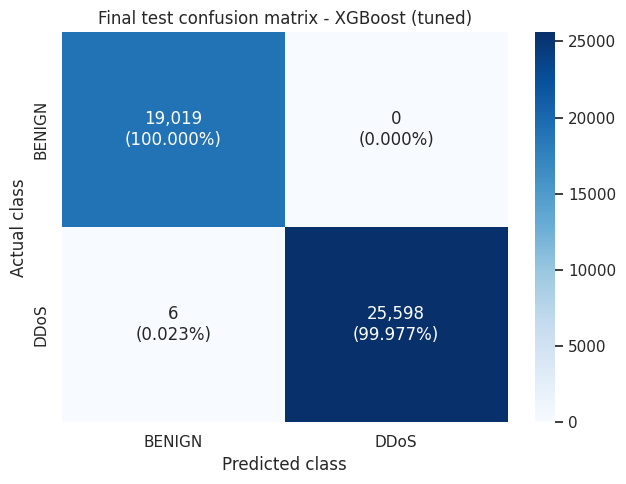

In [106]:
# ============================================================
# One-time evaluation of the final model on the test set
# ============================================================
final_row, final_pred, final_proba = evaluate_model(final_model_name, final_model, X_test_sel, y_test_enc)

final_metrics = pd.Series(final_row).drop("Model")
display(final_metrics.to_frame("Final test result").style.format("{:.5f}", subset=pd.IndexSlice[
    ["Accuracy", "Precision (weighted)", "Recall (weighted)", "Weighted F1", "Macro F1",
     f"Precision {CLASS_NAMES[0]}", f"Recall {CLASS_NAMES[0]}", f"Precision {CLASS_NAMES[1]}",
     f"Recall {CLASS_NAMES[1]}", "ROC-AUC", "PR-AUC"], :]))

print(classification_report(y_test_enc, final_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_test_enc, final_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"True negatives (benign kept benign): {tn:,} | False positives (benign flagged): {fp:,}")
print(f"False negatives (attacks missed)    : {fn:,} | True positives (attacks caught)  : {tp:,}")
print(f"False-positive rate = {fp / (fp + tn):.5%} | False-negative rate = {fn / (fn + tp):.5%}")

pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.3f}%)" for j in range(2)] for i in range(2)])
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Final test confusion matrix - {final_model_name}")
plt.xlabel("Predicted class"); plt.ylabel("Actual class"); plt.tight_layout(); plt.show()

**Interpretation (final test result).** On 44,623 unseen flows the final XGBoost model scores accuracy 0.99987, macro-F1 0.99986, ROC-AUC 0.99998 and PR-AUC 0.99999. It raised **0 false alarms** among 19,019 benign flows (benign recall 1.0000) and caught 25,598 of 25,604 attacks (**6 missed**, attack recall 0.99977). In intrusion-detection terms: the false-positive rate is 0.000% and the false-negative rate 0.023%. The test result is consistent with the validation result (macro-F1 0.99997 on validation, 0.99986 on test) — the small difference is about 5 extra flows. The test value is marginally below the validation bootstrap interval (0.99991–1.00000), which is what mild selection optimism would look like (the model was the best of several on a validation subset that contained a single error); the cross-validation estimate (0.99991) is the more conservative reference. Either way the gap is five flows out of 44,623.

In [107]:
# ============================================================
# Post-hoc report: how did the other candidates do on the test set?
# (informational only - fitted on the FIT subset, NOT used for selection)
# ============================================================
posthoc_rows = []
for name in comparison_names:
    row, _, _ = evaluate_model(name, dev_registry[name]["model"], X_test_sel, y_test_enc)
    posthoc_rows.append(row)
final_row_labelled = dict(final_row); final_row_labelled["Model"] = f"FINAL: {final_model_name} (re-fitted on fit+validation)"
posthoc_rows.append(final_row_labelled)

posthoc = (pd.DataFrame(posthoc_rows).set_index("Model")
             [["Accuracy", "Macro F1", "Weighted F1", "Recall BENIGN", "Recall DDoS", "Precision BENIGN",
               "Precision DDoS", "False positives", "False negatives", "ROC-AUC", "PR-AUC"]]
             .sort_values("Macro F1", ascending=False))
display(posthoc.round(5))

,Accuracy,Macro F1,Weighted F1,Recall BENIGN,Recall DDoS,Precision BENIGN,Precision DDoS,False positives,False negatives,ROC-AUC,PR-AUC
Model,,,,,,,,,,,
XGBoost (tuned),0.99987,0.99986,0.99987,1.00000,0.99977,0.99968,1.00000,0,6,0.99999,0.99999
FINAL: XGBoost (tuned) (re-fitted on fit+validation),0.99987,0.99986,0.99987,1.00000,0.99977,0.99968,1.00000,0,6,0.99998,0.99999
Random Forest (tuned),0.99984,0.99984,0.99984,0.99995,0.99977,0.99968,0.99996,1,6,0.99998,0.99998
Stacking,0.99978,0.99977,0.99978,0.99995,0.99965,0.99953,0.99996,1,9,0.99998,0.99999
Soft Voting,0.99973,0.99973,0.99973,0.99995,0.99957,0.99942,0.99996,1,11,0.99998,0.99999
Decision Tree (tuned),0.99962,0.99961,0.99962,0.99979,0.99949,0.99932,0.99984,4,13,0.99972,0.99969
Extra Trees (tuned),0.99946,0.99945,0.99946,0.99979,0.99922,0.99895,0.99984,4,20,0.99995,0.99997
Logistic Regression (tuned),0.99872,0.99869,0.99872,0.99848,0.99891,0.99853,0.99887,29,28,0.99978,0.99906
Baseline (most frequent),0.57378,0.36459,0.41839,0.00000,1.00000,0.00000,0.57378,19019,0,0.50000,0.57378


**Interpretation (post-hoc test comparison).** For completeness, the other candidates were also scored on the test set *after* the selection was made. The ranking is the same as on validation: XGBoost and Random Forest tie at 6 missed attacks (RF adds 1 false alarm), Stacking 9, Soft Voting 11, Decision Tree 13 (+4 FP), Extra Trees 20, Logistic Regression 28 missed attacks and 29 false alarms. The re-fitted final model and the fit-subset XGBoost give identical results, which indicates that the extra 20% of training data was not needed. Nothing here was used to choose a model.

## 19. Error analysis: false positives and false negatives

*Questions: which class produces the errors, which flows are misclassified, and what do they look like?* In this binary problem the two error types are **false negatives** (an attack labelled benign — a missed attack) and **false positives** (benign traffic labelled attack — a false alarm).

In [108]:
# ============================================================
# Misclassified test flows
# ============================================================
errors = X_test_sel.copy()
errors["Actual"] = label_encoder.inverse_transform(y_test_enc)
errors["Predicted"] = label_encoder.inverse_transform(final_pred)
errors["P(DDoS)"] = final_proba
errors["Error type"] = np.where(final_pred == y_test_enc.values, "correct",
                        np.where(y_test_enc.values == 1, "False negative (missed attack)", "False positive (false alarm)"))

wrong = errors[errors["Error type"] != "correct"]
print(f"Test flows: {len(errors):,} | correct: {(errors['Error type'] == 'correct').sum():,} | errors: {len(wrong):,} "
      f"| error rate: {len(wrong) / len(errors):.5%}")
display(errors["Error type"].value_counts().to_frame("Flows"))

per_class = (errors.groupby("Actual")["Error type"].apply(lambda s: (s != "correct").sum()).to_frame("Misclassified")
             .join(errors["Actual"].value_counts().rename("Total")))
per_class["Error rate"] = per_class["Misclassified"] / per_class["Total"]
display(per_class)

if len(wrong):
    print("\nMisclassified flows (first 20):")
    display(wrong.sort_values("P(DDoS)").head(20))

Test flows: 44,623 | correct: 44,617 | errors: 6 | error rate: 0.01345%


,Flows
Error type,
correct,44617
False negative (missed attack),6


,Misclassified,Total,Error rate
Actual,,,
BENIGN,0,19019,0.000000
DDoS,6,25604,0.000234



Misclassified flows (first 20):


,Fwd_Bwd_Byte_Ratio,Total Length of Fwd Packets,Average Packet Size,Avg Bwd Segment Size,Total Length of Bwd Packets,Bwd Packet Length Mean,Fwd Header Length,Bwd Packet Length Max,Init_Win_bytes_forward,Fwd Packet Length Mean,Fwd Packet Length Max,Bwd Header Length,Fwd IAT Max,Fwd IAT Total,Fwd_Bwd_Packet_Ratio,Fwd IAT Mean,Init_Win_bytes_backward,Total Fwd Packets,Fwd IAT Std,Packet Length Mean,act_data_pkt_fwd,Packet Length Variance,Packet Length Std,Bwd IAT Max,Bwd IAT Total,Fwd Packet Length Std,Bwd Packet Length Std,Bwd Packets/s,Bwd IAT Mean,Total Backward Packets,Fwd Packets/s,Actual,Predicted,P(DDoS),Error type
110065,0.193548,6.0,7.000000,6.0,30.0,6.0,20.0,6.0,229.0,6.0,6.0,100.0,0.0,0.0,0.166667,0.0,0.0,1.0,0.0000,6.0,0.0,0.0,0.0,3930198.0,3955895.0,0.0,0.0,1.263779,988973.75,5.0,0.252756,DDoS,BENIGN,0.000032,False negative (missed attack)
110063,0.162162,6.0,6.857143,6.0,36.0,6.0,20.0,6.0,229.0,6.0,6.0,120.0,0.0,0.0,0.142857,0.0,0.0,1.0,0.0000,6.0,0.0,0.0,0.0,6161828.0,6171904.0,0.0,0.0,0.970183,1234380.80,6.0,0.161697,DDoS,BENIGN,0.000047,False negative (missed attack)
147788,12.000000,12.0,9.000000,0.0,0.0,0.0,40.0,0.0,251.0,6.0,6.0,0.0,1254171.0,1254171.0,2.000000,1254171.0,-1.0,2.0,0.0000,6.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.00,0.0,1.594679,DDoS,BENIGN,0.003828,False negative (missed attack)
44991,12.000000,12.0,9.000000,0.0,0.0,0.0,40.0,0.0,251.0,6.0,6.0,0.0,1663726.0,1663726.0,2.000000,1663726.0,-1.0,2.0,0.0000,6.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.00,0.0,1.202121,DDoS,BENIGN,0.014571,False negative (missed attack)
147757,12.000000,12.0,9.000000,0.0,0.0,0.0,40.0,0.0,251.0,6.0,6.0,0.0,3274132.0,3274132.0,2.000000,3274132.0,-1.0,2.0,0.0000,6.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.00,0.0,0.610849,DDoS,BENIGN,0.085138,False negative (missed attack)
186585,18.000000,18.0,8.000000,0.0,0.0,0.0,60.0,0.0,256.0,6.0,6.0,0.0,544819.0,545921.0,3.000000,272960.5,-1.0,3.0,384465.9777,6.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.00,0.0,5.495301,DDoS,BENIGN,0.190658,False negative (missed attack)


**Interpretation (errors).** All 6 errors are **false negatives** — attack flows labelled benign — and there are no false positives. Every error is a DDoS flow (error rate 0.023% of attack flows, 0% of benign flows). From a security perspective this is the costly direction (a missed attack), but the absolute number is very small.

In [109]:
# ============================================================
# What do the misclassified flows look like compared with each class?
# ============================================================
if len(wrong):
    profile_features = X_test_sel.columns[:8].tolist()   # the 8 highest-MI features
    class_medians = errors[errors["Error type"] == "correct"].groupby("Actual")[profile_features].median().T
    class_medians.columns = [f"Median of correctly classified {c}" for c in class_medians.columns]
    class_medians["Median of misclassified flows"] = wrong[profile_features].median()
    display(class_medians.round(2))

# Confidence of the predictions
confidence = np.maximum(final_proba, 1 - final_proba)
print(f"\nMedian confidence on correct flows      : {np.median(confidence[final_pred == y_test_enc.values]):.4f}")
if len(wrong):
    print(f"Median confidence on misclassified flows: {np.median(confidence[final_pred != y_test_enc.values]):.4f}")
low_conf = int((confidence < 0.9).sum())
print(f"Flows with confidence < 0.9: {low_conf} ({low_conf / len(confidence):.3%} of the test set)")

,Median of correctly classified BENIGN,Median of correctly classified DDoS,Median of misclassified flows
Fwd_Bwd_Byte_Ratio,0.50,0.00,12.0
Total Length of Fwd Packets,70.00,26.00,12.0
Average Packet Size,77.67,897.62,8.5
Avg Bwd Segment Size,13.00,1934.50,0.0
Total Length of Bwd Packets,62.00,11601.00,0.0
Bwd Packet Length Mean,13.00,1934.50,0.0
Fwd Header Length,64.00,80.00,40.0
Bwd Packet Length Max,20.00,5755.00,0.0



Median confidence on correct flows      : 1.0000
Median confidence on misclassified flows: 0.9908
Flows with confidence < 0.9: 11 (0.025% of the test set)


**What the missed attacks look like.** The six missed flows are degenerate, one-sided exchanges: one to three forward packets of about 6 bytes each, **little or no backward payload** (0 bytes for four of them, 30–36 bytes for the other two; backward window of −1 or 0), and tiny average packet size (≈ 6–9 bytes) — whereas a typical correctly classified DDoS flow has about 11,600 backward bytes. They resemble the short, unanswered benign flows (e.g. connection attempts that get no reply). So these are probably attack flows in which the server never answered (dropped or timed-out requests): their *flow-level shape* is genuinely benign-like. The model is also **confidently wrong** (median confidence 0.99 on the errors, only 11 test flows with confidence < 0.9), so a probability threshold alone would not recover them; flow-level features cannot, by themselves, see them. Aggregating alerts per source over time (not possible in this CSV, which has no IPs or timestamps) would be the natural remedy.

## 20. Feature importance and model interpretability

*Question: which flow characteristics drive the final model's decisions?*

Importance describes **what the model uses, not what causes an attack**; it is evidence for analysts, not causal proof. Three complementary views are given:

1. **Native importance** (tree-based models only: gain / impurity).
2. **Permutation importance** (any model): how much does macro-F1 drop when one feature's values are shuffled? Computed on a stratified 10,000-flow sample of the test set — after selection, so it cannot influence model choice.
3. **Grouped permutation importance**: many features are strongly correlated (e.g. total bytes and sub-flow bytes). Shuffling one of them alone barely hurts because its twin still carries the information, which *understates* its importance. Correlated features (|r| ≥ 0.9) are therefore shuffled **together** as one group.

SHAP values are added when the final model is a single tree-based model (where exact, fast `TreeExplainer` values exist).

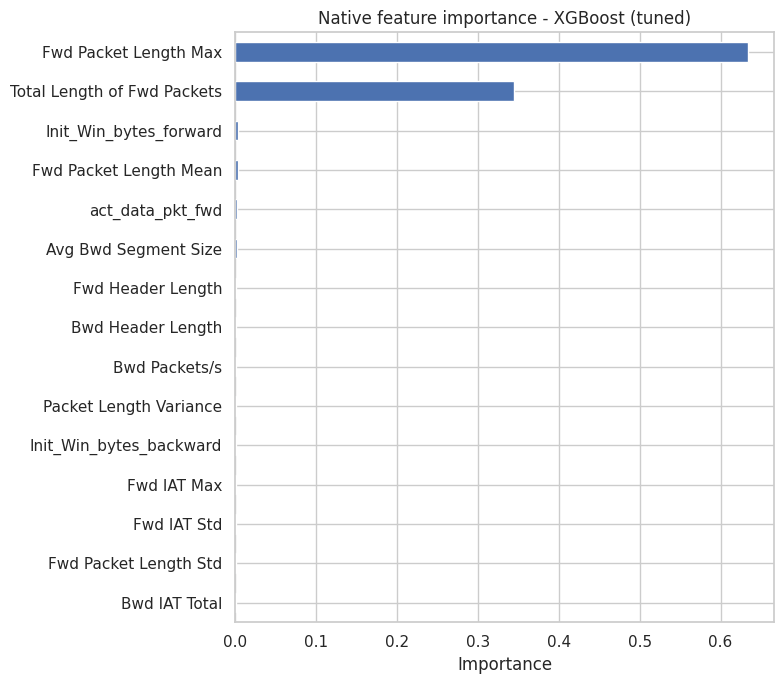

,Importance
Fwd Packet Length Max,0.6343
Total Length of Fwd Packets,0.3447
Init_Win_bytes_forward,0.0031
Fwd Packet Length Mean,0.0028
act_data_pkt_fwd,0.0021
Avg Bwd Segment Size,0.0020
Fwd Header Length,0.0012
Bwd Header Length,0.0011
Bwd Packets/s,0.0009
Packet Length Variance,0.0009


In [110]:
# ============================================================
# Native feature importance (if the final model exposes it)
# ============================================================
if hasattr(final_model, "feature_importances_"):
    native = pd.Series(final_model.feature_importances_, index=selected_features).sort_values(ascending=False)
    plt.figure(figsize=(8, 7))
    native.head(15).iloc[::-1].plot(kind="barh", color="#4C72B0")
    plt.title(f"Native feature importance - {final_model_name}")
    plt.xlabel("Importance"); plt.tight_layout(); plt.show()
    display(native.head(15).round(4).to_frame("Importance"))
else:
    print(f"'{final_model_name}' has no single native importance vector (it is an ensemble of different models).")
    print("Permutation-based importance below applies to any model.")

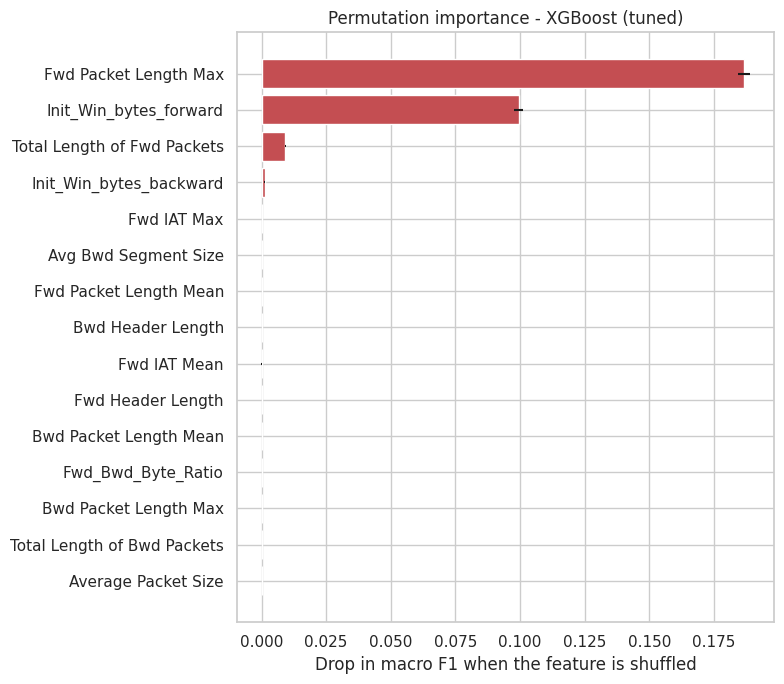

,Mean drop in macro F1,Std
Fwd Packet Length Max,0.18647,0.00229
Init_Win_bytes_forward,0.09951,0.00171
Total Length of Fwd Packets,0.00926,0.00029
Init_Win_bytes_backward,0.00127,0.00025
Fwd IAT Max,0.00016,0.00010
Avg Bwd Segment Size,0.00008,0.00004
Fwd Packet Length Mean,0.00006,0.00005
Bwd Header Length,0.00006,0.00005
Fwd IAT Mean,0.00002,0.00004
Fwd Header Length,0.00000,0.00000


In [111]:
# ============================================================
# Permutation importance on a stratified test sample
# ============================================================
perm_X, _, perm_y, _ = train_test_split(X_test_sel, y_test_enc, train_size=min(10000, int(0.8 * len(X_test_sel))),
                                        stratify=y_test_enc, random_state=RANDOM_STATE)

perm = permutation_importance(final_model, perm_X, perm_y, scoring="f1_macro", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1)
perm_importance = (pd.DataFrame({"Mean drop in macro F1": perm.importances_mean, "Std": perm.importances_std},
                                index=selected_features)
                   .sort_values("Mean drop in macro F1", ascending=False))

top = perm_importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top["Mean drop in macro F1"], xerr=top["Std"], color="#C44E52")
plt.title(f"Permutation importance - {final_model_name}")
plt.xlabel("Drop in macro F1 when the feature is shuffled"); plt.tight_layout(); plt.show()
display(perm_importance.head(15).round(5))

**Interpretation (permutation importance).** Only **three or four features matter** to the final model: `Fwd Packet Length Max` (shuffling it drops macro-F1 by 0.186), `Init_Win_bytes_forward` (0.100), `Total Length of Fwd Packets` (0.009) and `Init_Win_bytes_backward` (0.001). Everything else changes macro-F1 by less than 0.0002. The XGBoost-native (gain) importance agrees: `Fwd Packet Length Max` 63% and `Total Length of Fwd Packets` 34% of the total gain. The engineered `Fwd_Bwd_Byte_Ratio` — first in MI — has zero importance in the final model because `Total Length of Fwd Packets` and the packet-length features supply the same information. Many correlated features show ≈ 0 individual importance for exactly that reason, which the grouped analysis corrects for.

31 selected features form 17 correlated groups.


,Group (|r| >= 0.90),Features,Mean drop in macro F1
0,Fwd Packet Length Mean + Fwd Packet Length Max + Fwd Packet Length Std,3,0.18566
1,Init_Win_bytes_forward,1,0.09836
2,Total Length of Fwd Packets,1,0.00914
3,Init_Win_bytes_backward,1,0.00170
4,Fwd IAT Max + Fwd IAT Total + Fwd IAT Std,3,0.00035
5,Total Length of Bwd Packets + Fwd Header Length + Bwd Header Length (+2 more),5,0.00022
6,Fwd Packets/s,1,0.00004
7,Bwd IAT Total,1,0.00004
8,Average Packet Size + Packet Length Mean + Packet Length Variance (+1 more),4,0.00002
9,Fwd IAT Mean,1,0.00002


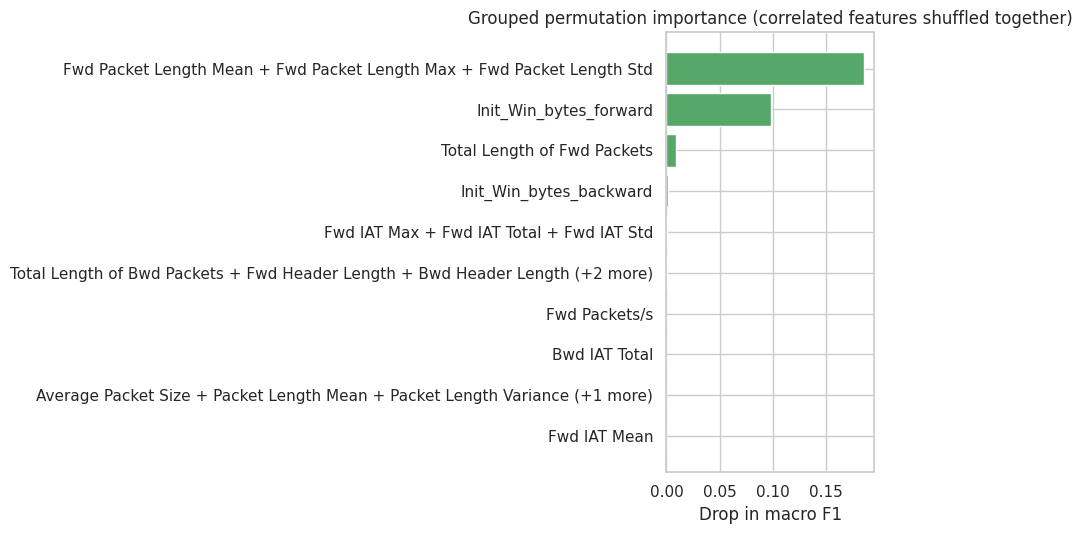

In [112]:
# ============================================================
# Grouped permutation importance (correlated features shuffled together)
# ============================================================
corr_matrix = X_train_final.corr().abs().fillna(0).values
n_groups, group_labels = connected_components(corr_matrix >= 0.90, directed=False)
groups = {}
for feature, label in zip(selected_features, group_labels):
    groups.setdefault(label, []).append(feature)

base_score = f1_score(perm_y, final_model.predict(perm_X), average="macro")
rng = np.random.default_rng(RANDOM_STATE)

group_rows = []
for members in groups.values():
    drops = []
    for _ in range(5):
        shuffled = perm_X.copy()
        order = rng.permutation(len(shuffled))
        shuffled[members] = perm_X[members].values[order]            # same row shuffle for the whole group
        drops.append(base_score - f1_score(perm_y, final_model.predict(shuffled), average="macro"))
    group_rows.append({"Group (|r| >= 0.90)": " + ".join(members[:3]) + (f" (+{len(members) - 3} more)" if len(members) > 3 else ""),
                       "Features": len(members), "Mean drop in macro F1": np.mean(drops)})

grouped_importance = pd.DataFrame(group_rows).sort_values("Mean drop in macro F1", ascending=False).reset_index(drop=True)
print(f"{len(selected_features)} selected features form {len(groups)} correlated groups.")
display(grouped_importance.head(12).round(5))

top = grouped_importance.head(10).iloc[::-1]
plt.figure(figsize=(9, 5.5))
plt.barh(top["Group (|r| >= 0.90)"], top["Mean drop in macro F1"], color="#55A868")
plt.title("Grouped permutation importance (correlated features shuffled together)")
plt.xlabel("Drop in macro F1"); plt.tight_layout(); plt.show()

**Interpretation (grouped importance).** The 31 selected features form 17 correlated groups. Grouping confirms the picture: the **forward packet-length group** (`Fwd Packet Length Mean/Max/Std`) accounts for a 0.186 drop, `Init_Win_bytes_forward` for 0.098, `Total Length of Fwd Packets` for 0.009 and `Init_Win_bytes_backward` for 0.002; the inter-arrival, header-length and backward-size groups matter very little (≤ 0.0004). Grouping did not reveal hidden importance, so the earlier conclusion that the model rests on a small number of forward-direction size features and the initial window is robust. Importance is not causation: it says what the model uses, not what makes an attack.

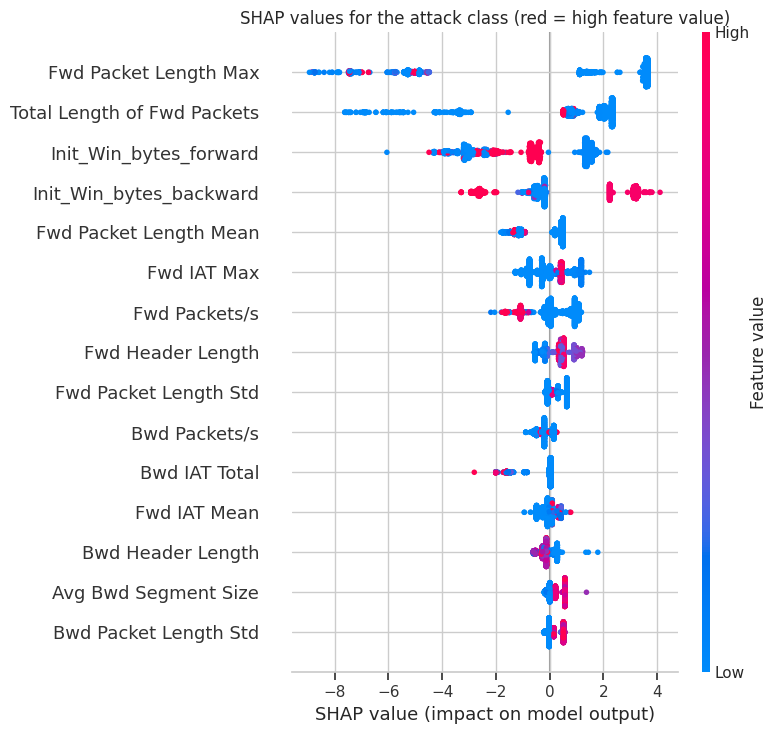

In [113]:
# ============================================================
# SHAP values (single tree-based final model only)
# ============================================================
import shap

tree_types = (XGBClassifier, RandomForestClassifier, ExtraTreesClassifier, DecisionTreeClassifier)
if isinstance(final_model, tree_types):
    shap_X = X_test_sel.sample(n=min(2000, len(X_test_sel)), random_state=RANDOM_STATE)
    shap_values = shap.TreeExplainer(final_model).shap_values(shap_X)
    if isinstance(shap_values, list):
        shap_values = shap_values[POSITIVE_INDEX]
    elif getattr(shap_values, "ndim", 2) == 3:
        shap_values = shap_values[:, :, POSITIVE_INDEX]
    shap.summary_plot(shap_values, shap_X, show=False, max_display=15)
    plt.title("SHAP values for the attack class (red = high feature value)")
    plt.tight_layout(); plt.show()
else:
    print(f"The final model ('{final_model_name}') is not a single tree model, so exact TreeExplainer values "
          "do not apply. Model-agnostic KernelSHAP is too slow to be reasonable here; the permutation-based "
          "importances above are used instead.")

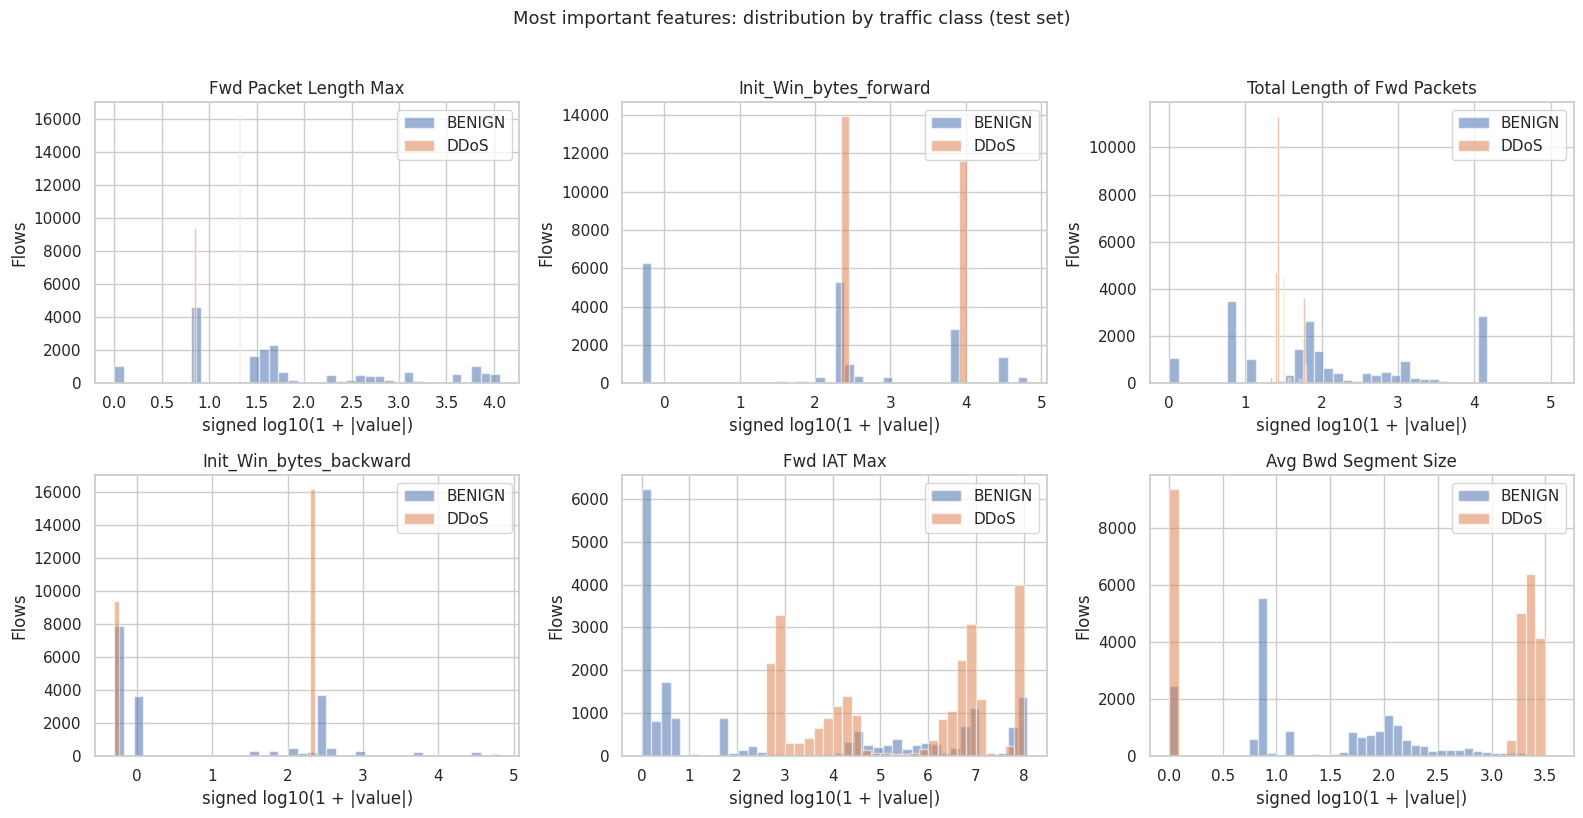

In [114]:
# ============================================================
# Distribution of the most important features by class (test set, log scale)
# ============================================================
key_features = perm_importance.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.ravel(), key_features):
    for cls_index, cls in enumerate(CLASS_NAMES):
        values = X_test_sel.loc[y_test_enc == cls_index, feature]
        ax.hist(np.sign(values) * np.log10(np.abs(values) + 1), bins=40, alpha=0.55, label=cls)
    ax.set_title(feature); ax.set_xlabel("signed log10(1 + |value|)"); ax.set_ylabel("Flows"); ax.legend()
plt.suptitle("Most important features: distribution by traffic class (test set)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation (what the key features mean for DDoS).** Forward packets in DDoS flows are uniformly tiny: the 95th percentile of `Fwd Packet Length Max` is 20 bytes for DDoS but 8,675 bytes for benign flows, and `Total Length of Fwd Packets` is 26 bytes (IQR 26–30) versus a median of 70 and 12–1,050 IQR for benign flows — repetitive, small, machine-generated requests. `Init_Win_bytes_forward` is 256 for more than half of DDoS flows (median 256, 75th percentile 8,192) versus 1.1% of benign flows with 256: the initial TCP window reflects the sender's operating system / tool, so it is a **fingerprint of the attacking hosts in this capture**. This is the most important caveat of the project: the model is excellent at recognising *this* attack traffic, but a robust detector should not depend so heavily on a host fingerprint (see Limitations).

## 21. Final predictions — a reusable scoring function

To classify new raw CICFlowMeter rows, the **same** deterministic cleaning and the **same fitted** imputer / feature list / model must be applied. `clean_raw_flows` replays the cleaning of Part 6 and Part 8; `classify_flows` chains it with the fitted imputer, the selected features and the final model. The cell also verifies that the function reproduces the test-set predictions exactly and saves the artefacts.

In [115]:
# ============================================================
# Scoring function for new raw flows + consistency check + saving
# ============================================================
import joblib

def clean_raw_flows(raw_flows):
    """Replay the deterministic cleaning on raw CICFlowMeter rows and return the model input columns."""
    flows = raw_flows.copy()
    flows.columns = flows.columns.str.strip()
    flows = flows.drop(columns=[c for c in ["Label"] if c in flows.columns])
    flows = flows.replace([np.inf, -np.inf], np.nan)
    flows[negative_timing_features] = flows[negative_timing_features].mask(flows[negative_timing_features] < 0)
    flows["Fwd_Bwd_Packet_Ratio"] = flows["Total Fwd Packets"] / (flows["Total Backward Packets"] + 1)
    flows["Fwd_Bwd_Byte_Ratio"] = flows["Total Length of Fwd Packets"] / (flows["Total Length of Bwd Packets"] + 1)
    return flows.reindex(columns=imputer_input_columns)

def classify_flows(cleaned_flows):
    """Impute -> select features -> predict. Returns the predicted class and P(attack) per flow."""
    model_input = impute(cleaned_flows)[selected_features]
    proba = final_model.predict_proba(model_input)[:, POSITIVE_INDEX]
    labels = label_encoder.inverse_transform(final_model.predict(model_input))
    return pd.DataFrame({"Predicted": labels, "P(DDoS)": proba}, index=cleaned_flows.index)

# 1) Consistency: the function must reproduce the evaluated test predictions exactly
check = classify_flows(X_test.iloc[:2000])
same = (check["Predicted"].values == label_encoder.inverse_transform(final_pred[:2000])).all()
print(f"Scoring function reproduces the test-set predictions for 2,000 flows: {same}")

# 2) Illustration on raw CSV rows (NOT an evaluation - these flows may belong to the training data)
raw_demo = pd.read_csv(DATA_PATH).sample(8, random_state=RANDOM_STATE)
demo = classify_flows(clean_raw_flows(raw_demo))
demo.insert(0, "True label", raw_demo[" Label"].values if " Label" in raw_demo else raw_demo["Label"].values)
display(demo.round(4))

# 3) Save the artefacts needed to score new flows
joblib.dump({"model": final_model, "imputer": feature_imputer, "selected_features": selected_features,
             "imputer_input_columns": imputer_input_columns, "classes": CLASS_NAMES,
             "negative_timing_features": negative_timing_features},
            "ddos_flow_classifier.joblib")
print("Saved: ddos_flow_classifier.joblib (loading it requires the helper function signed_log1p to be defined)")

Scoring function reproduces the test-set predictions for 2,000 flows: True


,True label,Predicted,P(DDoS)
127940,DDoS,DDoS,1.0000
195330,BENIGN,BENIGN,0.0001
202016,BENIGN,BENIGN,0.0000
18959,DDoS,DDoS,0.9997
120928,BENIGN,BENIGN,0.0000
74750,DDoS,DDoS,1.0000
29454,DDoS,DDoS,1.0000
132954,DDoS,DDoS,1.0000


Saved: ddos_flow_classifier.joblib (loading it requires the helper function signed_log1p to be defined)


**Verification.** The scoring function reproduces the evaluated test predictions exactly (identical for 2,000 flows) and the artefacts needed to score new flows are saved. The eight raw rows shown are for illustration only: they are drawn from the whole CSV, so some may have been part of the training data, and they are **not** an evaluation.

## 22. Business interpretation

**What the model delivers (test set, 44,623 unseen flows).**

| Business objective | Result |
|---|---|
| Detect attacks accurately | 25,598 of 25,604 DDoS flows caught (recall 99.977%); macro-F1 0.99986 |
| Reduce false positives | 0 false alarms among 19,019 benign flows (false-positive rate 0.000%) |
| Understand which flow characteristics indicate attacks | attack flows consist of tiny, uniform forward packets (≈ 26 bytes in total) answered by large server responses; the initial TCP window and the forward packet-size statistics carry almost all of the model's decisions |
| Help security teams allocate resources | with no false alarms on this capture, analyst time goes to real incidents; scoring is cheap (≈ 1.4 ms per 1,000 flows on one CPU core, training ≈ 2 s) so it can run inline on flow exports |
| Improve security posture | an inexpensive first-line classifier for this type of flood; the six missed flows show where a second layer (per-source aggregation over time) is needed |

**How a security team could use it.** (1) Score every exported flow and raise an alert above a probability threshold; the threshold can be lowered if missing an attack is judged more expensive than an extra alert. (2) Use the importance analysis to write human-readable detection rules and to monitor whether the key features (forward packet size, initial window) drift. (3) Re-train regularly on fresh labelled traffic.

**What these numbers do *not* mean.** They describe one lab capture. They should not be quoted as the expected accuracy on a production network (see Limitations).

## 23. Conclusion

### Problem
Classify network flows as `BENIGN` or `DDoS` so that a security team can detect intrusions automatically with few missed attacks and few false alarms.

### Dataset
`DDos.pcap_ISCX.csv` — 225,745 flows × 79 columns (78 numeric CICFlowMeter features + `Label`), binary target (128,027 DDoS / 97,718 benign before cleaning). Only the label is non-numeric; there are no identifier, IP or timestamp columns.

### Data quality
Duplicate rows (2,633, mostly benign); 34 rows with `inf` caused by zero-duration flows (32 of the 34 are benign); 108 rows with impossible negative durations/rates; 65 column names with leading spaces; 10 constant columns; 8 further non-constant columns that were exact copies of other columns. No contradictory duplicates and no text placeholders. All were handled with a documented decision; rows were never deleted except exact duplicates (final table: 223,112 flows × 60 predictors).

### EDA findings
Mild imbalance (1.35 : 1). Heavy right-skew in counts and rates (46 features |skew| > 2). Strong multicollinearity (30 pairs with |r| ≥ 0.95). DDoS flows are *regular*: tiny uniform forward packets, large backward volume, longer duration but lower packet rate; benign traffic is far more varied and is the class with the *more extreme* values, so outliers are legitimate traffic diversity and were kept.

### Preprocessing
Train-only median imputation; no scaling for tree models; signed-log + standardisation only inside the Logistic Regression pipeline; duplicates removed before the split; stratified 80/20 split plus a development split inside the training part; no resampling because five strategies showed no benefit at a 1.35 : 1 ratio.

### Leakage and shortcuts
No target-derived or identifier columns. `Destination Port` was identified as a scenario shortcut (99.999% of DDoS flows on port 80) and **removed** after an ablation showed it was not needed (< 0.0001 macro-F1 loss). `Init_Win_bytes_forward` is kept but flagged as a host/tool fingerprint.

### Feature selection
Mutual information (median threshold) kept 31 of 61 candidates; a random-forest ranking agreed (Spearman 0.88) and XGBoost reached the same validation score with 31 features as with all 61.

### Models, tuning and ensembles
Baseline (dummy), Decision Tree, Random Forest, Extra Trees, XGBoost and Logistic Regression, each tuned with randomised search (macro-F1, 3-fold CV), plus Soft Voting and Stacking.

### Performance
Validation macro-F1: XGBoost 0.99997 > Random Forest 0.99994 > Stacking 0.99989 > Soft Voting 0.99977 > Decision Tree 0.99974 > Extra Trees 0.99931 > Logistic Regression 0.99831 (baseline 0.365). The top models are statistically indistinguishable (overlapping bootstrap intervals); cross-validation shows no overfitting.

### Error analysis
On the test set all 6 errors are missed attacks; there are no false alarms. The missed flows are degenerate, nearly unanswered exchanges that look like short benign flows, and the model is confident about them.

### Final model
**Tuned XGBoost** (150 trees, depth 4, learning rate 0.1), chosen by a rule fixed beforehand: shortlist within 0.0005 macro-F1 of the best, then fewest missed attacks, then fewest false alarms, then lowest latency. Final test result: accuracy 0.99987, macro-F1 0.99986, attack recall 0.99977, benign recall 1.0000, ROC-AUC 0.99998, PR-AUC 0.99999 (6 false negatives, 0 false positives).

### Important features
Forward packet-length statistics (`Fwd Packet Length Max/Mean/Std`, `Total Length of Fwd Packets`) and the initial TCP window sizes (`Init_Win_bytes_forward/backward`). Everything else contributes almost nothing individually or as a correlated group.

### Business impact
See Part 22.

### Limitations
* **One capture, one attack type, one day.** The classes are almost perfectly separable here (a single shallow tree reaches ≈ 99.7% on one feature). Performance on other DDoS variants (UDP/SYN floods, low-and-slow attacks) or other networks is **unknown**.
* **Lab artefacts.** The model relies on the initial TCP window and forward packet sizes, which identify the attacking tools/hosts of this experiment. An attacker who changes packet sizes or OS fingerprint could evade it. The test score cannot reveal this.
* **Optimistic split.** Flows from the same attack burst are spread over train and test (random split); the CSV has no timestamps or addresses, so a time-based or host-based split — the honest test of generalisation — was impossible.
* **Unrealistic prevalence.** 57% attack flows; in production attacks are rare, so precision (false-alarm burden) will be worse than reported even with the same false-positive *rate*.
* **Evaluation noise.** With only 0–6 errors per evaluation set, differences between top models are not statistically meaningful; the final choice among them rests on tie-break criteria.
* **Binary only.** Multiclass analysis requested in the brief does not apply because the file contains one attack class.
* **Flow-level only.** A flow can only be classified once it has been observed; the six missed flows show that some attack flows are indistinguishable from benign ones at flow level.

### Future improvements
Validate across days/attack types of CIC-IDS2017 or another dataset (train on other days, test on this one); host-/time-based splits; add the other attack types for true multiclass detection; remove fingerprint-like features and quantify the cost; per-source aggregation of alerts over time; decision-threshold tuning with an explicit cost matrix and probability calibration; drift monitoring and scheduled re-training; adversarial robustness tests; real-time (streaming) deployment.

## 24. Requirements compliance checklist

| # | Requirement |  | |
|---|---|---|---|
| 1 | Dataset understanding (row meaning, target, features, binary vs multiclass, identifiers) |  |  |
| 2 | Missing values: count, %, pattern, relation to class, decision |  |
| 3 | Duplicates (rows, contradictory records, removed before split) |  |
| 4 | Invalid values: negative, zero, `inf`, `NaN`, placeholders, mixed types | |
| 5 | Data types (all numeric, label is text)
| 6 | Constant / near-constant / identical columns |  |
| 7 | Outlier detection (IQR, box plots, percentiles, z-score), interpretation, decision, verification |
| 8 | EDA: target, numeric distributions, skewness, violin/box/hist, correlations, low-cardinality, attack patterns |
| 9 | Categorical feature analysis |
| 10 | Target analysis and imbalance implications |
| 11 | Imbalance handling compared on data (class weights, under/over-sampling, SMOTE) |
| 12 | Feature engineering with justification and evidence | |
| 13 | Feature selection (MI, tree-based cross-check, all-vs-selected)  
| 14 | Leakage prevention (target-derived, identifiers, shortcuts, train-only fitting) |
| 15 | Stratified split, untouched test set, no test-set tuning
| 16 | Baseline model |
| 17 | Decision Tree, Random Forest, Extra Trees, XGBoost |
| 18 | Hyper-parameter tuning with CV and explanation |
| 19 | Ensemble learning and explanation of bagging / RF / ET / boosting / XGBoost / voting / stacking |
| 20 | Accuracy, precision, recall, F1, macro / weighted F1, per-class metrics |
| 21 | ROC-AUC and PR-AUC | |
| 22 | Confusion matrices with interpretation; false positives / negatives |
| 23 | Model comparison table and chart from real runs
| 24 | Final model selection from documented criteria, test set not used
| 25 | Feature importance / permutation / grouped / SHAP
| 26 | Visualisations with titles, labels and interpretation | throughout
| 27 | Reproducibility (`RANDOM_STATE = 42`) |
| 28 | Final predictions / scoring function |
| 29 | Business interpretation, conclusion, limitations, future work |
| 30 | No fabricated results |